In [ ]:
import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python version: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import shutil
import torch
import os

ValueError: Mountpoint must not already contain files

In [ ]:
from pathlib import Path
from ultralytics import RTDETR

import shutil

In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
import os


PROJECT_DIR = "/content/drive/MyDrive/Pediatric_Caries_AI"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:")
print(PROJECT_DIR)

Project directory:
/content/drive/MyDrive/Pediatric_Caries_AI


In [ ]:
!pip install -q -U kagglehub
!pip install -q ultralytics
!pip install -q albumentations
!pip install -q pycocotools
!pip install -q timm

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "truthisneverlinear/childrens-dental-panoramic-radiographs-dataset"
)

print("Dataset downloaded to:")
print(dataset_path)

Using Colab cache for faster access to the 'childrens-dental-panoramic-radiographs-dataset' dataset.
Dataset downloaded to:
/kaggle/input/childrens-dental-panoramic-radiographs-dataset


In [ ]:
import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = '    ' * level

    print(f"{indent}{os.path.basename(root)}/")

    subindent = '    ' * (level + 1)

    for file in files[:10]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs[:] = []

childrens-dental-panoramic-radiographs-dataset/
    Dental_dataset/
        Pediatric dental disease detection dataset/
            Test/
            Train/
        Adult tooth segmentation dataset/
            Panoramic radiography database/
            Dataset and code/
            Archive/
        Childrens dental caries segmentation dataset/
            Test/
                annotations.json
            Train/
                annotations.json
            Supplemental content93/
                annotations.json


In [ ]:
from collections import Counter
from pathlib import Path

extensions = Counter()

for file in Path(dataset_path).rglob("*"):
    if file.is_file():
        extensions[file.suffix.lower()] += 1

print("File types:")
for ext, count in extensions.most_common():
    print(f"{ext or '[no extension]':10s} : {count}")

File types:
.png       : 2519
.jpg       : 1979
.bmp       : 1776
.json      : 105


In [ ]:
from pathlib import Path
from collections import Counter
import os

base = Path(dataset_path) / "Dental_dataset"

folders = [
    base / "Pediatric dental disease detection dataset" / "Train",
    base / "Pediatric dental disease detection dataset" / "Test",
    base / "Childrens dental caries segmentation dataset" / "Train",
    base / "Childrens dental caries segmentation dataset" / "Test",
    base / "Childrens dental caries segmentation dataset" / "Supplemental content93"
]

for folder in folders:
    print("\n" + "="*80)
    print("FOLDER:", folder)

    if not folder.exists():
        print("❌ Folder not found")
        continue

    counts = Counter()

    for f in folder.rglob("*"):
        if f.is_file():
            counts[f.suffix.lower()] += 1

    print("Total files:", sum(counts.values()))

    for ext, count in counts.most_common():
        print(f"{ext or '[no extension]':10s} : {count}")


FOLDER: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Train
Total files: 140
.json      : 70
.png       : 70

FOLDER: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Test
Total files: 60
.json      : 30
.png       : 30

FOLDER: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Childrens dental caries segmentation dataset/Train
Total files: 141
.png       : 140
.json      : 1

FOLDER: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Childrens dental caries segmentation dataset/Test
Total files: 61
.png       : 60
.json      : 1

FOLDER: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Childrens dental caries segmentation dataset/Supplemental content93
Total files: 187
.png       : 185
.json      : 1
.jpg       : 1


In [ ]:
detection_train = (
    base /
    "Pediatric dental disease detection dataset" /
    "Train"
)

print("First 30 files:\n")

files = sorted([f for f in detection_train.rglob("*") if f.is_file()])

for f in files[:30]:
    print(f.relative_to(detection_train))

First 30 files:

images/cate1_000.png
images/cate1_001.png
images/cate1_002.png
images/cate1_003.png
images/cate1_004.png
images/cate1_005.png
images/cate1_006.png
images/cate1_007.png
images/cate1_008.png
images/cate1_009.png
images/cate1_010.png
images/cate1_011.png
images/cate1_012.png
images/cate1_013.png
images/cate2_000.png
images/cate2_001.png
images/cate2_002.png
images/cate2_003.png
images/cate2_004.png
images/cate2_005.png
images/cate2_006.png
images/cate2_007.png
images/cate2_008.png
images/cate2_009.png
images/cate2_010.png
images/cate2_011.png
images/cate2_012.png
images/cate2_013.png
images/cate3_000.png
images/cate3_001.png


In [ ]:
import json

json_files = list(detection_train.rglob("*.json"))

print("Number of JSON files:", len(json_files))

if json_files:
    first_json = json_files[0]

    print("Reading:")
    print(first_json)

    with open(first_json, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    print("\nTop-level keys:")
    print(annotation.keys())

Number of JSON files: 70
Reading:
/kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Train/label/cate4_009.json

Top-level keys:
dict_keys(['version', 'flags', 'shapes', 'imagePath', 'imageData', 'imageHeight', 'imageWidth'])


In [ ]:
print(json.dumps(annotation, indent=2, ensure_ascii=False)[:5000])

{
  "version": "5.0.1",
  "flags": {},
  "shapes": [
    {
      "label": "其他",
      "points": [
        [
          1058.079365079365,
          524.4126984126983
        ],
        [
          1102.5238095238094,
          432.34920634920627
        ]
      ],
      "group_id": null,
      "shape_type": "rectangle",
      "flags": {}
    }
  ],
  "imagePath": "cate4_009.png",
  "imageData": "iVBORw0KGgoAAAANSUhEUgAAB9AAAAOuCAIAAADQPRuMAAEAAElEQVR4nJz92ZYcOZJtAQrUSEZW/f+v3soIkgb0Axp7bTkwZ2a3Pvgy1wGQ4cgAARQ61lr16bjP+8zHp/bJ/XeMEVfHGHPO++R+hB8+efdyN/uH4yMlY4yvWL4fH2PcPa61nuf5LxsxJfcR7P/h2Y+U1CW6oPwPRHLJzfI7HuT8bvMPBH9UZVz688FtQf/9+FcNfmTtq77878d+7/s/QuLPfcUNH4VjGvh3P/hnY4x//6CaOHMjJ1r4CgZm4SvWwhvcBH8FvP9SUL7/9hj/UZVxld/Buxn8qOU/K+5jp/W1vtzpbcUfhRZONR6x35hzhm1+ZLkuqVpEH63bD4ZwwnFB3kdebPtB4S0lt/CVq6/r+AqQfzj+ELb+/KDJMyNIYF99nocu7Gk/kv1f0vxnIm/9fjTAQP4fnEwE7iAjDPMrO/oztIKp/9Lcbo6CMDe7tfCRNQvhz4J1a3/wKvUJxnendUn1Kza/auQPNvJReuG398lbMh8BaZCHT/gzdMNSvjJki+UPGg8fwm3v97uqnuf5+JSNNDhyszdQ/dTtbK

In [ ]:
import shutil
from pathlib import Path

raw_dir = Path(PROJECT_DIR) / "raw_data"
raw_dir.mkdir(parents=True, exist_ok=True)

source_detection = (
    base /
    "Pediatric dental disease detection dataset"
)

destination_detection = (
    raw_dir /
    "Pediatric_dental_disease_detection_dataset"
)

if not destination_detection.exists():
    shutil.copytree(
        source_detection,
        destination_detection
    )
    print("✅ Detection dataset copied to Google Drive.")
else:
    print("✅ Detection dataset already exists in Google Drive.")

print(destination_detection)

✅ Detection dataset already exists in Google Drive.
/content/drive/MyDrive/Pediatric_Caries_AI/raw_data/Pediatric_dental_disease_detection_dataset


In [ ]:
source_supplemental = (
    base /
    "Childrens dental caries segmentation dataset" /
    "Supplemental content93"
)

destination_supplemental = (
    raw_dir /
    "Supplemental_content93"
)

if not destination_supplemental.exists():
    shutil.copytree(
        source_supplemental,
        destination_supplemental
    )
    print("✅ Supplemental 93 dataset copied to Google Drive.")
else:
    print("✅ Supplemental dataset already exists.")

print(destination_supplemental)

✅ Supplemental dataset already exists.
/content/drive/MyDrive/Pediatric_Caries_AI/raw_data/Supplemental_content93


In [ ]:
import json
from collections import Counter, defaultdict
from pathlib import Path

detection_train = (
    base /
    "Pediatric dental disease detection dataset" /
    "Train"
)

detection_test = (
    base /
    "Pediatric dental disease detection dataset" /
    "Test"
)

def audit_detection_labels(folder, split_name):

    json_files = sorted(folder.rglob("*.json"))

    label_counts = Counter()
    shape_counts = Counter()
    files_per_label = defaultdict(set)

    for json_file in json_files:

        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        image_name = data.get("imagePath", json_file.stem)

        for shape in data.get("shapes", []):

            label = str(shape.get("label", "")).strip()
            shape_type = shape.get("shape_type", "unknown")

            label_counts[label] += 1
            shape_counts[shape_type] += 1
            files_per_label[label].add(image_name)

    print("\n" + "="*80)
    print(split_name)
    print("="*80)

    print("Number of JSON files:", len(json_files))

    print("\nLabels:")
    for label, count in label_counts.most_common():
        print(
            f"{label:20s} | lesions: {count:4d} | "
            f"images containing label: {len(files_per_label[label]):3d}"
        )

    print("\nShape types:")
    for shape_type, count in shape_counts.items():
        print(shape_type, ":", count)

    return label_counts, files_per_label


train_counts, train_files = audit_detection_labels(
    detection_train,
    "TRAIN"
)

test_counts, test_files = audit_detection_labels(
    detection_test,
    "TEST"
)


TRAIN
Number of JSON files: 70

Labels:
龋病                   | lesions:  206 | images containing label:  49
深窝沟                  | lesions:   31 | images containing label:  10
根尖周炎                 | lesions:   26 | images containing label:  17
牙齿发育异常               | lesions:   19 | images containing label:  13
牙髓炎                  | lesions:   17 | images containing label:  13
其他                   | lesions:    7 | images containing label:   7

Shape types:
rectangle : 306

TEST
Number of JSON files: 30

Labels:
龋病                   | lesions:  108 | images containing label:  24
牙髓炎                  | lesions:   12 | images containing label:   9
根尖周炎                 | lesions:    8 | images containing label:   6
其他                   | lesions:    5 | images containing label:   4
牙齿发育异常               | lesions:    5 | images containing label:   3
深窝沟                  | lesions:    4 | images containing label:   3

Shape types:
rectangle : 142


In [ ]:
all_counts = train_counts + test_counts

all_labels = sorted(
    set(train_files.keys()) | set(test_files.keys())
)

print("="*80)
print("ENTIRE DETECTION DATASET")
print("="*80)

for label in all_counts.most_common():

    label_name = label[0]
    lesion_count = label[1]

    images = set()

    if label_name in train_files:
        images.update(train_files[label_name])

    if label_name in test_files:
        images.update(test_files[label_name])

    print(
        f"{label_name:20s} | "
        f"total lesions: {lesion_count:4d} | "
        f"images: {len(images):3d}"
    )

ENTIRE DETECTION DATASET
龋病                   | total lesions:  314 | images:  73
深窝沟                  | total lesions:   35 | images:  13
根尖周炎                 | total lesions:   34 | images:  23
牙髓炎                  | total lesions:   29 | images:  22
牙齿发育异常               | total lesions:   24 | images:  16
其他                   | total lesions:   12 | images:  11


In [ ]:
supplemental = (
    base /
    "Childrens dental caries segmentation dataset" /
    "Supplemental content93"
)

print("Supplemental directory structure:\n")

for root, dirs, files in os.walk(supplemental):

    relative = Path(root).relative_to(supplemental)
    level = len(relative.parts)

    indent = "    " * level

    print(f"{indent}{Path(root).name}/")

    for file in sorted(files)[:20]:
        print(f"{indent}    {file}")

Supplemental directory structure:

Supplemental content93/
    annotations.json
    images/
        cate1_0000.png
        cate1_0001.png
        cate1_0002.png
        cate1_0003.png
        cate1_0004.png
        cate1_0005.png
        cate1_0006.png
        cate1_0007.png
        cate1_0008.png
        cate1_0009.png
        cate1_0010.png
        cate1_0011.png
        cate1_0012.png
        cate1_0013.png
        cate2_0000.png
        cate2_0001.png
        cate2_0002.png
        cate2_0003.png
        cate2_0004.png
        cate2_0005.png
    mask/
        cate1_0000_pseudo.png
        cate1_0001_pseudo.png
        cate1_0002_pseudo.png
        cate1_0003_pseudo.png
        cate1_0004_pseudo.png
        cate1_0005_pseudo.png
        cate1_0006_pseudo.png
        cate1_0007_pseudo.png
        cate1_0008_pseudo.png
        cate1_0009_pseudo.png
        cate1_0010_pseudo.png
        cate1_0011_pseudo.png
        cate1_0012_pseudo.png
        cate1_0013_pseudo.png
        cate2_0000

In [ ]:
print("\nFiles grouped by directory:\n")

for folder in sorted(
    [p for p in supplemental.rglob("*") if p.is_dir()]
):

    files_here = [f for f in folder.iterdir() if f.is_file()]

    if files_here:

        print(
            folder.relative_to(supplemental),
            "=>",
            len(files_here),
            "files"
        )


Files grouped by directory:

images => 93 files
mask => 93 files


In [ ]:
supp_json = supplemental / "annotations.json"

with open(supp_json, "r", encoding="utf-8") as f:
    supp_annotation = json.load(f)

print("Type:", type(supp_annotation))

if isinstance(supp_annotation, dict):
    print("Keys:", supp_annotation.keys())

    for key, value in supp_annotation.items():
        if isinstance(value, list):
            print(
                key,
                "=> list with",
                len(value),
                "items"
            )
        elif isinstance(value, dict):
            print(
                key,
                "=> dictionary with",
                len(value),
                "items"
            )
        else:
            print(
                key,
                "=>",
                type(value),
                value
            )

Type: <class 'dict'>
Keys: dict_keys(['categories', 'images', 'annotations', 'info', 'licenses'])
categories => list with 1 items
images => list with 93 items
annotations => list with 2664 items
info => <class 'str'> 
licenses => list with 0 items


In [ ]:
print(
    json.dumps(
        supp_annotation,
        indent=2,
        ensure_ascii=False
    )[:4000]
)

{
  "categories": [
    {
      "id": 1,
      "name": "龋齿",
      "color": [
        53,
        119,
        181
      ],
      "supercategory": ""
    }
  ],
  "images": [
    {
      "id": 1,
      "width": 2000,
      "height": 942,
      "file_name": "cate1_0000.png",
      "license": "",
      "flickr_url": "",
      "coco_url": "",
      "date_captured": ""
    },
    {
      "id": 2,
      "width": 2000,
      "height": 942,
      "file_name": "cate1_0001.png",
      "license": "",
      "flickr_url": "",
      "coco_url": "",
      "date_captured": ""
    },
    {
      "id": 3,
      "width": 2000,
      "height": 942,
      "file_name": "cate1_0002.png",
      "license": "",
      "flickr_url": "",
      "coco_url": "",
      "date_captured": ""
    },
    {
      "id": 4,
      "width": 2000,
      "height": 942,
      "file_name": "cate1_0003.png",
      "license": "",
      "flickr_url": "",
      "coco_url": "",
      "date_captured": ""
    },
    {
      "id": 5,
    

In [ ]:
annotations = supp_annotation["annotations"]

print("Number of annotations:", len(annotations))

print("\nFirst annotation:")
print(
    json.dumps(
        annotations[0],
        indent=2,
        ensure_ascii=False
    )
)

Number of annotations: 2664

First annotation:
{
  "id": 1,
  "iscrowd": 0,
  "image_id": 1,
  "category_id": 1,
  "segmentation": [
    [
      729.0,
      389.0,
      727.0,
      387.0,
      724.0,
      386.0,
      676.0,
      391.0,
      659.0,
      396.0,
      610.0,
      397.0,
      599.0,
      399.0,
      594.0,
      403.0,
      593.0,
      406.0,
      587.0,
      413.0,
      583.0,
      421.0,
      574.0,
      429.0,
      571.0,
      430.0,
      558.0,
      440.0,
      547.0,
      455.0,
      543.0,
      469.0,
      547.0,
      491.0,
      560.0,
      505.0,
      570.0,
      505.0,
      574.0,
      504.0,
      577.0,
      502.0,
      583.0,
      503.0,
      587.0,
      507.0,
      604.0,
      515.0,
      626.0,
      515.0,
      645.0,
      510.0,
      653.0,
      501.0,
      658.0,
      484.0,
      658.0,
      476.0,
      662.0,
      463.0,
      669.0,
      465.0,
      676.0,
      475.0,
      677.0,
      480.0,
   

In [ ]:
bboxes = [
    ann["bbox"]
    for ann in supp_annotation["annotations"]
    if "bbox" in ann
]

print("Annotations containing bbox:", len(bboxes))

print("\nFirst 10 bounding boxes:")
for bbox in bboxes[:10]:
    print(bbox)

Annotations containing bbox: 2664

First 10 bounding boxes:
[543.0, 386.0, 199.0, 191.0]
[476.0, 330.0, 94.0, 99.0]
[720.0, 418.0, 84.0, 165.0]
[753.0, 329.0, 110.0, 254.0]
[816.0, 361.0, 146.0, 206.0]
[986.0, 286.0, 244.0, 273.0]
[1053.0, 458.0, 47.0, 96.0]
[1111.0, 438.0, 56.0, 122.0]
[1154.0, 415.0, 84.0, 142.0]
[1228.0, 363.0, 228.0, 182.0]


In [ ]:
import numpy as np

widths = np.array([b[2] for b in bboxes])
heights = np.array([b[3] for b in bboxes])
areas = widths * heights

print("BBox width:")
print("Min   :", widths.min())
print("Median:", np.median(widths))
print("Max   :", widths.max())

print("\nBBox height:")
print("Min   :", heights.min())
print("Median:", np.median(heights))
print("Max   :", heights.max())

print("\nBBox area:")
print("Min   :", areas.min())
print("Median:", np.median(areas))
print("Max   :", areas.max())

BBox width:
Min   : 1.0
Median: 88.0
Max   : 516.0

BBox height:
Min   : 1.0
Median: 148.0
Max   : 362.0

BBox area:
Min   : 4.0
Median: 12221.0
Max   : 186792.0


In [ ]:
import hashlib
from pathlib import Path

detection_images = list(
    (base / "Pediatric dental disease detection dataset").rglob("*.png")
)

supp_images = list(
    (
        base /
        "Childrens dental caries segmentation dataset" /
        "Supplemental content93" /
        "images"
    ).glob("*.png")
)

print("Detection images:", len(detection_images))
print("Supplemental images:", len(supp_images))


def md5_hash(path):
    h = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)

    return h.hexdigest()


detection_hashes = {
    md5_hash(p): p
    for p in detection_images
}

supp_hashes = {
    md5_hash(p): p
    for p in supp_images
}

duplicates = set(detection_hashes) & set(supp_hashes)

print("\nExact duplicate images found:", len(duplicates))

for h in list(duplicates)[:20]:
    print(
        detection_hashes[h].name,
        "<->",
        supp_hashes[h].name
    )

Detection images: 100
Supplemental images: 92

Exact duplicate images found: 0


Image ID: 1
Image name: cate1_0000.png
Image path: /kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Childrens dental caries segmentation dataset/Supplemental content93/images/cate1_0000.png
Number of annotations on this image: 28


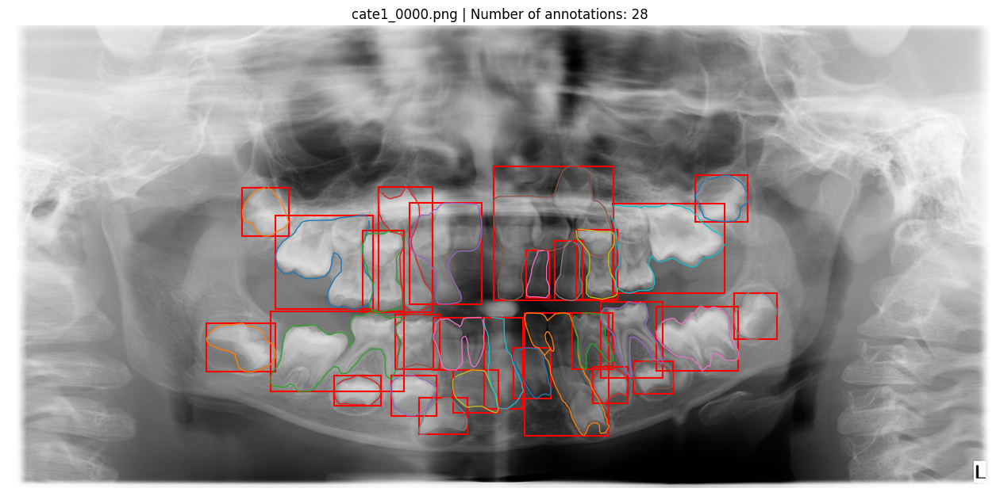

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import numpy as np
from pathlib import Path

# أول صورة في supplemental dataset
first_image_info = supp_annotation["images"][0]

image_id = first_image_info["id"]
image_name = first_image_info["file_name"]

image_path = supplemental / "images" / image_name

print("Image ID:", image_id)
print("Image name:", image_name)
print("Image path:", image_path)

# قراءة الصورة
img = Image.open(image_path)

# جميع annotations التابعة لهذه الصورة
image_annotations = [
    ann for ann in supp_annotation["annotations"]
    if ann["image_id"] == image_id
]

print("Number of annotations on this image:", len(image_annotations))

# العرض
fig, ax = plt.subplots(figsize=(16, 8))

ax.imshow(img, cmap="gray")

for ann in image_annotations:

    # Bounding box في COCO = x, y, width, height
    x, y, w, h = ann["bbox"]

    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    # Polygon segmentation
    if ann.get("segmentation"):
        for seg in ann["segmentation"]:

            points = np.array(seg).reshape(-1, 2)

            ax.plot(
                points[:, 0],
                points[:, 1],
                linewidth=1
            )

ax.set_title(
    f"{image_name} | Number of annotations: {len(image_annotations)}"
)

ax.axis("off")
plt.show()

In [ ]:
from pathlib import Path

def get_images(folder):
    extensions = {".png", ".jpg", ".jpeg", ".bmp"}

    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ])


detection_folder = (
    base /
    "Pediatric dental disease detection dataset"
)

supp_images_folder = (
    base /
    "Childrens dental caries segmentation dataset" /
    "Supplemental content93" /
    "images"
)

detection_images = get_images(detection_folder)
supp_images = get_images(supp_images_folder)

print("Detection images:", len(detection_images))
print("Supplemental images:", len(supp_images))
print("Total images:", len(detection_images) + len(supp_images))

Detection images: 100
Supplemental images: 93
Total images: 193


In [ ]:
import hashlib

def md5_hash(path):
    h = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)

    return h.hexdigest()


detection_md5 = {
    md5_hash(p): p
    for p in detection_images
}

supp_md5 = {
    md5_hash(p): p
    for p in supp_images
}

duplicates = set(detection_md5) & set(supp_md5)

print("Exact duplicate images:", len(duplicates))

for h in duplicates:
    print(
        detection_md5[h].name,
        "<->",
        supp_md5[h].name
    )

Exact duplicate images: 0


In [ ]:
!pip install -q ImageHash

from PIL import Image
import imagehash

def get_phash(path):
    with Image.open(path) as img:
        return imagehash.phash(img.convert("L"))


detection_phash = {
    p: get_phash(p)
    for p in detection_images
}

supp_phash = {
    p: get_phash(p)
    for p in supp_images
}

similar_pairs = []

for d_path, d_hash in detection_phash.items():

    for s_path, s_hash in supp_phash.items():

        distance = d_hash - s_hash

        if distance <= 5:
            similar_pairs.append(
                (d_path.name, s_path.name, distance)
            )

print(
    "Potential visually similar pairs:",
    len(similar_pairs)
)

for pair in sorted(similar_pairs, key=lambda x: x[2])[:30]:
    print(pair)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.5 MB/s eta 0:00:00
Potential visually similar pairs: 0


In [ ]:
from pathlib import Path
import shutil
import os

PROJECT_DIR = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

annotation_dir = PROJECT_DIR / "annotation_workspace"
annotation_images = annotation_dir / "images"

annotation_images.mkdir(parents=True, exist_ok=True)

print(annotation_images)

/content/drive/MyDrive/Pediatric_Caries_AI/annotation_workspace/images


In [ ]:
supp_images_folder = (
    base /
    "Childrens dental caries segmentation dataset" /
    "Supplemental content93" /
    "images"
)

image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

supp_images = sorted([
    p for p in supp_images_folder.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
])

print("Images found:", len(supp_images))

for image_path in supp_images:

    destination = annotation_images / image_path.name

    if not destination.exists():
        shutil.copy2(image_path, destination)

print("Images copied:", len(list(annotation_images.iterdir())))

Images found: 93
Images copied: 93


In [ ]:
import pandas as pd

records = []

for i, image_path in enumerate(
    sorted(annotation_images.iterdir()),
    start=1
):

    records.append({
        "study_id": f"SUPP_{i:03d}",
        "original_filename": image_path.name,
        "annotation_status": "Pending",
        "examiner_1": "",
        "examiner_2": "",
        "adjudication": ""
    })

manifest = pd.DataFrame(records)

manifest_path = annotation_dir / "supplemental_manifest.csv"

manifest.to_csv(
    manifest_path,
    index=False
)

manifest.head(10)

,study_id,original_filename,annotation_status,examiner_1,examiner_2,adjudication
0,SUPP_001,cate1_0000.png,Pending,,,
1,SUPP_002,cate1_0001.png,Pending,,,
2,SUPP_003,cate1_0002.png,Pending,,,
3,SUPP_004,cate1_0003.png,Pending,,,
4,SUPP_005,cate1_0004.png,Pending,,,
5,SUPP_006,cate1_0005.png,Pending,,,
6,SUPP_007,cate1_0006.png,Pending,,,
7,SUPP_008,cate1_0007.png,Pending,,,
8,SUPP_009,cate1_0008.png,Pending,,,
9,SUPP_010,cate1_0009.png,Pending,,,


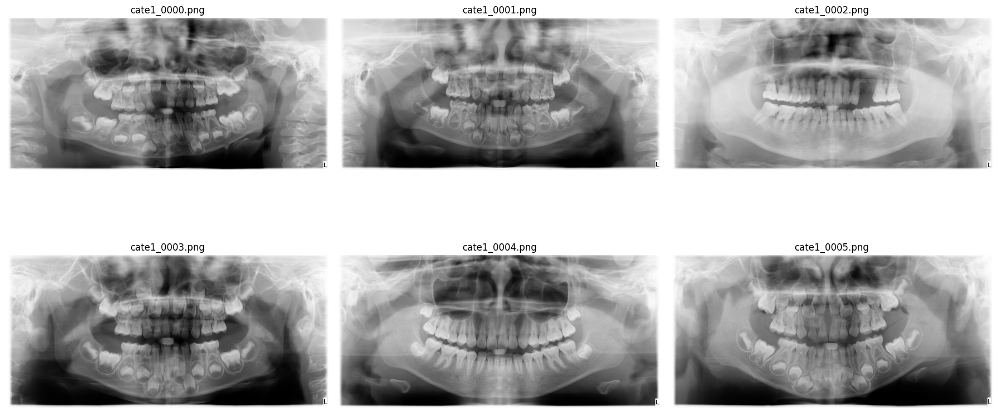

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

annotation_images = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/annotation_workspace/images"
)

# جميع الصور
image_files = sorted([
    p for p in annotation_images.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
])

# أول 6 صور
selected_images = image_files[:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, image_path in zip(axes.flatten(), selected_images):

    img = Image.open(image_path)

    ax.imshow(img, cmap="gray")
    ax.set_title(image_path.name, fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

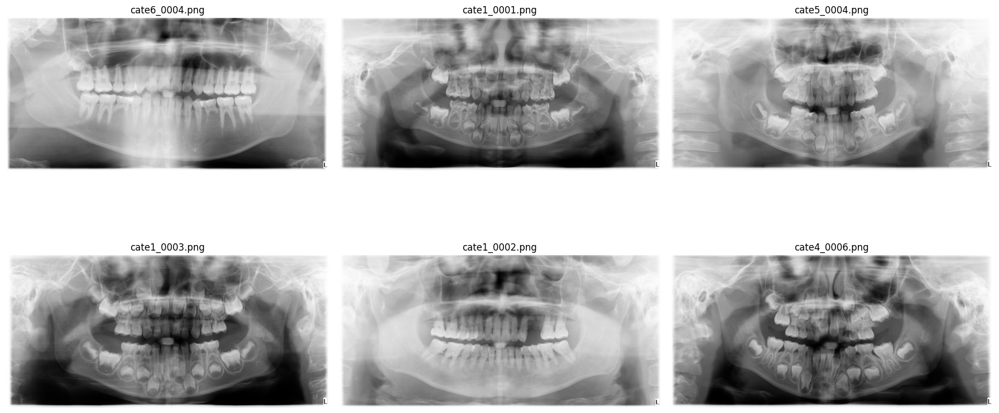

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

selected_images = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, image_path in zip(axes.flatten(), selected_images):

    img = Image.open(image_path)

    ax.imshow(img, cmap="gray")
    ax.set_title(image_path.name, fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import shutil
from pathlib import Path

annotation_images = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/annotation_workspace/images"
)

zip_output = (
    "/content/drive/MyDrive/Pediatric_Caries_AI/"
    "annotation_workspace/supplemental_93_images"
)

shutil.make_archive(
    zip_output,
    "zip",
    annotation_images
)

print("ZIP created:")
print(zip_output + ".zip")

ZIP created:
/content/drive/MyDrive/Pediatric_Caries_AI/annotation_workspace/supplemental_93_images.zip


In [ ]:
from pathlib import Path
import os

PROJECT_DIR = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

YOLO_DIR = PROJECT_DIR / "processed_data" / "yolo_caries_baseline"

for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Dataset directory created:")
print(YOLO_DIR)

Dataset directory created:
/content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline


In [ ]:
import json
from sklearn.model_selection import train_test_split

detection_base = (
    base /
    "Pediatric dental disease detection dataset"
)

original_train = detection_base / "Train"
original_test = detection_base / "Test"


def collect_cases(folder):

    cases = []

    for json_file in sorted(folder.rglob("*.json")):

        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        has_caries = any(
            str(shape.get("label", "")).strip() == "龋齿"
            for shape in data.get("shapes", [])
        )

        cases.append({
            "json": json_file,
            "has_caries": has_caries
        })

    return cases


development_cases = collect_cases(original_train)

print("Development images:", len(development_cases))
print(
    "Caries-positive:",
    sum(c["has_caries"] for c in development_cases)
)
print(
    "Caries-negative:",
    sum(not c["has_caries"] for c in development_cases)
)

Development images: 70
Caries-positive: 0
Caries-negative: 70


In [ ]:
train_cases, val_cases = train_test_split(
    development_cases,
    test_size=0.20,
    random_state=42,
    stratify=[
        c["has_caries"]
        for c in development_cases
    ]
)

print("Training:", len(train_cases))
print("Validation:", len(val_cases))

print(
    "Train positive:",
    sum(c["has_caries"] for c in train_cases)
)

print(
    "Validation positive:",
    sum(c["has_caries"] for c in val_cases)
)

Training: 56
Validation: 14
Train positive: 0
Validation positive: 0


In [ ]:
import shutil
from PIL import Image


CARIES_LABEL = "龋病"
CLASS_ID = 0


def find_image(json_file, data):

    image_name = Path(data["imagePath"]).name

    # البحث داخل نفس الـsplit
    candidates = list(
        json_file.parent.parent.rglob(image_name)
    )

    if candidates:
        return candidates[0]

    # بديل بالـstem
    for ext in [".png", ".jpg", ".jpeg", ".bmp"]:
        candidates = list(
            json_file.parent.parent.rglob(
                Path(image_name).stem + ext
            )
        )

        if candidates:
            return candidates[0]

    return None


def convert_case(case, split):

    json_file = case["json"]

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_path = find_image(json_file, data)

    if image_path is None:
        print("❌ Image not found:", json_file)
        return 0

    image_width = data.get("imageWidth")
    image_height = data.get("imageHeight")

    if not image_width or not image_height:

        with Image.open(image_path) as img:
            image_width, image_height = img.size

    # نسخ الصورة
    destination_image = (
        YOLO_DIR /
        "images" /
        split /
        image_path.name
    )

    shutil.copy2(
        image_path,
        destination_image
    )

    yolo_lines = []

    for shape in data.get("shapes", []):

        label = str(
            shape.get("label", "")
        ).strip()

        if label != CARIES_LABEL:
            continue

        points = shape.get("points", [])

        if len(points) < 2:
            continue

        x1 = min(points[0][0], points[1][0])
        y1 = min(points[0][1], points[1][1])

        x2 = max(points[0][0], points[1][0])
        y2 = max(points[0][1], points[1][1])

        box_width = x2 - x1
        box_height = y2 - y1

        x_center = (x1 + x2) / 2
        y_center = (y1 + y2) / 2

        # Normalize 0–1
        x_center /= image_width
        y_center /= image_height

        box_width /= image_width
        box_height /= image_height

        # حماية إضافية
        x_center = max(0, min(1, x_center))
        y_center = max(0, min(1, y_center))

        box_width = max(0, min(1, box_width))
        box_height = max(0, min(1, box_height))

        yolo_lines.append(
            f"{CLASS_ID} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

    label_path = (
        YOLO_DIR /
        "labels" /
        split /
        f"{image_path.stem}.txt"
    )

    with open(label_path, "w") as f:
        f.write("\n".join(yolo_lines))

    return len(yolo_lines)

In [ ]:
import json

sample_json = train_cases[0]["json"]

with open(sample_json, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

print("JSON file:")
print(sample_json)

print("\nimagePath stored inside JSON:")
print(sample_data["imagePath"])

JSON file:
/kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Train/label/cate2_012.json

imagePath stored inside JSON:
cate2_012.png


In [ ]:
def find_image(json_file, data):

    # إصلاح مسارات Windows داخل JSON
    raw_image_path = str(data.get("imagePath", ""))

    image_name = raw_image_path.replace("\\", "/").split("/")[-1]

    # البحث في كامل مجلد Train أو Test
    split_folder = json_file

    while split_folder.name not in ["Train", "Test"]:
        split_folder = split_folder.parent

    # البحث بالاسم الكامل
    matches = list(split_folder.rglob(image_name))

    if matches:
        return matches[0]

    # البحث بالـ stem إذا كان الامتداد مختلفًا
    image_stem = Path(image_name).stem

    valid_extensions = [".png", ".jpg", ".jpeg", ".bmp"]

    for ext in valid_extensions:

        matches = list(
            split_folder.rglob(image_stem + ext)
        )

        if matches:
            return matches[0]

    # محاولة أخيرة باستخدام اسم JSON نفسه
    json_stem = json_file.stem

    for ext in valid_extensions:

        matches = list(
            split_folder.rglob(json_stem + ext)
        )

        if matches:
            return matches[0]

    return None

In [ ]:
import shutil

for split in ["train", "val", "test"]:

    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    if image_dir.exists():
        shutil.rmtree(image_dir)

    if label_dir.exists():
        shutil.rmtree(label_dir)

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

print("✅ Old conversion files cleared.")

✅ Old conversion files cleared.


In [ ]:
test_case = train_cases[0]

with open(test_case["json"], "r", encoding="utf-8") as f:
    test_data = json.load(f)

found_image = find_image(
    test_case["json"],
    test_data
)

print("JSON:")
print(test_case["json"])

print("\nImage found:")
print(found_image)

JSON:
/kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Train/label/cate2_012.json

Image found:
/kaggle/input/childrens-dental-panoramic-radiographs-dataset/Dental_dataset/Pediatric dental disease detection dataset/Train/images/cate2_012.png


In [ ]:
train_boxes = 0
val_boxes = 0

for case in train_cases:
    train_boxes += convert_case(case, "train")

for case in val_cases:
    val_boxes += convert_case(case, "val")

print("Training caries boxes:", train_boxes)
print("Validation caries boxes:", val_boxes)
print("Total development caries boxes:", train_boxes + val_boxes)

Training caries boxes: 180
Validation caries boxes: 26
Total development caries boxes: 206


In [ ]:
import json

all_labels = set()

for case in development_cases:

    with open(case["json"], "r", encoding="utf-8") as f:
        data = json.load(f)

    for shape in data.get("shapes", []):
        all_labels.add(
            str(shape.get("label", "")).strip()
        )

print("Labels found:")

for label in sorted(all_labels):
    print(repr(label))

Labels found:
'其他'
'根尖周炎'
'深窝沟'
'牙髓炎'
'牙齿发育异常'
'龋病'


In [ ]:
sample_case = train_cases[0]

with open(sample_case["json"], "r", encoding="utf-8") as f:
    sample_data = json.load(f)

print("Labels in this image:")

for shape in sample_data.get("shapes", []):
    print(repr(shape["label"]))

Labels in this image:
'牙齿发育异常'
'牙齿发育异常'
'牙齿发育异常'


In [ ]:
import shutil

for split in ["train", "val"]:

    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    if image_dir.exists():
        shutil.rmtree(image_dir)

    if label_dir.exists():
        shutil.rmtree(label_dir)

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

print("✅ Train and validation folders cleared")

✅ Train and validation folders cleared


In [ ]:
train_boxes = 0
val_boxes = 0

for case in train_cases:
    train_boxes += convert_case(
        case,
        "train"
    )

for case in val_cases:
    val_boxes += convert_case(
        case,
        "val"
    )

print("Training caries boxes:", train_boxes)
print("Validation caries boxes:", val_boxes)
print(
    "Total development caries boxes:",
    train_boxes + val_boxes
)

Training caries boxes: 180
Validation caries boxes: 26
Total development caries boxes: 206


In [ ]:
test_cases = collect_cases(original_test)

test_boxes = 0

for case in test_cases:
    test_boxes += convert_case(case, "test")

print("Test images:", len(test_cases))
print("Test caries boxes:", test_boxes)

Test images: 30
Test caries boxes: 108


In [ ]:
for split in ["train", "val", "test"]:

    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    image_count = len([
        f for f in image_dir.iterdir()
        if f.is_file()
    ])

    label_files = list(label_dir.glob("*.txt"))

    positive_images = 0
    total_boxes = 0

    for label_file in label_files:

        content = label_file.read_text().strip()

        if content:
            positive_images += 1
            total_boxes += len(content.splitlines())

    print("\n" + "="*40)
    print(split.upper())
    print("="*40)

    print("Images:", image_count)
    print("Label files:", len(label_files))
    print("Caries-positive images:", positive_images)
    print("Caries boxes:", total_boxes)


TRAIN
Images: 56
Label files: 56
Caries-positive images: 40
Caries boxes: 180

VAL
Images: 14
Label files: 14
Caries-positive images: 9
Caries boxes: 26

TEST
Images: 30
Label files: 30
Caries-positive images: 24
Caries boxes: 108


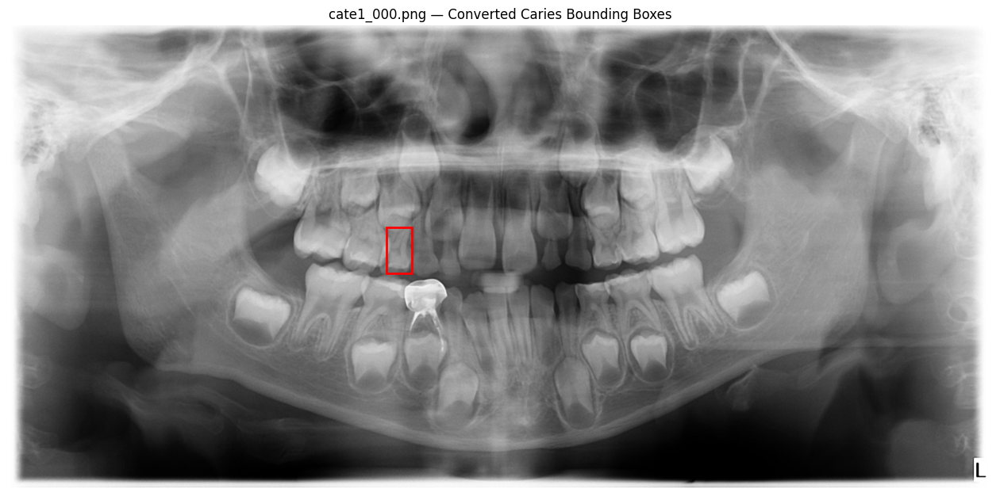

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# نختار أول صورة positive من train
label_files = sorted(
    (YOLO_DIR / "labels" / "train").glob("*.txt")
)

positive_label = None

for lf in label_files:
    if lf.read_text().strip():
        positive_label = lf
        break

image_path = None

for ext in [".png", ".jpg", ".jpeg", ".bmp"]:
    candidate = (
        YOLO_DIR /
        "images" /
        "train" /
        (positive_label.stem + ext)
    )

    if candidate.exists():
        image_path = candidate
        break

img = Image.open(image_path)

W, H = img.size

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(img, cmap="gray")

with open(positive_label, "r") as f:

    for line in f:

        cls, xc, yc, bw, bh = map(float, line.split())

        xc *= W
        yc *= H
        bw *= W
        bh *= H

        x1 = xc - bw / 2
        y1 = yc - bh / 2

        rect = patches.Rectangle(
            (x1, y1),
            bw,
            bh,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

ax.set_title(
    f"{image_path.name} — Converted Caries Bounding Boxes"
)

ax.axis("off")
plt.show()

Selected label: cate1_000.txt
Selected image: cate1_000.png
Image size: 2000 x 942
Number of caries boxes: 1


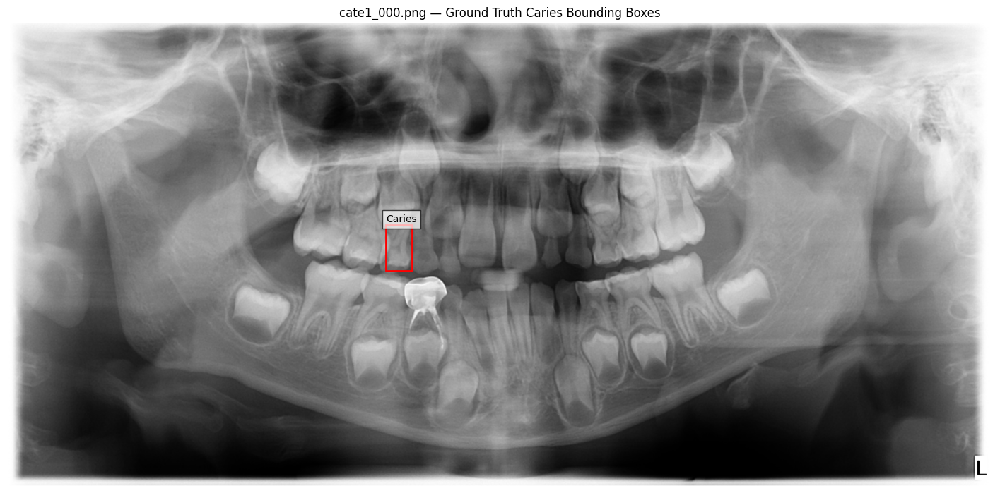

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# اختيار أول صورة Train تحتوي على caries
label_files = sorted(
    (YOLO_DIR / "labels" / "train").glob("*.txt")
)

positive_label = None

for lf in label_files:
    if lf.read_text().strip():
        positive_label = lf
        break

print("Selected label:", positive_label.name)

# العثور على الصورة المقابلة
image_path = None

for ext in [".png", ".jpg", ".jpeg", ".bmp"]:

    candidate = (
        YOLO_DIR /
        "images" /
        "train" /
        f"{positive_label.stem}{ext}"
    )

    if candidate.exists():
        image_path = candidate
        break

print("Selected image:", image_path.name)

# قراءة الصورة
img = Image.open(image_path)

W, H = img.size

print("Image size:", W, "x", H)

# عرض الصورة
fig, ax = plt.subplots(figsize=(18, 9))

ax.imshow(img, cmap="gray")

# قراءة YOLO boxes
with open(positive_label, "r") as f:

    lines = f.readlines()

print("Number of caries boxes:", len(lines))

for line in lines:

    cls, xc, yc, bw, bh = map(
        float,
        line.strip().split()
    )

    # تحويل normalized coordinates إلى pixels
    xc *= W
    yc *= H
    bw *= W
    bh *= H

    x1 = xc - bw / 2
    y1 = yc - bh / 2

    rect = patches.Rectangle(
        (x1, y1),
        bw,
        bh,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1 - 5,
        "Caries",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.7)
    )

ax.set_title(
    f"{image_path.name} — Ground Truth Caries Bounding Boxes"
)

ax.axis("off")
plt.show()

In [ ]:
errors = []

for split in ["train", "val", "test"]:

    label_dir = YOLO_DIR / "labels" / split

    for label_file in label_dir.glob("*.txt"):

        lines = label_file.read_text().strip().splitlines()

        for line_number, line in enumerate(lines, start=1):

            if not line.strip():
                continue

            parts = line.split()

            if len(parts) != 5:
                errors.append(
                    f"{label_file.name} line {line_number}: wrong format"
                )
                continue

            cls, xc, yc, w, h = map(float, parts)

            if cls != 0:
                errors.append(
                    f"{label_file.name}: unexpected class {cls}"
                )

            if not (
                0 <= xc <= 1 and
                0 <= yc <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                errors.append(
                    f"{label_file.name} line {line_number}: invalid coordinates"
                )


if len(errors) == 0:
    print("✅ All YOLO annotations are valid.")
else:
    print("❌ Problems found:", len(errors))

    for error in errors[:20]:
        print(error)

✅ All YOLO annotations are valid.


In [ ]:
yaml_content = f"""
path: {YOLO_DIR}

train: images/train
val: images/val
test: images/test

names:
  0: caries
"""

yaml_path = YOLO_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print(yaml_path.read_text())


path: /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline

train: images/train
val: images/val
test: images/test

names:
  0: caries



In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("✅ YOLO11s loaded successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
✅ YOLO11s loaded successfully


In [ ]:
results = model.train(
    data=str(yaml_path),

    epochs=100,
    imgsz=1024,

    batch=-1,

    patience=20,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    project=str(
        PROJECT_DIR / "models"
    ),

    name="YOLO11s_Caries_Baseline",

    # Mild augmentation
    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic

In [ ]:
from pathlib import Path

best_model_path = (
    Path(PROJECT_DIR)
    / "models"
    / "YOLO11s_Caries_Baseline"
    / "weights"
    / "best.pt"
)

print("Best model:")
print(best_model_path)

print("\nExists:", best_model_path.exists())

Best model:
/content/drive/MyDrive/Pediatric_Caries_AI/models/YOLO11s_Caries_Baseline/weights/best.pt

Exists: True


In [ ]:
from ultralytics import YOLO

best_model = YOLO(str(best_model_path))

print("✅ Best trained model loaded")

✅ Best trained model loaded


In [ ]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=1024,
    device=0,
    plots=True,
    save_json=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 251.9±117.8 MB/s, size: 986.8 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/labels/test.cache... 30 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 7.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4s/it 2.8s
                   all         30        108        0.4       0.63      0.471      0.226
Speed: 7.8ms preprocess, 15.3ms inference, 0.0ms loss, 3.0ms postprocess per image
Saving /content/runs/detect/val/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 262ms
P

In [ ]:
print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print("Precision :", test_metrics.box.mp)
print("Recall    :", test_metrics.box.mr)
print("mAP@0.50  :", test_metrics.box.map50)
print("mAP@0.50:0.95 :", test_metrics.box.map)

FINAL TEST RESULTS
Precision : 0.4001767149338945
Recall    : 0.6296296296296297
mAP@0.50  : 0.47055436926274086
mAP@0.50:0.95 : 0.22643935851058927


In [ ]:
from ultralytics import YOLO
from pathlib import Path

# أفضل موديل
best_model_path = (
    Path(PROJECT_DIR)
    / "models"
    / "YOLO11s_Caries_Baseline"
    / "weights"
    / "best.pt"
)

best_model = YOLO(str(best_model_path))

# صور الاختبار
test_images = sorted([
    p for p in (YOLO_DIR / "images" / "test").iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
])

print("Number of test images:", len(test_images))

# أول 6 صور
six_images = test_images[:6]

for image in six_images:
    print(image.name)

Number of test images: 30
cate1_000.png
cate1_001.png
cate1_002.png
cate1_003.png
cate1_004.png
cate1_005.png


In [ ]:
prediction_results = best_model.predict(
    source=[str(p) for p in six_images],

    imgsz=1024,

    conf=0.25,

    iou=0.50,

    device=0,

    save=True,

    project=str(
        Path(PROJECT_DIR) / "results"
    ),

    name="YOLO11s_test_6_images"
)


0: 512x1024 (no detections), 14.6ms
1: 512x1024 (no detections), 14.6ms
2: 512x1024 (no detections), 14.6ms
3: 512x1024 (no detections), 14.6ms
4: 512x1024 2 cariess, 14.6ms
5: 512x1024 (no detections), 14.6ms
Speed: 3.2ms preprocess, 14.6ms inference, 0.4ms postprocess per image at shape (1, 3, 512, 1024)
Results saved to /content/drive/MyDrive/Pediatric_Caries_AI/results/YOLO11s_test_6_images-3


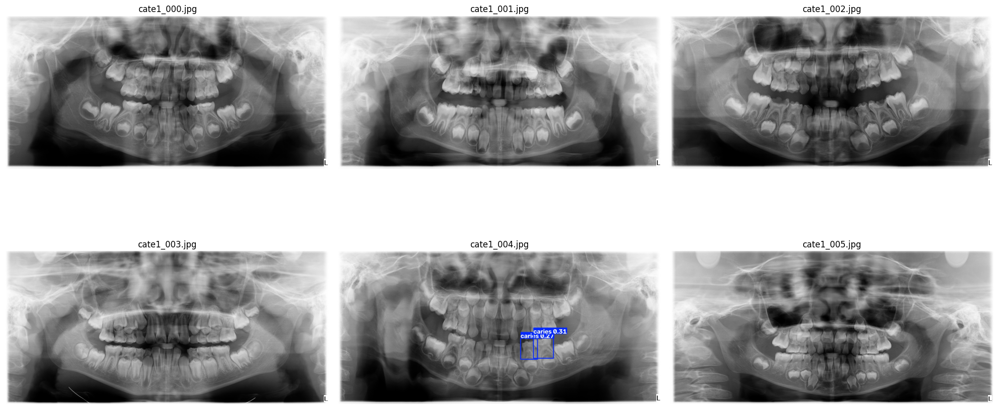

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

prediction_folder = (
    Path(PROJECT_DIR)
    / "results"
    / "YOLO11s_test_6_images"
)

predicted_images = sorted([
    p for p in prediction_folder.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 11)
)

for ax, image_path in zip(
    axes.flatten(),
    predicted_images[:6]
):

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

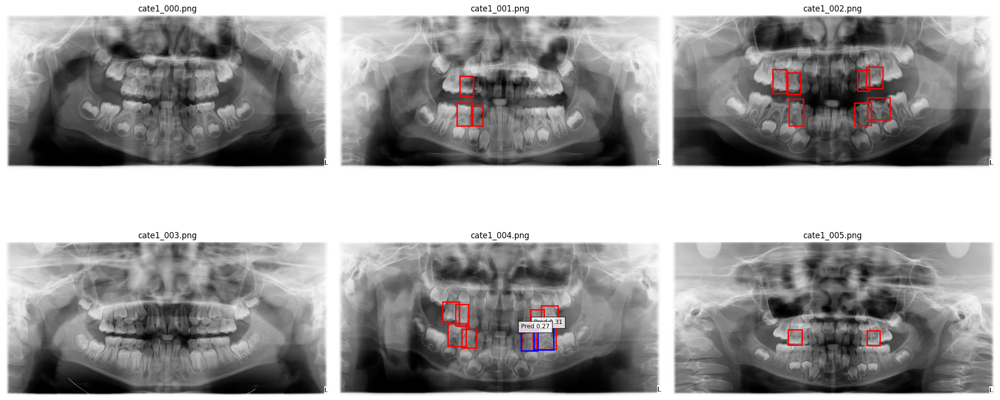

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# نفس أول 6 صور Test
six_images = test_images[:6]

fig, axes = plt.subplots(2, 3, figsize=(21, 11))

for ax, image_path in zip(axes.flatten(), six_images):

    img = Image.open(image_path)
    W, H = img.size

    ax.imshow(img, cmap="gray")

    # =========================================================
    # 1. Ground Truth = RED
    # =========================================================

    gt_label = (
        YOLO_DIR /
        "labels" /
        "test" /
        f"{image_path.stem}.txt"
    )

    if gt_label.exists():

        lines = gt_label.read_text().strip().splitlines()

        for line in lines:

            if not line.strip():
                continue

            cls, xc, yc, bw, bh = map(float, line.split())

            xc *= W
            yc *= H
            bw *= W
            bh *= H

            x1 = xc - bw / 2
            y1 = yc - bh / 2

            rect = patches.Rectangle(
                (x1, y1),
                bw,
                bh,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

    # =========================================================
    # 2. Model prediction = BLUE
    # =========================================================

    prediction = best_model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=0.25,
        iou=0.50,
        device=0,
        verbose=False
    )[0]

    if prediction.boxes is not None:

        for box in prediction.boxes:

            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            confidence = float(box.conf[0])

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor="blue",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                max(0, y1 - 8),
                f"Pred {confidence:.2f}",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.8
                )
            )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from pathlib import Path
from PIL import Image


def yolo_gt_to_xyxy(label_path, W, H):

    boxes = []

    if not label_path.exists():
        return boxes

    content = label_path.read_text().strip()

    if not content:
        return boxes

    for line in content.splitlines():

        cls, xc, yc, bw, bh = map(float, line.split())

        xc *= W
        yc *= H
        bw *= W
        bh *= H

        x1 = xc - bw / 2
        y1 = yc - bh / 2
        x2 = xc + bw / 2
        y2 = yc + bh / 2

        boxes.append(
            [x1, y1, x2, y2]
        )

    return boxes


def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0]) *
        (box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0

    return intersection / union

In [ ]:
IOU_THRESHOLD = 0.50
CONF_THRESHOLD = 0.25

for image_path in six_images:

    img = Image.open(image_path)
    W, H = img.size

    label_path = (
        YOLO_DIR /
        "labels" /
        "test" /
        f"{image_path.stem}.txt"
    )

    gt_boxes = yolo_gt_to_xyxy(
        label_path,
        W,
        H
    )

    prediction = best_model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=CONF_THRESHOLD,
        iou=0.50,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    if prediction.boxes is not None:

        for box in prediction.boxes:

            coords = (
                box.xyxy[0]
                .cpu()
                .numpy()
                .tolist()
            )

            pred_boxes.append(coords)

    matched_gt = set()

    TP = 0
    FP = 0

    for pred_box in pred_boxes:

        best_iou = 0
        best_gt_index = None

        for gt_index, gt_box in enumerate(gt_boxes):

            if gt_index in matched_gt:
                continue

            iou = calculate_iou(
                pred_box,
                gt_box
            )

            if iou > best_iou:

                best_iou = iou
                best_gt_index = gt_index

        if (
            best_iou >= IOU_THRESHOLD
            and best_gt_index is not None
        ):

            TP += 1
            matched_gt.add(best_gt_index)

        else:
            FP += 1

    FN = len(gt_boxes) - len(matched_gt)

    print("\n", image_path.name)
    print("GT boxes :", len(gt_boxes))
    print("Predicted:", len(pred_boxes))
    print("TP:", TP)
    print("FP:", FP)
    print("FN:", FN)


 cate1_000.png
GT boxes : 0
Predicted: 0
TP: 0
FP: 0
FN: 0

 cate1_001.png
GT boxes : 3
Predicted: 0
TP: 0
FP: 0
FN: 3

 cate1_002.png
GT boxes : 7
Predicted: 0
TP: 0
FP: 0
FN: 7

 cate1_003.png
GT boxes : 0
Predicted: 0
TP: 0
FP: 0
FN: 0

 cate1_004.png
GT boxes : 8
Predicted: 2
TP: 2
FP: 0
FN: 6

 cate1_005.png
GT boxes : 2
Predicted: 0
TP: 0
FP: 0
FN: 2


In [ ]:
import pandas as pd
from PIL import Image

val_images = sorted([
    p for p in (YOLO_DIR / "images" / "val").iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
])

thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]

IOU_THRESHOLD = 0.50

threshold_results = []

for conf_threshold in thresholds:

    total_TP = 0
    total_FP = 0
    total_FN = 0

    for image_path in val_images:

        img = Image.open(image_path)
        W, H = img.size

        # Ground Truth
        label_path = (
            YOLO_DIR /
            "labels" /
            "val" /
            f"{image_path.stem}.txt"
        )

        gt_boxes = yolo_gt_to_xyxy(
            label_path,
            W,
            H
        )

        # Predictions
        prediction = best_model.predict(
            source=str(image_path),
            imgsz=1024,
            conf=conf_threshold,
            iou=0.50,
            device=0,
            verbose=False
        )[0]

        pred_boxes = []

        if prediction.boxes is not None:

            for box in prediction.boxes:

                coords = (
                    box.xyxy[0]
                    .cpu()
                    .numpy()
                    .tolist()
                )

                pred_boxes.append(coords)

        matched_gt = set()

        TP = 0
        FP = 0

        for pred_box in pred_boxes:

            best_iou = 0
            best_gt_index = None

            for gt_index, gt_box in enumerate(gt_boxes):

                if gt_index in matched_gt:
                    continue

                iou = calculate_iou(
                    pred_box,
                    gt_box
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = gt_index

            if (
                best_iou >= IOU_THRESHOLD
                and best_gt_index is not None
            ):
                TP += 1
                matched_gt.add(best_gt_index)

            else:
                FP += 1

        FN = len(gt_boxes) - len(matched_gt)

        total_TP += TP
        total_FP += FP
        total_FN += FN

    precision = (
        total_TP / (total_TP + total_FP)
        if (total_TP + total_FP) > 0
        else 0
    )

    recall = (
        total_TP / (total_TP + total_FN)
        if (total_TP + total_FN) > 0
        else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    threshold_results.append({
        "Confidence": conf_threshold,
        "TP": total_TP,
        "FP": total_FP,
        "FN": total_FN,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })


threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.to_string(index=False))

 Confidence  TP  FP  FN  Precision   Recall       F1
       0.05  17 109   9   0.134921 0.653846 0.223684
       0.10  14  61  12   0.186667 0.538462 0.277228
       0.15  11  36  15   0.234043 0.423077 0.301370
       0.20   9  20  17   0.310345 0.346154 0.327273
       0.25   6  12  20   0.333333 0.230769 0.272727
       0.30   3   7  23   0.300000 0.115385 0.166667
       0.40   0   1  26   0.000000 0.000000 0.000000
       0.50   0   0  26   0.000000 0.000000 0.000000


In [ ]:
import pandas as pd
import numpy as np
from PIL import Image

box_records = []

# فقط Train + Validation
for split in ["train", "val"]:

    image_dir = YOLO_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    for image_path in image_dir.iterdir():

        if image_path.suffix.lower() not in [
            ".png", ".jpg", ".jpeg", ".bmp"
        ]:
            continue

        img = Image.open(image_path)
        W, H = img.size

        label_path = (
            label_dir /
            f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            continue

        content = label_path.read_text().strip()

        if not content:
            continue

        for line in content.splitlines():

            cls, xc, yc, bw, bh = map(
                float,
                line.split()
            )

            # الحجم الفعلي بالبكسل
            box_w_px = bw * W
            box_h_px = bh * H

            box_area_px = (
                box_w_px * box_h_px
            )

            image_area = W * H

            area_percent = (
                box_area_px /
                image_area
            ) * 100

            box_records.append({
                "split": split,
                "image": image_path.name,
                "box_width_px": box_w_px,
                "box_height_px": box_h_px,
                "box_area_px": box_area_px,
                "area_percent": area_percent
            })


box_df = pd.DataFrame(box_records)

print("Number of development boxes:", len(box_df))

print("\nBOX WIDTH (pixels)")
print(box_df["box_width_px"].describe())

print("\nBOX HEIGHT (pixels)")
print(box_df["box_height_px"].describe())

print("\nBOX AREA AS % OF PANORAMIC IMAGE")
print(box_df["area_percent"].describe())

Number of development boxes: 206

BOX WIDTH (pixels)
count    206.000000
mean      84.779291
std       25.405920
min       39.760000
25%       66.266000
50%       81.552000
75%      103.011500
max      167.470000
Name: box_width_px, dtype: float64

BOX HEIGHT (pixels)
count    206.000000
mean     126.110149
std       24.162110
min       77.108352
25%      109.638438
50%      124.096254
75%      138.554070
max      231.325056
Name: box_height_px, dtype: float64

BOX AREA AS % OF PANORAMIC IMAGE
count    206.000000
mean       0.583536
std        0.266415
min        0.217896
25%        0.388058
50%        0.528087
75%        0.696037
max        1.612473
Name: area_percent, dtype: float64


In [ ]:
    print("\nCaries box size distribution:")

print(
    "Boxes occupying <0.10% of image:",
    (box_df["area_percent"] < 0.10).sum()
)

print(
    "Boxes occupying <0.25% of image:",
    (box_df["area_percent"] < 0.25).sum()
)

print(
    "Boxes occupying <0.50% of image:",
    (box_df["area_percent"] < 0.50).sum()
)

print(
    "Boxes occupying >=0.50% of image:",
    (box_df["area_percent"] >= 0.50).sum()
)


Caries box size distribution:
Boxes occupying <0.10% of image: 0
Boxes occupying <0.25% of image: 4
Boxes occupying <0.50% of image: 91
Boxes occupying >=0.50% of image: 115


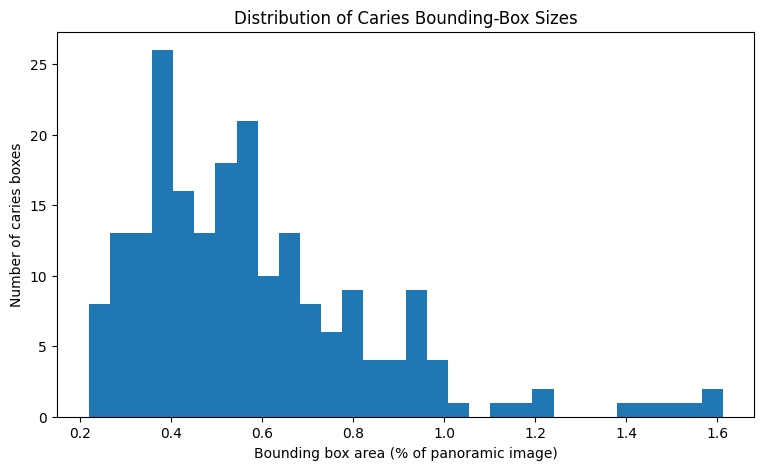

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    box_df["area_percent"],
    bins=30
)

plt.xlabel(
    "Bounding box area (% of panoramic image)"
)

plt.ylabel(
    "Number of caries boxes"
)

plt.title(
    "Distribution of Caries Bounding-Box Sizes"
)

plt.show()

In [ ]:
from pathlib import Path
import pandas as pd

results_csv = (
    Path(PROJECT_DIR)
    / "models"
    / "YOLO11s_Caries_Baseline"
    / "results.csv"
)

print("Exists:", results_csv.exists())
print(results_csv)

Exists: True
/content/drive/MyDrive/Pediatric_Caries_AI/models/YOLO11s_Caries_Baseline/results.csv


In [ ]:
training_history = pd.read_csv(results_csv)

training_history.columns = [
    c.strip()
    for c in training_history.columns
]

print("Number of completed epochs:", len(training_history))

print("\nColumns:")
for col in training_history.columns:
    print(col)

Number of completed epochs: 80

Columns:
epoch
time
train/box_loss
train/cls_loss
train/dfl_loss
metrics/precision(B)
metrics/recall(B)
metrics/mAP50(B)
metrics/mAP50-95(B)
val/box_loss
val/cls_loss
val/dfl_loss
lr/pg0
lr/pg1
lr/pg2


In [ ]:
map50_col = "metrics/mAP50(B)"
map_col = "metrics/mAP50-95(B)"
precision_col = "metrics/precision(B)"
recall_col = "metrics/recall(B)"

best_index = training_history[map_col].idxmax()

best_epoch = training_history.loc[best_index]

print("=" * 60)
print("BEST VALIDATION EPOCH")
print("=" * 60)

print("Epoch:", int(best_epoch["epoch"]) + 1)
print("Precision:", best_epoch[precision_col])
print("Recall:", best_epoch[recall_col])
print("mAP50:", best_epoch[map50_col])
print("mAP50-95:", best_epoch[map_col])

BEST VALIDATION EPOCH
Epoch: 61
Precision: 0.22483
Recall: 0.45743
mAP50: 0.26185
mAP50-95: 0.15916


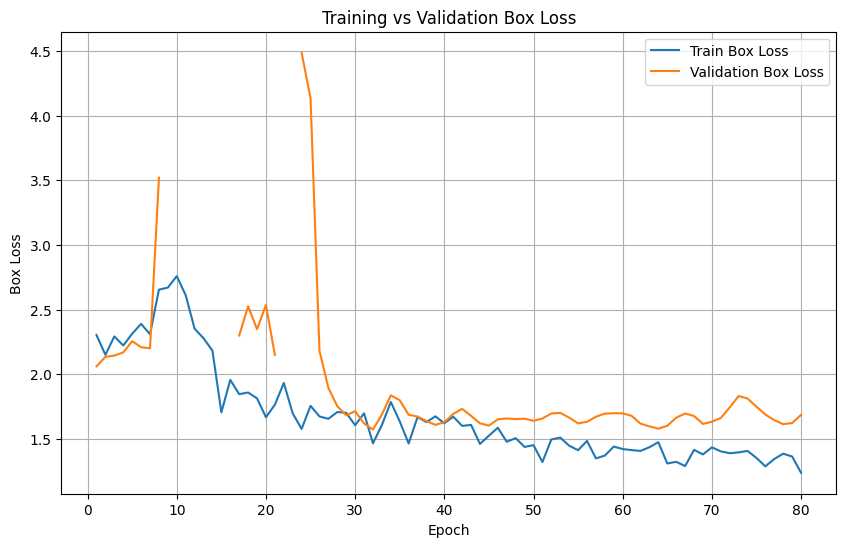

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    training_history["epoch"],
    training_history["train/box_loss"],
    label="Train Box Loss"
)

plt.plot(
    training_history["epoch"],
    training_history["val/box_loss"],
    label="Validation Box Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Training vs Validation Box Loss")
plt.legend()
plt.grid(True)

plt.show()

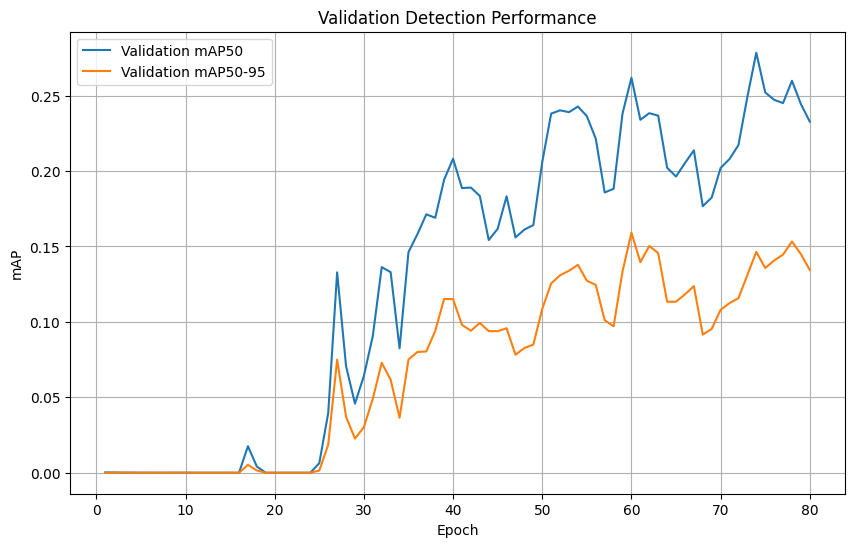

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    training_history["epoch"],
    training_history["metrics/mAP50(B)"],
    label="Validation mAP50"
)

plt.plot(
    training_history["epoch"],
    training_history["metrics/mAP50-95(B)"],
    label="Validation mAP50-95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation Detection Performance")
plt.legend()
plt.grid(True)

plt.show()

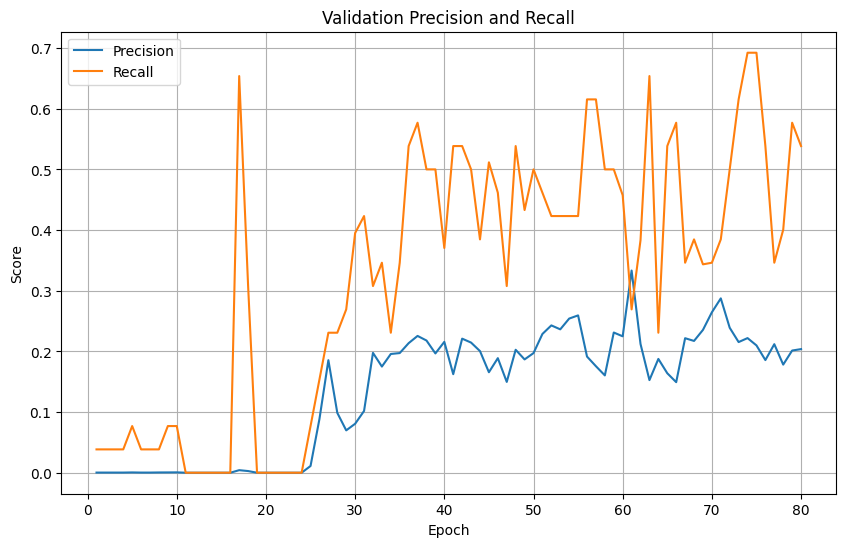

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    training_history["epoch"],
    training_history["metrics/precision(B)"],
    label="Precision"
)

plt.plot(
    training_history["epoch"],
    training_history["metrics/recall(B)"],
    label="Recall"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Precision and Recall")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
metric = "metrics/mAP50-95(B)"

best_index = training_history[metric].idxmax()
best_row = training_history.loc[best_index]

print("=" * 60)
print("YOLO11s BASELINE - BEST VALIDATION EPOCH")
print("=" * 60)

print("Epoch       :", int(best_row["epoch"]) + 1)
print("Precision   :", best_row["metrics/precision(B)"])
print("Recall      :", best_row["metrics/recall(B)"])
print("mAP50       :", best_row["metrics/mAP50(B)"])
print("mAP50-95    :", best_row["metrics/mAP50-95(B)"])
print("Train box loss:", best_row["train/box_loss"])
print("Val box loss  :", best_row["val/box_loss"])

YOLO11s BASELINE - BEST VALIDATION EPOCH
Epoch       : 61
Precision   : 0.22483
Recall      : 0.45743
mAP50       : 0.26185
mAP50-95    : 0.15916
Train box loss: 1.42101
Val box loss  : 1.697


In [ ]:
import json
import pandas as pd
from pathlib import Path

records = []

for case in development_cases:

    json_file = case["json"]

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    caries_boxes = sum(
        1
        for shape in data.get("shapes", [])
        if str(shape.get("label", "")).strip() == CARIES_LABEL
    )

    records.append({
        "json_path": str(json_file),
        "image_name": Path(data["imagePath"]).name,
        "has_caries": int(caries_boxes > 0),
        "caries_boxes": caries_boxes
    })

dev_df = pd.DataFrame(records)

print("Development images:", len(dev_df))
print("Positive images:", dev_df["has_caries"].sum())
print("Negative images:", (dev_df["has_caries"] == 0).sum())
print("Total caries boxes:", dev_df["caries_boxes"].sum())

dev_df.head()

Development images: 70
Positive images: 49
Negative images: 21
Total caries boxes: 206


,json_path,image_name,has_caries,caries_boxes
0,/kaggle/input/childrens-dental-panoramic-radio...,..\cate1_000.png,1,1
1,/kaggle/input/childrens-dental-panoramic-radio...,cate1_001.png,0,0
2,/kaggle/input/childrens-dental-panoramic-radio...,cate1_002.png,1,1
3,/kaggle/input/childrens-dental-panoramic-radio...,cate1_003.png,0,0
4,/kaggle/input/childrens-dental-panoramic-radio...,cate1_004.png,1,2


In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dev_df["fold"] = -1

for fold_number, (_, val_idx) in enumerate(
    skf.split(dev_df, dev_df["has_caries"]),
    start=1
):
    dev_df.loc[val_idx, "fold"] = fold_number

print(dev_df["fold"].value_counts().sort_index())

fold
1    14
2    14
3    14
4    14
5    14
Name: count, dtype: int64


In [ ]:
for fold in range(1, 6):

    val_fold = dev_df[
        dev_df["fold"] == fold
    ]

    train_fold = dev_df[
        dev_df["fold"] != fold
    ]

    print("\n" + "="*60)
    print(f"FOLD {fold}")
    print("="*60)

    print("TRAIN")
    print("Images:", len(train_fold))
    print("Positive:", train_fold["has_caries"].sum())
    print("Negative:", (train_fold["has_caries"] == 0).sum())
    print("Caries boxes:", train_fold["caries_boxes"].sum())

    print("\nVALIDATION")
    print("Images:", len(val_fold))
    print("Positive:", val_fold["has_caries"].sum())
    print("Negative:", (val_fold["has_caries"] == 0).sum())
    print("Caries boxes:", val_fold["caries_boxes"].sum())


FOLD 1
TRAIN
Images: 56
Positive: 39
Negative: 17
Caries boxes: 156

VALIDATION
Images: 14
Positive: 10
Negative: 4
Caries boxes: 50

FOLD 2
TRAIN
Images: 56
Positive: 39
Negative: 17
Caries boxes: 158

VALIDATION
Images: 14
Positive: 10
Negative: 4
Caries boxes: 48

FOLD 3
TRAIN
Images: 56
Positive: 39
Negative: 17
Caries boxes: 175

VALIDATION
Images: 14
Positive: 10
Negative: 4
Caries boxes: 31

FOLD 4
TRAIN
Images: 56
Positive: 39
Negative: 17
Caries boxes: 157

VALIDATION
Images: 14
Positive: 10
Negative: 4
Caries boxes: 49

FOLD 5
TRAIN
Images: 56
Positive: 40
Negative: 16
Caries boxes: 178

VALIDATION
Images: 14
Positive: 9
Negative: 5
Caries boxes: 28


In [ ]:
CV_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
)

CV_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fold_manifest_path = (
    CV_DIR /
    "5fold_manifest.csv"
)

dev_df.to_csv(
    fold_manifest_path,
    index=False
)

print("Saved:")
print(fold_manifest_path)

Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/5fold_manifest.csv


In [ ]:
fold = 1

fold1_train = dev_df[
    dev_df["fold"] != fold
].copy()

fold1_val = dev_df[
    dev_df["fold"] == fold
].copy()

print("FOLD 1")
print("=" * 50)

print("Train images:", len(fold1_train))
print("Train positive:", fold1_train["has_caries"].sum())
print("Train negative:", (fold1_train["has_caries"] == 0).sum())
print("Train boxes:", fold1_train["caries_boxes"].sum())

print()

print("Validation images:", len(fold1_val))
print("Validation positive:", fold1_val["has_caries"].sum())
print("Validation negative:", (fold1_val["has_caries"] == 0).sum())
print("Validation boxes:", fold1_val["caries_boxes"].sum())

FOLD 1
Train images: 56
Train positive: 39
Train negative: 17
Train boxes: 156

Validation images: 14
Validation positive: 10
Validation negative: 4
Validation boxes: 50


In [ ]:
from pathlib import Path
import shutil

FOLD1_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "fold_1"
)

for split in ["train", "val"]:

    (FOLD1_DIR / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (FOLD1_DIR / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

print(FOLD1_DIR)

/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1


In [ ]:
CARIES_LABEL = "龋病"
CLASS_ID = 0

In [ ]:
import json
from PIL import Image


def convert_cv_case(row, split):

    json_file = Path(row["json_path"])

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_path = find_image(
        json_file,
        data
    )

    if image_path is None:
        print("❌ Image not found:", json_file)
        return 0

    image_width = data.get("imageWidth")
    image_height = data.get("imageHeight")

    if not image_width or not image_height:

        with Image.open(image_path) as img:
            image_width, image_height = img.size

    # نسخ الصورة
    output_image = (
        FOLD1_DIR /
        "images" /
        split /
        image_path.name
    )

    shutil.copy2(
        image_path,
        output_image
    )

    yolo_lines = []

    for shape in data.get("shapes", []):

        label = str(
            shape.get("label", "")
        ).strip()

        if label != CARIES_LABEL:
            continue

        points = shape.get("points", [])

        if len(points) < 2:
            continue

        x1 = min(
            points[0][0],
            points[1][0]
        )

        y1 = min(
            points[0][1],
            points[1][1]
        )

        x2 = max(
            points[0][0],
            points[1][0]
        )

        y2 = max(
            points[0][1],
            points[1][1]
        )

        bw = x2 - x1
        bh = y2 - y1

        xc = (x1 + x2) / 2
        yc = (y1 + y2) / 2

        xc /= image_width
        yc /= image_height
        bw /= image_width
        bh /= image_height

        yolo_lines.append(
            f"{CLASS_ID} "
            f"{xc:.6f} "
            f"{yc:.6f} "
            f"{bw:.6f} "
            f"{bh:.6f}"
        )

    label_path = (
        FOLD1_DIR /
        "labels" /
        split /
        f"{image_path.stem}.txt"
    )

    label_path.write_text(
        "\n".join(yolo_lines)
    )

    return len(yolo_lines)

In [ ]:
train_boxes = 0
val_boxes = 0

for _, row in fold1_train.iterrows():
    train_boxes += convert_cv_case(
        row,
        "train"
    )

for _, row in fold1_val.iterrows():
    val_boxes += convert_cv_case(
        row,
        "val"
    )

print("Fold 1 train boxes:", train_boxes)
print("Fold 1 validation boxes:", val_boxes)
print("Total:", train_boxes + val_boxes)

Fold 1 train boxes: 156
Fold 1 validation boxes: 50
Total: 206


In [ ]:
for split in ["train", "val"]:

    images = list(
        (FOLD1_DIR / "images" / split).glob("*")
    )

    labels = list(
        (FOLD1_DIR / "labels" / split).glob("*.txt")
    )

    boxes = 0

    for label_file in labels:

        content = label_file.read_text().strip()

        if content:
            boxes += len(
                content.splitlines()
            )

    print("\n", split.upper())
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Caries boxes:", boxes)


 TRAIN
Images: 56
Labels: 56
Caries boxes: 156

 VAL
Images: 14
Labels: 14
Caries boxes: 50


In [ ]:
fold1_yaml = FOLD1_DIR / "data.yaml"

yaml_text = f"""
path: {FOLD1_DIR}

train: images/train
val: images/val

names:
  0: caries
"""

fold1_yaml.write_text(yaml_text)

print(fold1_yaml.read_text())


path: /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1

train: images/train
val: images/val

names:
  0: caries



In [ ]:
from ultralytics import YOLO

fold1_model = YOLO("yolo11s.pt")

print("✅ Fresh YOLO11s model loaded")

✅ Fresh YOLO11s model loaded


In [ ]:
fold1_results = fold1_model.train(
    data=str(fold1_yaml),

    epochs=100,
    imgsz=1024,
    batch=-1,

    patience=20,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    project=str(
        Path(PROJECT_DIR)
        / "cross_validation"
        / "models"
        / "YOLO11s"
    ),

    name="fold_1",

    # نفس augmentation
    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_

In [ ]:
fold1_best_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "models"
    / "YOLO11s"
    / "fold_1"
    / "weights"
    / "best.pt"
)

print("Best model exists:", fold1_best_path.exists())

Best model exists: True


In [ ]:
fold1_best = YOLO(str(fold1_best_path))

fold1_metrics = fold1_best.val(
    data=str(fold1_yaml),
    split="val",
    imgsz=1024,
    device=0,
    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 414.0±18.2 MB/s, size: 990.2 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1/labels/val.cache... 14 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 3.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.0s/it 1.0s
                   all         14         50      0.358        0.4      0.309      0.186
Speed: 0.5ms preprocess, 14.8ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /content/runs/detect/val-2


In [ ]:
fold1_summary = {
    "model": "YOLO11s",
    "fold": 1,
    "precision": float(fold1_metrics.box.mp),
    "recall": float(fold1_metrics.box.mr),
    "mAP50": float(fold1_metrics.box.map50),
    "mAP50_95": float(fold1_metrics.box.map)
}

print("=" * 60)
print("YOLO11s — FOLD 1")
print("=" * 60)

for key, value in fold1_summary.items():
    print(key, ":", value)

YOLO11s — FOLD 1
model : YOLO11s
fold : 1
precision : 0.357742281021693
recall : 0.4
mAP50 : 0.309315369356687
mAP50_95 : 0.1855169355692881


In [ ]:
import pandas as pd

cv_results_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "YOLO11s_results.csv"
)

pd.DataFrame([fold1_summary]).to_csv(
    cv_results_path,
    index=False
)

print("Saved:")
print(cv_results_path)

Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/YOLO11s_results.csv


In [ ]:
fold = 2

fold_train = dev_df[
    dev_df["fold"] != fold
].copy()

fold_val = dev_df[
    dev_df["fold"] == fold
].copy()

print("FOLD 2")
print("=" * 50)

print("Train images:", len(fold_train))
print("Train positive:", fold_train["has_caries"].sum())
print("Train negative:", (fold_train["has_caries"] == 0).sum())
print("Train boxes:", fold_train["caries_boxes"].sum())

print()

print("Validation images:", len(fold_val))
print("Validation positive:", fold_val["has_caries"].sum())
print("Validation negative:", (fold_val["has_caries"] == 0).sum())
print("Validation boxes:", fold_val["caries_boxes"].sum())

FOLD 2
Train images: 56
Train positive: 39
Train negative: 17
Train boxes: 158

Validation images: 14
Validation positive: 10
Validation negative: 4
Validation boxes: 48


In [ ]:
from pathlib import Path
import shutil

FOLD_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / f"fold_{fold}"
)

# تنظيفه لو كان موجوداً من تجربة سابقة
if FOLD_DIR.exists():
    shutil.rmtree(FOLD_DIR)

for split in ["train", "val"]:

    (FOLD_DIR / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (FOLD_DIR / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

print(FOLD_DIR)

/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2


In [ ]:
import json
from PIL import Image

CARIES_LABEL = "龋病"
CLASS_ID = 0


def convert_fold_case(row, split, output_dir):

    json_file = Path(row["json_path"])

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    image_path = find_image(
        json_file,
        data
    )

    if image_path is None:
        print("❌ Image not found:", json_file)
        return 0

    image_width = data.get("imageWidth")
    image_height = data.get("imageHeight")

    if not image_width or not image_height:
        with Image.open(image_path) as img:
            image_width, image_height = img.size

    # نسخ الصورة
    shutil.copy2(
        image_path,
        output_dir / "images" / split / image_path.name
    )

    yolo_lines = []

    for shape in data.get("shapes", []):

        label = str(
            shape.get("label", "")
        ).strip()

        if label != CARIES_LABEL:
            continue

        points = shape.get("points", [])

        if len(points) < 2:
            continue

        x1 = min(points[0][0], points[1][0])
        y1 = min(points[0][1], points[1][1])

        x2 = max(points[0][0], points[1][0])
        y2 = max(points[0][1], points[1][1])

        bw = x2 - x1
        bh = y2 - y1

        xc = (x1 + x2) / 2
        yc = (y1 + y2) / 2

        xc /= image_width
        yc /= image_height
        bw /= image_width
        bh /= image_height

        yolo_lines.append(
            f"{CLASS_ID} "
            f"{xc:.6f} "
            f"{yc:.6f} "
            f"{bw:.6f} "
            f"{bh:.6f}"
        )

    label_path = (
        output_dir
        / "labels"
        / split
        / f"{image_path.stem}.txt"
    )

    label_path.write_text(
        "\n".join(yolo_lines)
    )

    return len(yolo_lines)

In [ ]:
train_boxes = 0
val_boxes = 0

for _, row in fold_train.iterrows():
    train_boxes += convert_fold_case(
        row,
        "train",
        FOLD_DIR
    )

for _, row in fold_val.iterrows():
    val_boxes += convert_fold_case(
        row,
        "val",
        FOLD_DIR
    )

print("Fold 2 train boxes:", train_boxes)
print("Fold 2 validation boxes:", val_boxes)
print("TOTAL:", train_boxes + val_boxes)

Fold 2 train boxes: 158
Fold 2 validation boxes: 48
TOTAL: 206


In [ ]:
fold_yaml = FOLD_DIR / "data.yaml"

yaml_text = f"""
path: {FOLD_DIR}

train: images/train
val: images/val

names:
  0: caries
"""

fold_yaml.write_text(yaml_text)

print(fold_yaml.read_text())


path: /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2

train: images/train
val: images/val

names:
  0: caries



In [ ]:
from ultralytics import YOLO

fold_model = YOLO("yolo11s.pt")

In [ ]:
fold_results = fold_model.train(
    data=str(fold_yaml),

    epochs=100,
    imgsz=1024,
    batch=-1,

    patience=20,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    project=str(
        Path(PROJECT_DIR)
        / "cross_validation"
        / "models"
        / "YOLO11s"
    ),

    name=f"fold_{fold}",

    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_

In [ ]:
fold_best_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "models"
    / "YOLO11s"
    / f"fold_{fold}"
    / "weights"
    / "best.pt"
)

print(
    "Best model exists:",
    fold_best_path.exists()
)

Best model exists: True


In [ ]:
fold_best = YOLO(
    str(fold_best_path)
)

fold_metrics = fold_best.val(
    data=str(fold_yaml),
    split="val",
    imgsz=1024,
    device=0,
    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 394.7±17.8 MB/s, size: 999.8 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2/labels/val.cache... 14 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 4.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.1s/it 1.1s
                   all         14         48      0.471      0.685       0.53      0.262
Speed: 0.5ms preprocess, 13.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val-3


In [ ]:
fold_summary = {
    "model": "YOLO11s",
    "fold": fold,
    "precision": float(fold_metrics.box.mp),
    "recall": float(fold_metrics.box.mr),
    "mAP50": float(fold_metrics.box.map50),
    "mAP50_95": float(fold_metrics.box.map)
}

print("=" * 60)
print(f"YOLO11s — FOLD {fold}")
print("=" * 60)

for key, value in fold_summary.items():
    print(key, ":", value)

YOLO11s — FOLD 2
model : YOLO11s
fold : 2
precision : 0.47058863926361255
recall : 0.6852157250243517
mAP50 : 0.5296247330427906
mAP50_95 : 0.26227451990931483


In [ ]:
import pandas as pd

cv_results_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "YOLO11s_results.csv"
)

existing_results = pd.read_csv(
    cv_results_path
)

updated_results = pd.concat(
    [
        existing_results,
        pd.DataFrame([fold_summary])
    ],
    ignore_index=True
)

updated_results.to_csv(
    cv_results_path,
    index=False
)

print("\nCurrent CV results:")
print(updated_results)


Current CV results:
     model  fold  precision    recall     mAP50  mAP50_95
0  YOLO11s     1   0.357742  0.400000  0.309315  0.185517
1  YOLO11s     2   0.470589  0.685216  0.529625  0.262275


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import shutil

cv_results_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "YOLO11s_results.csv"
)

for fold in [3, 4, 5]:

    print("\n")
    print("=" * 80)
    print(f"STARTING FOLD {fold}")
    print("=" * 80)

    # ---------------------------------------------------------
    # 1. Train / Validation split
    # ---------------------------------------------------------

    fold_train = dev_df[
        dev_df["fold"] != fold
    ].copy()

    fold_val = dev_df[
        dev_df["fold"] == fold
    ].copy()

    print("Train images:", len(fold_train))
    print("Validation images:", len(fold_val))

    # ---------------------------------------------------------
    # 2. Create fold directory
    # ---------------------------------------------------------

    FOLD_DIR = (
        Path(PROJECT_DIR)
        / "cross_validation"
        / f"fold_{fold}"
    )

    if FOLD_DIR.exists():
        shutil.rmtree(FOLD_DIR)

    for split in ["train", "val"]:

        (FOLD_DIR / "images" / split).mkdir(
            parents=True,
            exist_ok=True
        )

        (FOLD_DIR / "labels" / split).mkdir(
            parents=True,
            exist_ok=True
        )

    # ---------------------------------------------------------
    # 3. Convert annotations
    # ---------------------------------------------------------

    train_boxes = 0
    val_boxes = 0

    for _, row in fold_train.iterrows():

        train_boxes += convert_fold_case(
            row,
            "train",
            FOLD_DIR
        )

    for _, row in fold_val.iterrows():

        val_boxes += convert_fold_case(
            row,
            "val",
            FOLD_DIR
        )

    print("Train boxes:", train_boxes)
    print("Validation boxes:", val_boxes)
    print("Total boxes:", train_boxes + val_boxes)

    if train_boxes + val_boxes != 206:

        raise ValueError(
            f"Fold {fold}: Expected 206 boxes, "
            f"but found {train_boxes + val_boxes}"
        )

    # ---------------------------------------------------------
    # 4. Create YAML
    # ---------------------------------------------------------

    fold_yaml = FOLD_DIR / "data.yaml"

    yaml_text = f"""
path: {FOLD_DIR}

train: images/train
val: images/val

names:
  0: caries
"""

    fold_yaml.write_text(yaml_text)

    # ---------------------------------------------------------
    # 5. Fresh YOLO11s
    # ---------------------------------------------------------

    fold_model = YOLO(
        "yolo11s.pt"
    )

    # ---------------------------------------------------------
    # 6. Train
    # ---------------------------------------------------------

    fold_results = fold_model.train(

        data=str(fold_yaml),

        epochs=100,
        imgsz=1024,

        batch=-1,

        patience=20,

        device=0,

        seed=42,
        deterministic=True,

        workers=2,

        project=str(
            Path(PROJECT_DIR)
            / "cross_validation"
            / "models"
            / "YOLO11s"
        ),

        name=f"fold_{fold}",

        degrees=5.0,
        translate=0.05,
        scale=0.10,

        fliplr=0.5,
        flipud=0.0,

        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.05,

        mosaic=0.0,
        mixup=0.0,

        plots=True
    )

    # ---------------------------------------------------------
    # 7. Load BEST model
    # ---------------------------------------------------------

    fold_best_path = (
        Path(PROJECT_DIR)
        / "cross_validation"
        / "models"
        / "YOLO11s"
        / f"fold_{fold}"
        / "weights"
        / "best.pt"
    )

    if not fold_best_path.exists():

        raise FileNotFoundError(
            f"best.pt missing for Fold {fold}"
        )

    fold_best = YOLO(
        str(fold_best_path)
    )

    # ---------------------------------------------------------
    # 8. Validation evaluation
    # ---------------------------------------------------------

    fold_metrics = fold_best.val(

        data=str(fold_yaml),

        split="val",

        imgsz=1024,

        device=0,

        plots=True
    )

    # ---------------------------------------------------------
    # 9. Save results
    # ---------------------------------------------------------

    fold_summary = {

        "model": "YOLO11s",

        "fold": fold,

        "precision":
            float(fold_metrics.box.mp),

        "recall":
            float(fold_metrics.box.mr),

        "mAP50":
            float(fold_metrics.box.map50),

        "mAP50_95":
            float(fold_metrics.box.map)
    }

    print("\n")
    print("=" * 60)
    print(f"YOLO11s — FOLD {fold}")
    print("=" * 60)

    for key, value in fold_summary.items():
        print(key, ":", value)

    # ---------------------------------------------------------
    # 10. Append without duplication
    # ---------------------------------------------------------

    current_results = pd.read_csv(
        cv_results_path
    )

    # إزالة نتيجة نفس fold إذا كان موجوداً
    current_results = current_results[
        current_results["fold"] != fold
    ]

    updated_results = pd.concat(
        [
            current_results,
            pd.DataFrame([fold_summary])
        ],
        ignore_index=True
    )

    updated_results = updated_results.sort_values(
        "fold"
    )

    updated_results.to_csv(
        cv_results_path,
        index=False
    )

    print("\nSaved Fold", fold)


print("\n")
print("=" * 80)
print("ALL 5 FOLDS COMPLETED")
print("=" * 80)



STARTING FOLD 3
Train images: 56
Validation images: 14
Train boxes: 175
Validation boxes: 31
Total boxes: 206
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_3/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, 

In [ ]:
import pandas as pd
from pathlib import Path

cv_results_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "YOLO11s_results.csv"
)

cv_results = pd.read_csv(cv_results_path)

print(cv_results)

     model  fold  precision    recall     mAP50  mAP50_95
0  YOLO11s     1   0.357742  0.400000  0.309315  0.185517
1  YOLO11s     2   0.470589  0.685216  0.529625  0.262275
2  YOLO11s     3   0.346994  0.322581  0.262025  0.132847
3  YOLO11s     4   0.440220  0.448980  0.469117  0.249384
4  YOLO11s     5   0.241294  0.392857  0.199936  0.108619


In [ ]:
metrics_columns = [
    "precision",
    "recall",
    "mAP50",
    "mAP50_95"
]

print("\n" + "=" * 70)
print("YOLO11s — 5-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 70)

for metric in metrics_columns:

    mean_value = cv_results[metric].mean()
    sd_value = cv_results[metric].std(ddof=1)

    print(
        f"{metric:12s}: "
        f"{mean_value:.4f} ± {sd_value:.4f}"
    )


YOLO11s — 5-FOLD CROSS-VALIDATION SUMMARY
precision   : 0.3714 ± 0.0898
recall      : 0.4499 ± 0.1390
mAP50       : 0.3540 ± 0.1399
mAP50_95    : 0.1877 ± 0.0683


In [ ]:
from pathlib import Path
import pandas as pd

summary_data = [{
    "model": "YOLO11s",
    "precision_mean": cv_results["precision"].mean(),
    "precision_sd": cv_results["precision"].std(ddof=1),

    "recall_mean": cv_results["recall"].mean(),
    "recall_sd": cv_results["recall"].std(ddof=1),

    "mAP50_mean": cv_results["mAP50"].mean(),
    "mAP50_sd": cv_results["mAP50"].std(ddof=1),

    "mAP50_95_mean": cv_results["mAP50_95"].mean(),
    "mAP50_95_sd": cv_results["mAP50_95"].std(ddof=1)
}]

model_summary = pd.DataFrame(summary_data)

summary_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "model_comparison_summary.csv"
)

model_summary.to_csv(
    summary_path,
    index=False
)

print(model_summary)
print("\nSaved:", summary_path)

     model  precision_mean  precision_sd  recall_mean  recall_sd  mAP50_mean  \
0  YOLO11s        0.371368      0.089839     0.449927    0.13904    0.354004   

   mAP50_sd  mAP50_95_mean  mAP50_95_sd  
0    0.1399       0.187728     0.068253  

Saved: /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/model_comparison_summary.csv


In [ ]:
from ultralytics import RTDETR

rtdetr_model = RTDETR("rtdetr-l.pt")

print("✅ Fresh RT-DETR model loaded")

✅ Fresh RT-DETR model loaded


In [ ]:
fold = 1

RT_FOLD_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / f"fold_{fold}"
)

rt_yaml = (
    RT_FOLD_DIR /
    "data.yaml"
)

rt_results = rtdetr_model.train(
    data=str(rt_yaml),

    epochs=100,
    imgsz=1024,

    batch=4,

    patience=20,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    project=str(
        Path(PROJECT_DIR)
        / "cross_validation"
        / "models"
        / "RTDETR"
    ),

    name="fold_1",

    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      7.53G      2.363      16.34      1.005          9       1024: 100% ━━━━━━━━━━━━ 14/14 1.2s/it 17.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8s/it 5.6s
                   all         14         50      0.266       0.02     0.0151    0.00312

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      7.58G      2.111      9.344     0.8389         10       1024: 0% ──────────── 0/14  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      7.58G      2.342      16.82      1.025          7       1024: 100% ━━━━━━━━━━━━ 14/14 1.3it/s 10.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         50   0.000888       0.02   0.000466   0.000157

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      7.58G      2.234      4.341     0.8894         21       1024: 0% ──────────── 0/14  0.7s

...

     64/100      7.85G      0.355     0.7831    0.09125         10       1024: 100% ━━━━━━━━━━━━ 14/14 1.3it/s 10.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.7s
                   all         14         50      0.235        0.5      0.188     0.0931

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     65/100      7.85G     0.3666     0.7106    0.07365          8       1024: 0% ──────────── 0/14  0.9s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     65/100      7.85G     0.3626      0.785    0.09662          7       1024: 100% ━━━━━━━━━━━━ 14/14 1.4it/s 10.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         50      0.245       0.56      0.199        0.1

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     66/100       7.7G     0.3441     0.7233    0.09687         21       1024: 0% ──────────── 0/14  0.9s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     66/100      7.75G     0.3805     0.7702     0.1004         17       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5it/s 0.8s
                   all         14         50      0.245       0.56      0.199        0.1
EarlyStopping: Training stopped early as no improvement observed in last 20 epochs. Best results observed at epoch 46, best model saved as best.pt.
To update EarlyStopping(patience=20) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

66 epochs completed in 0.413 hours.
Optimizer stripped from /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RTDETR/fold_1-3/weights/last.pt, 66.3MB
Optimizer stripped from /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RTDETR/fold_1-3/weights/best.pt, 66.3MB

Validating /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RTDETR/fold_1-

In [ ]:
from ultralytics import RTDETR

rt_best_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "models"
    / "RTDETR"
    / "fold_1"
    / "weights"
    / "best.pt"
)

print("Best model exists:", rt_best_path.exists())

rt_best = RTDETR(
    str(rt_best_path)
)

rt_metrics = rt_best.val(
    data=str(rt_yaml),
    split="val",
    imgsz=1024,
    device=0,
    plots=True
)

Best model exists: True
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 408.6±19.9 MB/s, size: 1002.5 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_1/labels/val.cache... 14 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.3s/it 2.3s
                   all         14         50      0.286       0.62       0.31       0.17
Speed: 1.2ms preprocess, 99.4ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /content/runs/detect/val-7


In [ ]:
rt_fold1 = {
    "model": "RT-DETR",
    "fold": 1,

    "precision": float(rt_metrics.box.mp),
    "recall": float(rt_metrics.box.mr),

    "mAP50": float(rt_metrics.box.map50),
    "mAP50_95": float(rt_metrics.box.map)
}

print("=" * 60)
print("RT-DETR — FOLD 1")
print("=" * 60)

for k, v in rt_fold1.items():
    print(k, ":", v)

RT-DETR — FOLD 1
model : RT-DETR
fold : 1
precision : 0.28601001724017777
recall : 0.62
mAP50 : 0.31028612303628555
mAP50_95 : 0.17033656331348676


In [ ]:
import pandas as pd
from pathlib import Path

rt_results_path = (
    Path(PROJECT_DIR)
    / "cross_validation"
    / "RTDETR_results.csv"
)

pd.DataFrame([rt_fold1]).to_csv(
    rt_results_path,
    index=False
)

print("Saved:")
print(rt_results_path)

print(pd.read_csv(rt_results_path))

Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/RTDETR_results.csv
     model  fold  precision  recall     mAP50  mAP50_95
0  RT-DETR     1    0.28601    0.62  0.310286  0.170337



RT-DETR — STARTING FOLD 2
Dataset: /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2/data.yaml
Exists: True
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/fold_2/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=Non

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      8.08G      2.106      16.41     0.8887         16       1024: 100% ━━━━━━━━━━━━ 14/14 1.0it/s 13.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.8s
                   all         14         48    0.00653     0.0417    0.00567    0.00214

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      8.02G      2.577       11.8      1.166          8       1024: 0% ──────────── 0/14  0.8s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      8.02G      2.212       15.4     0.9328         12       1024: 100% ━━━━━━━━━━━━ 14/14 1.3it/s 10.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         48     0.0189     0.0208    0.00637     0.0038

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      8.17G      2.498      4.955      1.126         18       1024: 0% ──────────── 0/14  0.7s

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     15/100      8.52G      1.468     0.6059     0.5269          7       1024: 100% ━━━━━━━━━━━━ 14/14 1.3it/s 10.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5it/s 0.8s
                   all         14         31    0.00285       0.29     0.0126    0.00188

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     16/100      8.51G       2.22    0.07565     0.6674          4       1024: 0% ──────────── 0/14  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     16/100      8.51G      1.866     0.3498     0.7559         20       1024: 100% ━━━━━━━━━━━━ 14/14 1.4it/s 10.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.6it/s 0.8s
                   all         14         31    0.00268      0.323    0.00752   0.000998


OSError: [Errno 95] Operation not supported: '/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RTDETR/fold_3-2/weights/last.pt'

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

rt_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "RTDETR_results.csv"
)

if rt_results_path.exists():
    rt_current = pd.read_csv(rt_results_path)
    print(rt_current)

    completed_folds = sorted(
        rt_current["fold"].astype(int).tolist()
    )

    print("\nCompleted folds:", completed_folds)

else:
    print("RTDETR_results.csv not found")

     model  fold  precision    recall     mAP50  mAP50_95
0  RT-DETR     1   0.286010  0.620000  0.310286  0.170337
1  RT-DETR     2   0.335413  0.458333  0.419592  0.226946

Completed folds: [1, 2]


In [ ]:
from ultralytics import RTDETR
from pathlib import Path
import pandas as pd
import shutil
import torch
import gc


# ============================================================
# BASIC PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

CV_DIR = PROJECT_DIR / "cross_validation"

rt_results_path = (
    CV_DIR /
    "RTDETR_results.csv"
)

DRIVE_MODEL_DIR = (
    CV_DIR /
    "models" /
    "RTDETR"
)

DRIVE_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CHECK GPU
# ============================================================

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU is not available. Do not run RT-DETR on CPU."
    )


# ============================================================
# DETERMINE COMPLETED FOLDS
# ============================================================

if rt_results_path.exists():

    current_results = pd.read_csv(
        rt_results_path
    )

    completed_folds = set(
        current_results["fold"]
        .astype(int)
        .tolist()
    )

else:

    current_results = pd.DataFrame(
        columns=[
            "model",
            "fold",
            "precision",
            "recall",
            "mAP50",
            "mAP50_95"
        ]
    )

    completed_folds = set()


all_folds = {1, 2, 3, 4, 5}

missing_folds = sorted(
    all_folds - completed_folds
)

print("\nCompleted folds:", sorted(completed_folds))
print("Missing folds:", missing_folds)

CUDA available: True
GPU: Tesla T4

Completed folds: [1, 2]
Missing folds: [3, 4, 5]


In [ ]:
for fold in missing_folds:

    print("\n" + "=" * 80)
    print(f"RT-DETR — STARTING FOLD {fold}")
    print("=" * 80)

    # ========================================================
    # 1. COPY FOLD DATASET FROM DRIVE TO LOCAL DISK
    # ========================================================

    drive_fold_dir = (
        CV_DIR /
        f"fold_{fold}"
    )

    local_root = Path(
        f"/content/rtdetr_runtime_fold_{fold}"
    )

    local_fold_dir = (
        local_root /
        f"fold_{fold}"
    )

    local_model_root = (
        local_root /
        "models"
    )

    # تنظيف أي محاولة سابقة
    if local_root.exists():
        shutil.rmtree(local_root)

    local_root.mkdir(
        parents=True,
        exist_ok=True
    )

    print("Copying dataset to local runtime...")

    shutil.copytree(
        drive_fold_dir,
        local_fold_dir
    )

    local_yaml = (
        local_fold_dir /
        "data.yaml"
    )

    # ========================================================
    # IMPORTANT:
    # data.yaml القديم يحتوي path يشير إلى Google Drive.
    # نعيد كتابته ليشير إلى النسخة المحلية.
    # ========================================================

    local_yaml.write_text(
f"""path: {local_fold_dir}

train: images/train
val: images/val

names:
  0: caries
"""
    )

    print("Local YAML:")
    print(local_yaml.read_text())


    # ========================================================
    # 2. FRESH PRETRAINED MODEL
    # ========================================================

    model = RTDETR(
        "rtdetr-l.pt"
    )


    # ========================================================
    # 3. TRAIN LOCALLY — NOT ON GOOGLE DRIVE
    # ========================================================

    model.train(

        data=str(local_yaml),

        epochs=100,
        imgsz=1024,

        batch=4,

        patience=20,

        device=0,

        seed=42,
        deterministic=True,

        workers=2,

        project=str(
            local_model_root
        ),

        name=f"fold_{fold}",

        exist_ok=True,

        degrees=5.0,
        translate=0.05,
        scale=0.10,

        fliplr=0.5,
        flipud=0.0,

        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.05,

        mosaic=0.0,
        mixup=0.0,

        plots=True
    )


    # ========================================================
    # 4. BEST MODEL PATH
    # ========================================================

    local_run_dir = (
        local_model_root /
        f"fold_{fold}"
    )

    best_path = (
        local_run_dir /
        "weights" /
        "best.pt"
    )

    print(
        "\nBest model exists:",
        best_path.exists()
    )

    if not best_path.exists():
        raise FileNotFoundError(
            f"best.pt missing for Fold {fold}"
        )


    # ========================================================
    # 5. FINAL VALIDATION OF THIS FOLD
    # ========================================================

    best_model = RTDETR(
        str(best_path)
    )

    metrics = best_model.val(

        data=str(local_yaml),

        split="val",

        imgsz=1024,

        device=0,

        plots=True,

        project=str(
            local_model_root
        ),

        name=f"fold_{fold}_evaluation"
    )


    # ========================================================
    # 6. SAVE NUMERICAL RESULTS
    # ========================================================

    fold_summary = {

        "model": "RT-DETR",

        "fold": fold,

        "precision":
            float(metrics.box.mp),

        "recall":
            float(metrics.box.mr),

        "mAP50":
            float(metrics.box.map50),

        "mAP50_95":
            float(metrics.box.map)
    }


    print("\n" + "=" * 60)
    print(f"RT-DETR — FOLD {fold}")
    print("=" * 60)

    for key, value in fold_summary.items():
        print(key, ":", value)


    # ========================================================
    # 7. UPDATE CSV ON GOOGLE DRIVE
    # ========================================================

    if rt_results_path.exists():

        saved_results = pd.read_csv(
            rt_results_path
        )

    else:

        saved_results = pd.DataFrame(
            columns=[
                "model",
                "fold",
                "precision",
                "recall",
                "mAP50",
                "mAP50_95"
            ]
        )


    saved_results = saved_results[
        saved_results["fold"] != fold
    ]


    saved_results = pd.concat(

        [
            saved_results,
            pd.DataFrame([fold_summary])
        ],

        ignore_index=True
    )


    saved_results = (
        saved_results
        .sort_values("fold")
        .reset_index(drop=True)
    )


    saved_results.to_csv(
        rt_results_path,
        index=False
    )


    # ========================================================
    # 8. COPY FINISHED MODEL RUN TO GOOGLE DRIVE
    # ========================================================

    drive_run_dir = (
        DRIVE_MODEL_DIR /
        f"fold_{fold}"
    )

    if drive_run_dir.exists():
        shutil.rmtree(
            drive_run_dir
        )

    print("\nCopying finished Fold to Google Drive...")

    shutil.copytree(
        local_run_dir,
        drive_run_dir
    )


    print(
        f"✅ Fold {fold} saved successfully."
    )

    print(
        "Drive model:",
        drive_run_dir
    )

    print(
        "Results CSV:",
        rt_results_path
    )


    # ========================================================
    # 9. FREE GPU MEMORY
    # ========================================================

    del model
    del best_model

    gc.collect()

    torch.cuda.empty_cache()


print("\n" + "=" * 80)
print("ALL MISSING RT-DETR FOLDS COMPLETED")
print("=" * 80)


RT-DETR — STARTING FOLD 3
Copying dataset to local runtime...
Local YAML:
path: /content/rtdetr_runtime_fold_3/fold_3

train: images/train
val: images/val

names:
  0: caries

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rtdetr_runtime_fold_3/fold_3/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kob

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      8.97G      2.188      17.54      1.024          1       1024: 100% ━━━━━━━━━━━━ 14/14 1.2it/s 11.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3it/s 0.6s
                   all         14         31   0.000955      0.129   0.000124   3.42e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      9.05G      2.353      8.211      1.024         11       1024: 0% ──────────── 0/14  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      9.05G      2.217      10.71     0.9576          2       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         31    0.00024     0.0323   8.79e-06   1.76e-06

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      9.03G      2.791      5.498      1.154         16       1024: 0% ──────────── 0/14  0.7s

...

     33/100      9.18G     0.4183      1.199     0.1271          6       1024: 100% ━━━━━━━━━━━━ 14/14 1.4it/s 10.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         14         28      0.212      0.393      0.244      0.112

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     34/100      9.04G      0.441     0.9094     0.1326         13       1024: 0% ──────────── 0/14  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     34/100      9.09G     0.4716      1.016      0.129          2       1024: 100% ━━━━━━━━━━━━ 14/14 1.6it/s 8.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s
                   all         14         28      0.212      0.393      0.244      0.112

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     35/100      9.18G     0.5131      1.004     0.1318         15       1024: 0% ──────────── 0/14  0.9s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     35/100      9.18G     0.4746      1.089     0.1291         10       1024: 100% ━━━━━━━━━━━━ 14/14 1.4it/s 10.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.7s
                   all         14         28      0.211      0.536       0.26      0.144


In [ ]:
rt_cv = pd.read_csv(
    rt_results_path
)

print(rt_cv)

NameError: name 'pd' is not defined

In [ ]:
fold = 3
DRIVE_CV_DIR = (
    PROJECT_DIR /
    "cross_validation"
)

DRIVE_FOLD_DIR = (
    DRIVE_CV_DIR /
    f"fold_{fold}"
)

DRIVE_CHECKPOINT_DIR = (
    DRIVE_CV_DIR /
    "checkpoints" /
    "RTDETR" /
    f"fold_{fold}"
)

DRIVE_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Checkpoint folder:")
print(DRIVE_CHECKPOINT_DIR)

Checkpoint folder:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/checkpoints/RTDETR/fold_3


In [ ]:
LOCAL_ROOT = Path(
    f"/content/rtdetr_fold_{fold}"
)

LOCAL_DATA_DIR = (
    LOCAL_ROOT /
    "dataset"
)

LOCAL_RUN_DIR = (
    LOCAL_ROOT /
    "run"
)

if LOCAL_DATA_DIR.exists():
    shutil.rmtree(LOCAL_DATA_DIR)

shutil.copytree(
    DRIVE_FOLD_DIR,
    LOCAL_DATA_DIR
)

print("Dataset copied locally.")

Dataset copied locally.


In [ ]:
LOCAL_YAML = (
    LOCAL_DATA_DIR /
    "data.yaml"
)

LOCAL_YAML.write_text(
f"""path: {LOCAL_DATA_DIR}

train: images/train
val: images/val

names:
  0: caries
"""
)

print(LOCAL_YAML.read_text())

path: /content/rtdetr_fold_3/dataset

train: images/train
val: images/val

names:
  0: caries



In [ ]:
drive_last = (
    DRIVE_CHECKPOINT_DIR /
    "last.pt"
)

local_resume_pt = (
    LOCAL_ROOT /
    "last.pt"
)

resume_available = drive_last.exists()

print(
    "Resume checkpoint available:",
    resume_available
)

if resume_available:

    shutil.copy2(
        drive_last,
        local_resume_pt
    )

    print(
        "Checkpoint restored to:",
        local_resume_pt
    )

Resume checkpoint available: False


In [ ]:
from ultralytics import RTDETR

In [ ]:
if resume_available:

    print("🔄 Resuming previous training...")

    model = RTDETR(
        str(local_resume_pt)
    )

    results = model.train(
        resume=True,
        device=0
    )

else:

    print("🚀 Starting fresh training...")

    model = RTDETR(
        "rtdetr-l.pt"
    )

    results = model.train(

        data=str(LOCAL_YAML),

        epochs=100,
        imgsz=1024,

        batch=4,

        patience=20,

        device=0,

        seed=42,
        deterministic=True,

        workers=2,

        project=str(
            LOCAL_ROOT
        ),

        name="training",

        exist_ok=True,

        degrees=5.0,
        translate=0.05,
        scale=0.10,

        fliplr=0.5,
        flipud=0.0,

        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.05,

        mosaic=0.0,
        mixup=0.0,

        plots=True,

        save=True,
        save_period=1
    )

🚀 Starting fresh training...
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rtdetr_fold_3/dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      6.79G      2.188      17.54      1.024          1       1024: 100% ━━━━━━━━━━━━ 14/14 1.0it/s 13.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.6s/it 7.2s
                   all         14         31   0.000955      0.129   0.000124   3.42e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      6.92G      2.353      8.211      1.024         11       1024: 0% ──────────── 0/14  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      6.92G      2.217      10.71     0.9576          2       1024: 100% ━━━━━━━━━━━━ 14/14 1.6it/s 8.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5it/s 0.8s
                   all         14         31    0.00024     0.0323   8.79e-06   1.76e-06

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      6.92G      2.791      5.498      1.154         16       1024: 0% ──────────── 0/14  0.6s

...

     65/100      7.18G     0.3587     0.9605    0.09363          4       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         31       0.16      0.355      0.109     0.0575

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     66/100      7.06G     0.1388      1.371    0.02583          2       1024: 0% ──────────── 0/14  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     66/100      7.11G     0.3572      1.009    0.09509          7       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         31       0.16      0.355      0.109     0.0575

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     67/100      7.17G     0.3756     0.8625     0.1154          7       1024: 0% ──────────── 0/14  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     67/100      7.18G      0.351      0.986    0.09702         19       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         14         31      0.202       0.29      0.104     0.0525
EarlyStopping: Training stopped early as no improvement observed in last 20 epochs. Best results observed at epoch 47, best model saved as best.pt.
To update EarlyStopping(patience=20) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

67 epochs completed in 0.346 hours.
Optimizer stripped from /content/rtdetr_fold_3/training/weights/last.pt, 66.3MB
Optimizer stripped from /content/rtdetr_fold_3/training/weights/best.pt, 66.3MB

Validating /content/rtdetr_fold_3/training/weights/best.pt...
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31,985,795 parame

In [ ]:
LOCAL_TRAIN_DIR = (
    LOCAL_ROOT /
    "training"
)

local_weights = (
    LOCAL_TRAIN_DIR /
    "weights"
)

local_last = (
    local_weights /
    "last.pt"
)

local_best = (
    local_weights /
    "best.pt"
)

local_results_csv = (
    LOCAL_TRAIN_DIR /
    "results.csv"
)


if local_last.exists():

    shutil.copy2(
        local_last,
        DRIVE_CHECKPOINT_DIR / "last.pt"
    )

    print("✅ last.pt copied to Drive")


if local_best.exists():

    shutil.copy2(
        local_best,
        DRIVE_CHECKPOINT_DIR / "best.pt"
    )

    print("✅ best.pt copied to Drive")


if local_results_csv.exists():

    shutil.copy2(
        local_results_csv,
        DRIVE_CHECKPOINT_DIR / "results.csv"
    )

    print("✅ results.csv copied to Drive")

✅ last.pt copied to Drive
✅ best.pt copied to Drive
✅ results.csv copied to Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

rt_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "RTDETR_results.csv"
)

print("Results file exists:", rt_results_path.exists())
print("Path:", rt_results_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results file exists: True
Path: /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/RTDETR_results.csv


In [ ]:
CV_DIR = PROJECT_DIR / "cross_validation"

DRIVE_FOLD_DIR = (
    CV_DIR /
    f"fold_{fold}"
)

LOCAL_ROOT = Path(
    f"/content/rtdetr_fold_{fold}"
)

LOCAL_DATA_DIR = (
    LOCAL_ROOT /
    f"fold_{fold}"
)

LOCAL_MODEL_DIR = (
    LOCAL_ROOT /
    "models"
)

# تنظيف نسخة محلية قديمة
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# نسخ البيانات من Drive إلى local disk
shutil.copytree(
    DRIVE_FOLD_DIR,
    LOCAL_DATA_DIR
)

print("✅ Fold 5 dataset copied locally")
print(LOCAL_DATA_DIR)

✅ Fold 5 dataset copied locally
/content/rtdetr_fold_3/fold_3


In [ ]:
LOCAL_YAML = (
    LOCAL_DATA_DIR /
    "data.yaml"
)

LOCAL_YAML.write_text(
f"""path: {LOCAL_DATA_DIR}

train: images/train
val: images/val

names:
  0: caries
"""
)

print(LOCAL_YAML.read_text())

path: /content/rtdetr_fold_3/fold_3

train: images/train
val: images/val

names:
  0: caries



In [ ]:
model = RTDETR("rtdetr-l.pt")

results = model.train(
    data=str(LOCAL_YAML),

    epochs=100,
    imgsz=1024,

    batch=4,

    patience=20,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    project=str(
        LOCAL_MODEL_DIR
    ),

    name="fold_5",

    exist_ok=True,

    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rtdetr_fold_3/fold_3/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=fold_5, nbs=64, nms=Fa

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      7.47G      2.188      17.54      1.024          1       1024: 100% ━━━━━━━━━━━━ 14/14 1.0it/s 13.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.7s
                   all         14         31   0.000955      0.129   0.000124   3.42e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      7.57G      2.353      8.211      1.024         11       1024: 0% ──────────── 0/14  0.7s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      7.57G      2.217      10.71     0.9576          2       1024: 100% ━━━━━━━━━━━━ 14/14 1.0it/s 13.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         14         31    0.00024     0.0323   8.79e-06   1.76e-06

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      7.57G      2.791      5.498      1.154         16       1024: 0% ──────────── 0/14  1.1s

...

     96/100      7.82G     0.3252     0.6709      0.085          8       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         14         31      0.144      0.548      0.149     0.0685

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     97/100      7.82G     0.2935     0.5737    0.07048          8       1024: 0% ──────────── 0/14  0.8s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     97/100      7.82G      0.315     0.5855    0.07717         21       1024: 100% ━━━━━━━━━━━━ 14/14 1.4it/s 9.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         14         31      0.134      0.613       0.14      0.066

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     98/100      7.68G     0.2758     0.5294    0.05861         13       1024: 0% ──────────── 0/14  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     98/100      7.73G     0.2941     0.6644    0.07063         44       1024: 100% ━━━━━━━━━━━━ 14/14 1.5it/s 9.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         14         31      0.134      0.613       0.14      0.066
EarlyStopping: Training stopped early as no improvement observed in last 20 epochs. Best results observed at epoch 78, best model saved as best.pt.
To update EarlyStopping(patience=20) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

98 epochs completed in 0.677 hours.
Optimizer stripped from /content/rtdetr_fold_3/models/fold_5/weights/last.pt, 66.3MB
Optimizer stripped from /content/rtdetr_fold_3/models/fold_5/weights/best.pt, 66.3MB

Validating /content/rtdetr_fold_3/models/fold_5/weights/best.pt...
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31

In [ ]:
best_path = (
    LOCAL_MODEL_DIR /
    "fold_5" /
    "weights" /
    "best.pt"
)

print("Best model exists:", best_path.exists())

if not best_path.exists():
    raise FileNotFoundError("best.pt FileNotFound")

best_model = RTDETR(
    str(best_path)
)

metrics = best_model.val(
    data=str(LOCAL_YAML),
    split="val",
    imgsz=1024,
    device=0,
    plots=True
)

Best model exists: True
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3676.5±725.1 MB/s, size: 1000.4 KB)
val: Scanning /content/rtdetr_fold_3/fold_3/labels/val.cache... 14 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 3.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.3s/it 2.3s
                   all         14         31       0.18      0.484      0.189     0.0956
Speed: 1.4ms preprocess, 98.2ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /content/runs/detect/val


In [ ]:
fold5_summary = {
    "model": "RT-DETR",
    "fold": 5,
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}

print("=" * 60)
print("RT-DETR — FOLD 5")
print("=" * 60)

for key, value in fold5_summary.items():
    print(key, ":", value)

RT-DETR — FOLD 5
model : RT-DETR
fold : 5
precision : 0.1796393063019104
recall : 0.4838709677419355
mAP50 : 0.1887266061243481
mAP50_95 : 0.09555005744226502


In [ ]:
rt_results_path = (
    CV_DIR /
    "RTDETR_results.csv"
)

if rt_results_path.exists():
    rt_cv = pd.read_csv(rt_results_path)
else:
    rt_cv = pd.DataFrame(
        columns=[
            "model",
            "fold",
            "precision",
            "recall",
            "mAP50",
            "mAP50_95"
        ]
    )

# منع التكرار إذا شغلت الخلية مرة أخرى
rt_cv = rt_cv[
    rt_cv["fold"] != 5
]

rt_cv = pd.concat(
    [
        rt_cv,
        pd.DataFrame([fold5_summary])
    ],
    ignore_index=True
)

rt_cv = (
    rt_cv
    .sort_values("fold")
    .reset_index(drop=True)
)

rt_cv.to_csv(
    rt_results_path,
    index=False
)

print(rt_cv)

print("\nNumber of folds:", len(rt_cv))
print(
    "Folds:",
    sorted(rt_cv["fold"].astype(int).tolist())
)

     model  fold  precision    recall     mAP50  mAP50_95
0  RT-DETR     1   0.286010  0.620000  0.310286  0.170337
1  RT-DETR     2   0.335413  0.458333  0.419592  0.226946
2  RT-DETR     3   0.127512  0.483871  0.191120  0.120424
3  RT-DETR     4   0.293390  0.469388  0.294693  0.141213
4  RT-DETR     5   0.179639  0.483871  0.188727  0.095550

Number of folds: 5
Folds: [1, 2, 3, 4, 5]


In [ ]:
drive_fold5_model = (
    CV_DIR /
    "models" /
    "RTDETR" /
    "fold_5"
)

if drive_fold5_model.exists():
    shutil.rmtree(
        drive_fold5_model
    )

shutil.copytree(
    LOCAL_MODEL_DIR / "fold_5",
    drive_fold5_model
)

print("✅ Fold 5 model saved to Drive")
print(drive_fold5_model)

✅ Fold 5 model saved to Drive
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RTDETR/fold_5


In [ ]:
rt_cv = pd.read_csv(rt_results_path)

print(rt_cv)



     model  fold  precision    recall     mAP50  mAP50_95
0  RT-DETR     1   0.286010  0.620000  0.310286  0.170337
1  RT-DETR     2   0.335413  0.458333  0.419592  0.226946
2  RT-DETR     3   0.127512  0.483871  0.191120  0.120424
3  RT-DETR     4   0.293390  0.469388  0.294693  0.141213
4  RT-DETR     5   0.179639  0.483871  0.188727  0.095550


In [ ]:
print("\nNumber of folds:", len(rt_cv))
print("Folds:", sorted(rt_cv["fold"].tolist()))


Number of folds: 5
Folds: [1, 2, 3, 4, 5]


In [ ]:
metrics_columns = [
    "precision",
    "recall",
    "mAP50",
    "mAP50_95"
]

print("\n" + "=" * 70)
print("RT-DETR — 5-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 70)

for metric in metrics_columns:

    mean_value = rt_cv[metric].mean()
    sd_value = rt_cv[metric].std(ddof=1)

    print(
        f"{metric:12s}: "
        f"{mean_value:.4f} ± {sd_value:.4f}"
    )


RT-DETR — 5-FOLD CROSS-VALIDATION SUMMARY
precision   : 0.2444 ± 0.0870
recall      : 0.5031 ± 0.0662
mAP50       : 0.2809 ± 0.0960
mAP50_95    : 0.1509 ± 0.0506


In [ ]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from PIL import Image
import os
import numpy as np

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

FOLD_DIR = (
    PROJECT_DIR
    / "cross_validation"
    / "fold_1"
)

In [ ]:
class CariesDetectionDataset(Dataset):

    def __init__(self, image_dir, label_dir):

        self.image_dir = Path(image_dir)
        self.label_dir = Path(label_dir)

        self.images = sorted([
            p for p in self.image_dir.iterdir()
            if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = self.images[idx]

        image = Image.open(image_path).convert("RGB")

        W, H = image.size

        image_tensor = torchvision.transforms.functional.to_tensor(image)

        label_path = (
            self.label_dir
            / f"{image_path.stem}.txt"
        )

        boxes = []
        labels = []

        if label_path.exists():

            content = label_path.read_text().strip()

            if content:

                for line in content.splitlines():

                    cls, xc, yc, bw, bh = map(float, line.split())

                    xc *= W
                    yc *= H
                    bw *= W
                    bh *= H

                    x1 = xc - bw / 2
                    y1 = yc - bh / 2
                    x2 = xc + bw / 2
                    y2 = yc + bh / 2

                    boxes.append([
                        x1, y1, x2, y2
                    ])

                    # Faster R-CNN:
                    # class 0 = background
                    # caries must be class 1
                    labels.append(1)

        if len(boxes) > 0:

            boxes = torch.tensor(
                boxes,
                dtype=torch.float32
            )

            labels = torch.tensor(
                labels,
                dtype=torch.int64
            )

        else:

            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

            labels = torch.zeros(
                (0,),
                dtype=torch.int64
            )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        return image_tensor, target

In [ ]:
train_dataset = CariesDetectionDataset(
    FOLD_DIR / "images" / "train",
    FOLD_DIR / "labels" / "train"
)

val_dataset = CariesDetectionDataset(
    FOLD_DIR / "images" / "val",
    FOLD_DIR / "labels" / "val"
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Train images: 56
Validation images: 14


In [ ]:
def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

In [ ]:
model = fasterrcnn_resnet50_fpn(
    weights="DEFAULT"
)

num_classes = 2
# background + caries

in_features = (
    model.roi_heads.box_predictor.cls_score.in_features
)

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

model = model.to(device)

print("✅ Faster R-CNN loaded")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 123MB/s]


✅ Faster R-CNN loaded


In [ ]:
params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
from copy import deepcopy

max_epochs = 40
early_stop_patience = 8

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = []

for epoch in range(max_epochs):

    # ============================
    # TRAIN
    # ============================

    model.train()

    train_loss_total = 0.0

    for images, targets in train_loader:

        images = [
            img.to(device)
            for img in images
        ]

        targets = [
            {
                k: v.to(device)
                for k, v in t.items()
            }
            for t in targets
        ]

        loss_dict = model(
            images,
            targets
        )

        losses = sum(
            loss for loss in loss_dict.values()
        )

        optimizer.zero_grad()

        losses.backward()

        optimizer.step()

        train_loss_total += losses.item()


    avg_train_loss = (
        train_loss_total /
        len(train_loader)
    )


    # ============================
    # VALIDATION LOSS
    # ============================

    model.train()

    val_loss_total = 0.0

    with torch.no_grad():

        for images, targets in val_loader:

            images = [
                img.to(device)
                for img in images
            ]

            targets = [
                {
                    k: v.to(device)
                    for k, v in t.items()
                }
                for t in targets
            ]

            loss_dict = model(
                images,
                targets
            )

            losses = sum(
                loss for loss in loss_dict.values()
            )

            val_loss_total += losses.item()


    avg_val_loss = (
        val_loss_total /
        len(val_loader)
    )

    scheduler.step(
        avg_val_loss
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss
    })


    print(
        f"Epoch {epoch+1:02d}/{max_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )


    # ============================
    # EARLY STOPPING
    # ============================

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        best_state = deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print("✅ New best model")

    else:

        epochs_without_improvement += 1

        print(
            "No improvement:",
            epochs_without_improvement
        )


    if epochs_without_improvement >= early_stop_patience:

        print("🛑 Early stopping")

        break

Epoch 01/40 | Train Loss: 0.5158 | Val Loss: 0.5839
✅ New best model
Epoch 02/40 | Train Loss: 0.3803 | Val Loss: 0.4627
✅ New best model
Epoch 03/40 | Train Loss: 0.3292 | Val Loss: 0.3891
✅ New best model
Epoch 04/40 | Train Loss: 0.3158 | Val Loss: 0.5589
No improvement: 1
Epoch 05/40 | Train Loss: 0.2719 | Val Loss: 0.4835
No improvement: 2
Epoch 06/40 | Train Loss: 0.2340 | Val Loss: 0.6112
No improvement: 3
Epoch 07/40 | Train Loss: 0.2112 | Val Loss: 0.4166
No improvement: 4
Epoch 08/40 | Train Loss: 0.1602 | Val Loss: 0.3556
✅ New best model
Epoch 09/40 | Train Loss: 0.1243 | Val Loss: 0.4490
No improvement: 1
Epoch 10/40 | Train Loss: 0.1001 | Val Loss: 0.6699
No improvement: 2
Epoch 11/40 | Train Loss: 0.0769 | Val Loss: 0.6991
No improvement: 3
Epoch 12/40 | Train Loss: 0.0676 | Val Loss: 0.8671
No improvement: 4
Epoch 13/40 | Train Loss: 0.0584 | Val Loss: 0.8146
No improvement: 5
Epoch 14/40 | Train Loss: 0.0477 | Val Loss: 0.8770
No improvement: 6
Epoch 15/40 | Train Loss

In [ ]:
FRCNN_DIR = (
    PROJECT_DIR
    / "cross_validation"
    / "models"
    / "FasterRCNN"
    / "fold_1"
)

FRCNN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_model_path = (
    FRCNN_DIR
    / "best.pt"
)

torch.save(
    best_state,
    best_model_path
)

print("Saved:")
print(best_model_path)

Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/FasterRCNN/fold_1/best.pt


In [ ]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# إنشاء نفس architecture
frcnn_best = fasterrcnn_resnet50_fpn(
    weights=None
)

num_classes = 2  # background + caries

in_features = (
    frcnn_best.roi_heads
    .box_predictor
    .cls_score
    .in_features
)

frcnn_best.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# تحميل أفضل weights
frcnn_best.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

frcnn_best = frcnn_best.to(device)
frcnn_best.eval()

print("✅ Best Faster R-CNN Fold 1 loaded")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 67.8MB/s]


✅ Best Faster R-CNN Fold 1 loaded


In [ ]:
!pip install -q torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.4 MB/s eta 0:00:00


In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox"
)

In [ ]:
predictions_all = []
targets_all = []

frcnn_best.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images_gpu = [
            image.to(device)
            for image in images
        ]

        outputs = frcnn_best(images_gpu)

        for output, target in zip(outputs, targets):

            predictions_all.append({
                "boxes": output["boxes"].detach().cpu(),
                "scores": output["scores"].detach().cpu(),
                "labels": output["labels"].detach().cpu()
            })

            targets_all.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu()
            })


map_metric.update(
    predictions_all,
    targets_all
)

map_results = map_metric.compute()

print("=" * 60)
print("FASTER R-CNN — FOLD 1 mAP RESULTS")
print("=" * 60)

print(
    "mAP50     :",
    float(map_results["map_50"])
)

print(
    "mAP50-95  :",
    float(map_results["map"])
)

FASTER R-CNN — FOLD 1 mAP RESULTS
mAP50     : 0.24906916916370392
mAP50-95  : 0.14177754521369934


In [ ]:
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

In [ ]:
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1)
        *
        max(0, y2 - y1)
    )

    area1 = (
        (box1[2] - box1[0])
        *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0])
        *
        (box2[3] - box2[1])
    )

    union = (
        area1 +
        area2 -
        intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union

In [ ]:
total_TP = 0
total_FP = 0
total_FN = 0

frcnn_best.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images_gpu = [
            image.to(device)
            for image in images
        ]

        outputs = frcnn_best(
            images_gpu
        )

        for output, target in zip(
            outputs,
            targets
        ):

            scores = (
                output["scores"]
                .detach()
                .cpu()
                .numpy()
            )

            boxes = (
                output["boxes"]
                .detach()
                .cpu()
                .numpy()
            )

            # Keep predictions >= 0.25
            keep = (
                scores >= CONF_THRESHOLD
            )

            pred_boxes = boxes[keep]

            gt_boxes = (
                target["boxes"]
                .detach()
                .cpu()
                .numpy()
            )

            matched_gt = set()

            TP = 0
            FP = 0

            for pred_box in pred_boxes:

                best_iou = 0
                best_gt_index = None

                for gt_index, gt_box in enumerate(
                    gt_boxes
                ):

                    if gt_index in matched_gt:
                        continue

                    iou = calculate_iou(
                        pred_box,
                        gt_box
                    )

                    if iou > best_iou:

                        best_iou = iou
                        best_gt_index = gt_index

                if (
                    best_iou >= IOU_THRESHOLD
                    and
                    best_gt_index is not None
                ):

                    TP += 1
                    matched_gt.add(
                        best_gt_index
                    )

                else:
                    FP += 1

            FN = (
                len(gt_boxes)
                -
                len(matched_gt)
            )

            total_TP += TP
            total_FP += FP
            total_FN += FN

In [ ]:
precision = (
    total_TP /
    (total_TP + total_FP)
    if (total_TP + total_FP) > 0
    else 0
)

recall = (
    total_TP /
    (total_TP + total_FN)
    if (total_TP + total_FN) > 0
    else 0
)

f1 = (
    2 * precision * recall /
    (precision + recall)
    if (precision + recall) > 0
    else 0
)

print("=" * 60)
print("FASTER R-CNN — FOLD 1 DETECTION RESULTS")
print("=" * 60)

print("TP        :", total_TP)
print("FP        :", total_FP)
print("FN        :", total_FN)

print("Precision :", precision)
print("Recall    :", recall)
print("F1        :", f1)

FASTER R-CNN — FOLD 1 DETECTION RESULTS
TP        : 38
FP        : 153
FN        : 12
Precision : 0.19895287958115182
Recall    : 0.76
F1        : 0.3153526970954357


In [ ]:
frcnn_fold1 = {

    "model": "Faster R-CNN",

    "fold": 1,

    "precision": precision,

    "recall": recall,

    "mAP50": float(
        map_results["map_50"]
    ),

    "mAP50_95": float(
        map_results["map"]
    )
}

print("=" * 65)
print("FASTER R-CNN — FOLD 1 FINAL SUMMARY")
print("=" * 65)

for key, value in frcnn_fold1.items():
    print(key, ":", value)

FASTER R-CNN — FOLD 1 FINAL SUMMARY
model : Faster R-CNN
fold : 1
precision : 0.19895287958115182
recall : 0.76
mAP50 : 0.24906916916370392
mAP50_95 : 0.14177754521369934


In [ ]:
import pandas as pd

frcnn_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "FasterRCNN_results.csv"
)

pd.DataFrame(
    [frcnn_fold1]
).to_csv(
    frcnn_results_path,
    index=False
)

print("✅ Saved:")
print(frcnn_results_path)

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/FasterRCNN_results.csv


In [ ]:
from pathlib import Path
import torch
import torchvision
import pandas as pd
import shutil
import gc

from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from copy import deepcopy


PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

frcnn_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "FasterRCNN_results.csv"
)

# قراءة Fold 1 المحفوظ
frcnn_results = pd.read_csv(
    frcnn_results_path
)

print("Existing results:")
print(frcnn_results)

Device: cuda
Existing results:
          model  fold  precision  recall     mAP50  mAP50_95
0  Faster R-CNN     1   0.198953    0.76  0.249069  0.141778


In [ ]:
for fold in [2, 3, 4, 5]:

    print("\n" + "=" * 80)
    print(f"FASTER R-CNN — STARTING FOLD {fold}")
    print("=" * 80)

    # =========================================================
    # DATASET
    # =========================================================

    FOLD_DIR = (
        PROJECT_DIR
        / "cross_validation"
        / f"fold_{fold}"
    )

    train_dataset = CariesDetectionDataset(
        FOLD_DIR / "images" / "train",
        FOLD_DIR / "labels" / "train"
    )

    val_dataset = CariesDetectionDataset(
        FOLD_DIR / "images" / "val",
        FOLD_DIR / "labels" / "val"
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=2,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2,
        collate_fn=collate_fn
    )

    print("Train images:", len(train_dataset))
    print("Val images:", len(val_dataset))

    # =========================================================
    # FRESH MODEL
    # =========================================================

    model = fasterrcnn_resnet50_fpn(
        weights="DEFAULT"
    )

    in_features = (
        model.roi_heads
        .box_predictor
        .cls_score
        .in_features
    )

    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features,
        2
    )

    model = model.to(device)

    # =========================================================
    # OPTIMIZER
    # =========================================================

    params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        params,
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    # =========================================================
    # TRAINING
    # =========================================================

    max_epochs = 40
    early_stop_patience = 8

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        # TRAIN
        model.train()

        train_loss_total = 0.0

        for images, targets in train_loader:

            images = [
                img.to(device)
                for img in images
            ]

            targets = [
                {
                    k: v.to(device)
                    for k, v in t.items()
                }
                for t in targets
            ]

            loss_dict = model(
                images,
                targets
            )

            losses = sum(
                loss
                for loss in loss_dict.values()
            )

            optimizer.zero_grad()
            losses.backward()
            optimizer.step()

            train_loss_total += losses.item()

        avg_train_loss = (
            train_loss_total /
            len(train_loader)
        )

        # VALIDATION LOSS
        model.train()

        val_loss_total = 0.0

        with torch.no_grad():

            for images, targets in val_loader:

                images = [
                    img.to(device)
                    for img in images
                ]

                targets = [
                    {
                        k: v.to(device)
                        for k, v in t.items()
                    }
                    for t in targets
                ]

                loss_dict = model(
                    images,
                    targets
                )

                losses = sum(
                    loss
                    for loss in loss_dict.values()
                )

                val_loss_total += losses.item()

        avg_val_loss = (
            val_loss_total /
            len(val_loader)
        )

        scheduler.step(
            avg_val_loss
        )

        print(
            f"Epoch {epoch+1:02d}/{max_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss

            best_state = deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

            print("✅ New best model")

        else:

            epochs_without_improvement += 1

            print(
                "No improvement:",
                epochs_without_improvement
            )

        if epochs_without_improvement >= early_stop_patience:

            print("🛑 Early stopping")
            break

    # =========================================================
    # SAVE BEST MODEL
    # =========================================================

    FRCNN_DIR = (
        PROJECT_DIR
        / "cross_validation"
        / "models"
        / "FasterRCNN"
        / f"fold_{fold}"
    )

    FRCNN_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    best_model_path = (
        FRCNN_DIR /
        "best.pt"
    )

    torch.save(
        best_state,
        best_model_path
    )

    # =========================================================
    # LOAD BEST
    # =========================================================

    model.load_state_dict(
        best_state
    )

    model.eval()

    # =========================================================
    # mAP
    # =========================================================

    map_metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    predictions_all = []
    targets_all = []

    with torch.no_grad():

        for images, targets in val_loader:

            images_gpu = [
                img.to(device)
                for img in images
            ]

            outputs = model(
                images_gpu
            )

            for output, target in zip(
                outputs,
                targets
            ):

                predictions_all.append({
                    "boxes":
                        output["boxes"]
                        .detach()
                        .cpu(),

                    "scores":
                        output["scores"]
                        .detach()
                        .cpu(),

                    "labels":
                        output["labels"]
                        .detach()
                        .cpu()
                })

                targets_all.append({
                    "boxes":
                        target["boxes"]
                        .detach()
                        .cpu(),

                    "labels":
                        target["labels"]
                        .detach()
                        .cpu()
                })

    map_metric.update(
        predictions_all,
        targets_all
    )

    map_results = map_metric.compute()

    # =========================================================
    # TP / FP / FN
    # =========================================================

    CONF_THRESHOLD = 0.25
    IOU_THRESHOLD = 0.50

    total_TP = 0
    total_FP = 0
    total_FN = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images_gpu = [
                img.to(device)
                for img in images
            ]

            outputs = model(
                images_gpu
            )

            for output, target in zip(
                outputs,
                targets
            ):

                scores = (
                    output["scores"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                boxes = (
                    output["boxes"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                keep = (
                    scores >= CONF_THRESHOLD
                )

                pred_boxes = boxes[keep]

                gt_boxes = (
                    target["boxes"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                matched_gt = set()

                TP = 0
                FP = 0

                for pred_box in pred_boxes:

                    best_iou = 0
                    best_gt_index = None

                    for gt_index, gt_box in enumerate(
                        gt_boxes
                    ):

                        if gt_index in matched_gt:
                            continue

                        iou = calculate_iou(
                            pred_box,
                            gt_box
                        )

                        if iou > best_iou:

                            best_iou = iou
                            best_gt_index = gt_index

                    if (
                        best_iou >= IOU_THRESHOLD
                        and best_gt_index is not None
                    ):

                        TP += 1
                        matched_gt.add(
                            best_gt_index
                        )

                    else:
                        FP += 1

                FN = (
                    len(gt_boxes)
                    -
                    len(matched_gt)
                )

                total_TP += TP
                total_FP += FP
                total_FN += FN

    precision = (
        total_TP /
        (total_TP + total_FP)
        if total_TP + total_FP > 0
        else 0
    )

    recall = (
        total_TP /
        (total_TP + total_FN)
        if total_TP + total_FN > 0
        else 0
    )

    # =========================================================
    # SUMMARY
    # =========================================================

    fold_summary = {
        "model": "Faster R-CNN",
        "fold": fold,
        "precision": precision,
        "recall": recall,
        "mAP50": float(
            map_results["map_50"]
        ),
        "mAP50_95": float(
            map_results["map"]
        )
    }

    print("\n" + "=" * 60)
    print(f"FASTER R-CNN — FOLD {fold}")
    print("=" * 60)

    for key, value in fold_summary.items():
        print(key, ":", value)

    # =========================================================
    # SAVE CSV AFTER EACH FOLD
    # =========================================================

    current = pd.read_csv(
        frcnn_results_path
    )

    current = current[
        current["fold"] != fold
    ]

    current = pd.concat(
        [
            current,
            pd.DataFrame([fold_summary])
        ],
        ignore_index=True
    )

    current = (
        current
        .sort_values("fold")
        .reset_index(drop=True)
    )

    current.to_csv(
        frcnn_results_path,
        index=False
    )

    print(
        f"✅ Fold {fold} saved"
    )

    # GPU cleanup
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


FASTER R-CNN — STARTING FOLD 2
Train images: 56
Val images: 14
Epoch 01/40 | Train Loss: 0.4690 | Val Loss: 0.3792
✅ New best model
Epoch 02/40 | Train Loss: 0.3572 | Val Loss: 0.3470
✅ New best model
Epoch 03/40 | Train Loss: 0.3473 | Val Loss: 0.4259
No improvement: 1
Epoch 04/40 | Train Loss: 0.3255 | Val Loss: 0.3637
No improvement: 2
Epoch 05/40 | Train Loss: 0.2507 | Val Loss: 0.3534
No improvement: 3
Epoch 06/40 | Train Loss: 0.2429 | Val Loss: 0.3219
✅ New best model
Epoch 07/40 | Train Loss: 0.2316 | Val Loss: 0.4359
No improvement: 1
Epoch 08/40 | Train Loss: 0.2121 | Val Loss: 0.3463
No improvement: 2
Epoch 09/40 | Train Loss: 0.1889 | Val Loss: 0.3987
No improvement: 3
Epoch 10/40 | Train Loss: 0.1573 | Val Loss: 0.3951
No improvement: 4
Epoch 11/40 | Train Loss: 0.1432 | Val Loss: 0.4713
No improvement: 5
Epoch 12/40 | Train Loss: 0.1009 | Val Loss: 0.5107
No improvement: 6
Epoch 13/40 | Train Loss: 0.0787 | Val Loss: 0.6677
No improvement: 7
Epoch 14/40 | Train Loss: 0.0

In [ ]:
frcnn_cv = pd.read_csv(
    frcnn_results_path
)

print(frcnn_cv)

print("\nNumber of folds:", len(frcnn_cv))
print(
    "Folds:",
    sorted(
        frcnn_cv["fold"]
        .astype(int)
        .tolist()
    )
)

          model  fold  precision    recall     mAP50  mAP50_95
0  Faster R-CNN     1   0.198953  0.760000  0.249069  0.141778
1  Faster R-CNN     2   0.144737  0.916667  0.282479  0.141351
2  Faster R-CNN     3   0.159574  0.967742  0.250011  0.131260
3  Faster R-CNN     4   0.200000  0.938776  0.273838  0.137086
4  Faster R-CNN     5   0.096085  0.964286  0.244315  0.134039

Number of folds: 5
Folds: [1, 2, 3, 4, 5]


In [ ]:
import torch
import torchvision

from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
model = retinanet_resnet50_fpn(
    weights="DEFAULT"
)

num_classes = 2  # background + caries

num_anchors = (
    model.head.classification_head
    .num_anchors
)

in_channels = (
    model.backbone.out_channels
)

model.head.classification_head = RetinaNetClassificationHead(
    in_channels,
    num_anchors,
    num_classes
)

model = model.to(device)

print("✅ RetinaNet loaded")

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:01<00:00, 106MB/s]


✅ RetinaNet loaded


In [ ]:
FOLD_DIR = (
    PROJECT_DIR
    / "cross_validation"
    / "fold_1"
)

train_dataset = CariesDetectionDataset(
    FOLD_DIR / "images" / "train",
    FOLD_DIR / "labels" / "train"
)

val_dataset = CariesDetectionDataset(
    FOLD_DIR / "images" / "val",
    FOLD_DIR / "labels" / "val"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 56
Validation: 14


In [ ]:
params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    params,
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [ ]:
from copy import deepcopy

max_epochs = 40
early_stop_patience = 8

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(max_epochs):

    # ============================
    # TRAIN
    # ============================

    model.train()

    train_loss_total = 0.0

    for images, targets in train_loader:

        images = [
            img.to(device)
            for img in images
        ]

        targets = [
            {
                k: v.to(device)
                for k, v in t.items()
            }
            for t in targets
        ]

        loss_dict = model(
            images,
            targets
        )

        losses = sum(
            loss for loss in loss_dict.values()
        )

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        train_loss_total += losses.item()


    avg_train_loss = (
        train_loss_total /
        len(train_loader)
    )


    # ============================
    # VALIDATION LOSS
    # ============================

    model.train()

    val_loss_total = 0.0

    with torch.no_grad():

        for images, targets in val_loader:

            images = [
                img.to(device)
                for img in images
            ]

            targets = [
                {
                    k: v.to(device)
                    for k, v in t.items()
                }
                for t in targets
            ]

            loss_dict = model(
                images,
                targets
            )

            losses = sum(
                loss for loss in loss_dict.values()
            )

            val_loss_total += losses.item()


    avg_val_loss = (
        val_loss_total /
        len(val_loader)
    )

    scheduler.step(
        avg_val_loss
    )

    print(
        f"Epoch {epoch+1:02d}/{max_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )


    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        best_state = deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print("✅ New best model")

    else:

        epochs_without_improvement += 1

        print(
            "No improvement:",
            epochs_without_improvement
        )


    if epochs_without_improvement >= early_stop_patience:

        print("🛑 Early stopping")
        break

Epoch 01/40 | Train Loss: 2.1475 | Val Loss: 1.1287
✅ New best model
Epoch 02/40 | Train Loss: 1.0373 | Val Loss: 1.0725
✅ New best model
Epoch 03/40 | Train Loss: 0.9771 | Val Loss: 1.0797
No improvement: 1
Epoch 04/40 | Train Loss: 0.9303 | Val Loss: 1.1308
No improvement: 2
Epoch 05/40 | Train Loss: 0.9205 | Val Loss: 0.9930
✅ New best model
Epoch 06/40 | Train Loss: 0.7988 | Val Loss: 0.9118
✅ New best model
Epoch 07/40 | Train Loss: 0.7720 | Val Loss: 0.9098
✅ New best model
Epoch 08/40 | Train Loss: 0.7453 | Val Loss: 0.8659
✅ New best model
Epoch 09/40 | Train Loss: 0.7267 | Val Loss: 0.9174
No improvement: 1
Epoch 10/40 | Train Loss: 0.9484 | Val Loss: 1.0334
No improvement: 2
Epoch 11/40 | Train Loss: 0.8715 | Val Loss: 0.9783
No improvement: 3
Epoch 12/40 | Train Loss: 0.7831 | Val Loss: 0.9074
No improvement: 4
Epoch 13/40 | Train Loss: 0.7402 | Val Loss: 0.8953
No improvement: 5
Epoch 14/40 | Train Loss: 0.7240 | Val Loss: 0.9587
No improvement: 6
Epoch 15/40 | Train Loss: 

In [ ]:
RETINA_DIR = (
    PROJECT_DIR
    / "cross_validation"
    / "models"
    / "RetinaNet"
    / "fold_1"
)

RETINA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

retina_best_path = (
    RETINA_DIR /
    "best.pt"
)

torch.save(
    best_state,
    retina_best_path
)

print("✅ Saved:")
print(retina_best_path)

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_1/best.pt


In [ ]:
import torch
from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

retina_best = retinanet_resnet50_fpn(
    weights=None
)

num_classes = 2

num_anchors = (
    retina_best.head
    .classification_head
    .num_anchors
)

in_channels = (
    retina_best.backbone.out_channels
)

retina_best.head.classification_head = RetinaNetClassificationHead(
    in_channels,
    num_anchors,
    num_classes
)

retina_best.load_state_dict(
    torch.load(
        retina_best_path,
        map_location=device,
        weights_only=True
    )
)

retina_best = retina_best.to(device)
retina_best.eval()

print("✅ Best RetinaNet Fold 1 loaded")

✅ Best RetinaNet Fold 1 loaded


In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox"
)

predictions_all = []
targets_all = []

retina_best.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images_gpu = [
            img.to(device)
            for img in images
        ]

        outputs = retina_best(images_gpu)

        for output, target in zip(outputs, targets):

            predictions_all.append({
                "boxes": output["boxes"].detach().cpu(),
                "scores": output["scores"].detach().cpu(),
                "labels": output["labels"].detach().cpu()
            })

            targets_all.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu()
            })

map_metric.update(
    predictions_all,
    targets_all
)

map_results = map_metric.compute()

print("=" * 60)
print("RETINANET — FOLD 1 mAP RESULTS")
print("=" * 60)

print("mAP50    :", float(map_results["map_50"]))
print("mAP50-95 :", float(map_results["map"]))

RETINANET — FOLD 1 mAP RESULTS
mAP50    : 0.177610382437706
mAP50-95 : 0.09520550817251205


In [ ]:
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

In [ ]:
total_TP = 0
total_FP = 0
total_FN = 0

retina_best.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images_gpu = [
            img.to(device)
            for img in images
        ]

        outputs = retina_best(images_gpu)

        for output, target in zip(outputs, targets):

            scores = (
                output["scores"]
                .detach()
                .cpu()
                .numpy()
            )

            boxes = (
                output["boxes"]
                .detach()
                .cpu()
                .numpy()
            )

            keep = scores >= CONF_THRESHOLD

            pred_boxes = boxes[keep]

            gt_boxes = (
                target["boxes"]
                .detach()
                .cpu()
                .numpy()
            )

            matched_gt = set()

            TP = 0
            FP = 0

            for pred_box in pred_boxes:

                best_iou = 0
                best_gt_index = None

                for gt_index, gt_box in enumerate(gt_boxes):

                    if gt_index in matched_gt:
                        continue

                    iou = calculate_iou(
                        pred_box,
                        gt_box
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt_index = gt_index

                if (
                    best_iou >= IOU_THRESHOLD
                    and best_gt_index is not None
                ):
                    TP += 1
                    matched_gt.add(best_gt_index)

                else:
                    FP += 1

            FN = len(gt_boxes) - len(matched_gt)

            total_TP += TP
            total_FP += FP
            total_FN += FN

In [ ]:
precision = (
    total_TP / (total_TP + total_FP)
    if (total_TP + total_FP) > 0
    else 0
)

recall = (
    total_TP / (total_TP + total_FN)
    if (total_TP + total_FN) > 0
    else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print("=" * 60)
print("RETINANET — FOLD 1 DETECTION RESULTS")
print("=" * 60)

print("TP        :", total_TP)
print("FP        :", total_FP)
print("FN        :", total_FN)
print("Precision :", precision)
print("Recall    :", recall)
print("F1        :", f1)

RETINANET — FOLD 1 DETECTION RESULTS
TP        : 0
FP        : 0
FN        : 50
Precision : 0
Recall    : 0.0
F1        : 0


In [ ]:
retina_fold1 = {
    "model": "RetinaNet",
    "fold": 1,
    "precision": precision,
    "recall": recall,
    "mAP50": float(map_results["map_50"]),
    "mAP50_95": float(map_results["map"])
}

print("=" * 65)
print("RETINANET — FOLD 1 FINAL SUMMARY")
print("=" * 65)

for key, value in retina_fold1.items():
    print(key, ":", value)

RETINANET — FOLD 1 FINAL SUMMARY
model : RetinaNet
fold : 1
precision : 0
recall : 0.0
mAP50 : 0.177610382437706
mAP50_95 : 0.09520550817251205


In [ ]:
import pandas as pd

retina_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "RetinaNet_results.csv"
)

pd.DataFrame(
    [retina_fold1]
).to_csv(
    retina_results_path,
    index=False
)

print("✅ Saved:")
print(retina_results_path)

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/RetinaNet_results.csv


In [ ]:
all_scores = []

retina_best.eval()

with torch.no_grad():

    for images, targets in val_loader:

        images_gpu = [
            img.to(device)
            for img in images
        ]

        outputs = retina_best(images_gpu)

        for output in outputs:

            scores = (
                output["scores"]
                .detach()
                .cpu()
                .numpy()
            )

            all_scores.extend(scores.tolist())


import numpy as np

all_scores = np.array(all_scores)

print("Total predictions:", len(all_scores))

if len(all_scores) > 0:

    print("Maximum confidence :", all_scores.max())
    print("Mean confidence    :", all_scores.mean())
    print("Median confidence  :", np.median(all_scores))

    print("\nPredictions >= 0.50:",
          (all_scores >= 0.50).sum())

    print("Predictions >= 0.25:",
          (all_scores >= 0.25).sum())

    print("Predictions >= 0.20:",
          (all_scores >= 0.20).sum())

    print("Predictions >= 0.10:",
          (all_scores >= 0.10).sum())

    print("Predictions >= 0.05:",
          (all_scores >= 0.05).sum())

    print("Predictions >= 0.01:",
          (all_scores >= 0.01).sum())

Total predictions: 499
Maximum confidence : 0.14771778881549835
Mean confidence    : 0.07048023265892853
Median confidence  : 0.06405788660049438

Predictions >= 0.50: 0
Predictions >= 0.25: 0
Predictions >= 0.20: 0
Predictions >= 0.10: 43
Predictions >= 0.05: 499
Predictions >= 0.01: 499


In [ ]:
thresholds = [
    0.01,
    0.025,
    0.05,
    0.075,
    0.10,
    0.15,
    0.20,
    0.25
]

threshold_results = []

for CONF_THRESHOLD in thresholds:

    total_TP = 0
    total_FP = 0
    total_FN = 0

    retina_best.eval()

    with torch.no_grad():

        for images, targets in val_loader:

            images_gpu = [
                img.to(device)
                for img in images
            ]

            outputs = retina_best(images_gpu)

            for output, target in zip(
                outputs,
                targets
            ):

                scores = (
                    output["scores"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                boxes = (
                    output["boxes"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                keep = scores >= CONF_THRESHOLD

                pred_boxes = boxes[keep]

                gt_boxes = (
                    target["boxes"]
                    .detach()
                    .cpu()
                    .numpy()
                )

                matched_gt = set()

                TP = 0
                FP = 0

                for pred_box in pred_boxes:

                    best_iou = 0
                    best_gt_index = None

                    for gt_index, gt_box in enumerate(gt_boxes):

                        if gt_index in matched_gt:
                            continue

                        iou = calculate_iou(
                            pred_box,
                            gt_box
                        )

                        if iou > best_iou:
                            best_iou = iou
                            best_gt_index = gt_index

                    if (
                        best_iou >= 0.50
                        and best_gt_index is not None
                    ):

                        TP += 1
                        matched_gt.add(best_gt_index)

                    else:
                        FP += 1

                FN = len(gt_boxes) - len(matched_gt)

                total_TP += TP
                total_FP += FP
                total_FN += FN


    precision = (
        total_TP / (total_TP + total_FP)
        if total_TP + total_FP > 0
        else 0
    )

    recall = (
        total_TP / (total_TP + total_FN)
        if total_TP + total_FN > 0
        else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if precision + recall > 0
        else 0
    )

    threshold_results.append({
        "threshold": CONF_THRESHOLD,
        "TP": total_TP,
        "FP": total_FP,
        "FN": total_FN,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })


import pandas as pd

retina_threshold_df = pd.DataFrame(
    threshold_results
)

print(retina_threshold_df.to_string(index=False))

 threshold  TP  FP  FN  precision  recall       F1
     0.010  37 462  13   0.074148    0.74 0.134791
     0.025  37 462  13   0.074148    0.74 0.134791
     0.050  37 462  13   0.074148    0.74 0.134791
     0.075  27 130  23   0.171975    0.54 0.260870
     0.100  13  30  37   0.302326    0.26 0.279570
     0.150   0   0  50   0.000000    0.00 0.000000
     0.200   0   0  50   0.000000    0.00 0.000000
     0.250   0   0  50   0.000000    0.00 0.000000


In [ ]:
best_row = retina_threshold_df.loc[
    retina_threshold_df["F1"].idxmax()
]

print("\n" + "=" * 60)
print("BEST RETINANET THRESHOLD — FOLD 1")
print("=" * 60)

print(best_row)


BEST RETINANET THRESHOLD — FOLD 1
threshold     0.100000
TP           13.000000
FP           30.000000
FN           37.000000
precision     0.302326
recall        0.260000
F1            0.279570
Name: 4, dtype: float64


In [ ]:
from pathlib import Path
import torch
import torchvision
import pandas as pd
import gc

from torch.utils.data import DataLoader
from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from copy import deepcopy


PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

retina_results_path = (
    PROJECT_DIR
    / "cross_validation"
    / "RetinaNet_results.csv"
)

retina_results = pd.read_csv(
    retina_results_path
)

print("Existing results:")
print(retina_results)

Device: cuda
Existing results:
       model  fold  precision  recall    mAP50  mAP50_95
0  RetinaNet     1          0     0.0  0.17761  0.095206


In [ ]:
for fold in [2, 3, 4, 5]:

    print("\n" + "=" * 80)
    print(f"RETINANET — STARTING FOLD {fold}")
    print("=" * 80)

    # =========================================================
    # DATASET
    # =========================================================

    FOLD_DIR = (
        PROJECT_DIR
        / "cross_validation"
        / f"fold_{fold}"
    )

    train_dataset = CariesDetectionDataset(
        FOLD_DIR / "images" / "train",
        FOLD_DIR / "labels" / "train"
    )

    val_dataset = CariesDetectionDataset(
        FOLD_DIR / "images" / "val",
        FOLD_DIR / "labels" / "val"
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=2,
        shuffle=True,
        num_workers=2,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2,
        collate_fn=collate_fn
    )

    print("Train images:", len(train_dataset))
    print("Validation images:", len(val_dataset))

    # =========================================================
    # FRESH MODEL
    # =========================================================

    model = retinanet_resnet50_fpn(
        weights="DEFAULT"
    )

    num_classes = 2

    num_anchors = (
        model.head
        .classification_head
        .num_anchors
    )

    in_channels = (
        model.backbone.out_channels
    )

    model.head.classification_head = RetinaNetClassificationHead(
        in_channels,
        num_anchors,
        num_classes
    )

    model = model.to(device)

    # =========================================================
    # OPTIMIZER
    # =========================================================

    params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        params,
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    # =========================================================
    # TRAINING
    # =========================================================

    max_epochs = 40
    early_stop_patience = 8

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        model.train()

        train_loss_total = 0.0

        for images, targets in train_loader:

            images = [
                img.to(device)
                for img in images
            ]

            targets = [
                {
                    k: v.to(device)
                    for k, v in t.items()
                }
                for t in targets
            ]

            loss_dict = model(
                images,
                targets
            )

            losses = sum(
                loss
                for loss in loss_dict.values()
            )

            optimizer.zero_grad()
            losses.backward()
            optimizer.step()

            train_loss_total += losses.item()

        avg_train_loss = (
            train_loss_total /
            len(train_loader)
        )

        # -------------------------
        # Validation loss
        # -------------------------

        model.train()

        val_loss_total = 0.0

        with torch.no_grad():

            for images, targets in val_loader:

                images = [
                    img.to(device)
                    for img in images
                ]

                targets = [
                    {
                        k: v.to(device)
                        for k, v in t.items()
                    }
                    for t in targets
                ]

                loss_dict = model(
                    images,
                    targets
                )

                losses = sum(
                    loss
                    for loss in loss_dict.values()
                )

                val_loss_total += losses.item()

        avg_val_loss = (
            val_loss_total /
            len(val_loader)
        )

        scheduler.step(
            avg_val_loss
        )

        print(
            f"Epoch {epoch+1:02d}/{max_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss

            best_state = deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

            print("✅ New best model")

        else:

            epochs_without_improvement += 1

            print(
                "No improvement:",
                epochs_without_improvement
            )

        if epochs_without_improvement >= early_stop_patience:

            print("🛑 Early stopping")
            break

    # =========================================================
    # SAVE BEST MODEL
    # =========================================================

    RETINA_DIR = (
        PROJECT_DIR
        / "cross_validation"
        / "models"
        / "RetinaNet"
        / f"fold_{fold}"
    )

    RETINA_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    best_path = (
        RETINA_DIR /
        "best.pt"
    )

    torch.save(
        best_state,
        best_path
    )

    model.load_state_dict(
        best_state
    )

    model.eval()

    # =========================================================
    # mAP EVALUATION
    # =========================================================

    map_metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    predictions_all = []
    targets_all = []

    with torch.no_grad():

        for images, targets in val_loader:

            images_gpu = [
                img.to(device)
                for img in images
            ]

            outputs = model(
                images_gpu
            )

            for output, target in zip(
                outputs,
                targets
            ):

                predictions_all.append({
                    "boxes":
                        output["boxes"]
                        .detach()
                        .cpu(),

                    "scores":
                        output["scores"]
                        .detach()
                        .cpu(),

                    "labels":
                        output["labels"]
                        .detach()
                        .cpu()
                })

                targets_all.append({
                    "boxes":
                        target["boxes"]
                        .detach()
                        .cpu(),

                    "labels":
                        target["labels"]
                        .detach()
                        .cpu()
                })

    map_metric.update(
        predictions_all,
        targets_all
    )

    map_results = map_metric.compute()

    # =========================================================
    # THRESHOLD SWEEP
    # =========================================================

    thresholds = [
        0.01,
        0.025,
        0.05,
        0.075,
        0.10,
        0.125,
        0.15
    ]

    threshold_rows = []

    for threshold in thresholds:

        total_TP = 0
        total_FP = 0
        total_FN = 0

        with torch.no_grad():

            for images, targets in val_loader:

                images_gpu = [
                    img.to(device)
                    for img in images
                ]

                outputs = model(
                    images_gpu
                )

                for output, target in zip(
                    outputs,
                    targets
                ):

                    scores = (
                        output["scores"]
                        .detach()
                        .cpu()
                        .numpy()
                    )

                    boxes = (
                        output["boxes"]
                        .detach()
                        .cpu()
                        .numpy()
                    )

                    keep = scores >= threshold
                    pred_boxes = boxes[keep]

                    gt_boxes = (
                        target["boxes"]
                        .detach()
                        .cpu()
                        .numpy()
                    )

                    matched_gt = set()

                    TP = 0
                    FP = 0

                    for pred_box in pred_boxes:

                        best_iou = 0
                        best_gt_index = None

                        for gt_index, gt_box in enumerate(
                            gt_boxes
                        ):

                            if gt_index in matched_gt:
                                continue

                            iou = calculate_iou(
                                pred_box,
                                gt_box
                            )

                            if iou > best_iou:
                                best_iou = iou
                                best_gt_index = gt_index

                        if (
                            best_iou >= 0.50
                            and best_gt_index is not None
                        ):

                            TP += 1
                            matched_gt.add(
                                best_gt_index
                            )

                        else:
                            FP += 1

                    FN = (
                        len(gt_boxes)
                        -
                        len(matched_gt)
                    )

                    total_TP += TP
                    total_FP += FP
                    total_FN += FN

        precision = (
            total_TP /
            (total_TP + total_FP)
            if total_TP + total_FP > 0
            else 0
        )

        recall = (
            total_TP /
            (total_TP + total_FN)
            if total_TP + total_FN > 0
            else 0
        )

        f1 = (
            2 * precision * recall /
            (precision + recall)
            if precision + recall > 0
            else 0
        )

        threshold_rows.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "F1": f1
        })

    threshold_df = pd.DataFrame(
        threshold_rows
    )

    best_threshold_row = threshold_df.loc[
        threshold_df["F1"].idxmax()
    ]

    # =========================================================
    # FINAL FOLD RESULT
    # =========================================================

    fold_summary = {
        "model": "RetinaNet",
        "fold": fold,
        "precision": float(
            best_threshold_row["precision"]
        ),
        "recall": float(
            best_threshold_row["recall"]
        ),
        "mAP50": float(
            map_results["map_50"]
        ),
        "mAP50_95": float(
            map_results["map"]
        )
    }

    print("\n" + "=" * 60)
    print(f"RETINANET — FOLD {fold}")
    print("=" * 60)

    print(
        "Best threshold:",
        best_threshold_row["threshold"]
    )

    for key, value in fold_summary.items():
        print(key, ":", value)

    # =========================================================
    # SAVE RESULT
    # =========================================================

    current = pd.read_csv(
        retina_results_path
    )

    current = current[
        current["fold"] != fold
    ]

    current = pd.concat(
        [
            current,
            pd.DataFrame([fold_summary])
        ],
        ignore_index=True
    )

    current = (
        current
        .sort_values("fold")
        .reset_index(drop=True)
    )

    current.to_csv(
        retina_results_path,
        index=False
    )

    print(
        f"✅ Fold {fold} saved"
    )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


RETINANET — STARTING FOLD 2
Train images: 56
Validation images: 14
Epoch 01/40 | Train Loss: 1.0335 | Val Loss: 0.9434
✅ New best model
Epoch 02/40 | Train Loss: 1.0094 | Val Loss: 1.0560
No improvement: 1
Epoch 03/40 | Train Loss: 0.9636 | Val Loss: 0.9773
No improvement: 2
Epoch 04/40 | Train Loss: 0.9124 | Val Loss: 1.0554
No improvement: 3
Epoch 05/40 | Train Loss: 0.9071 | Val Loss: 0.8613
✅ New best model
Epoch 06/40 | Train Loss: 0.8736 | Val Loss: 0.9577
No improvement: 1
Epoch 07/40 | Train Loss: 1.3350 | Val Loss: 1.2548
No improvement: 2
Epoch 08/40 | Train Loss: 1.1809 | Val Loss: 1.2275
No improvement: 3
Epoch 09/40 | Train Loss: 1.0800 | Val Loss: 1.0449
No improvement: 4
Epoch 10/40 | Train Loss: 0.9532 | Val Loss: 1.0057
No improvement: 5
Epoch 11/40 | Train Loss: 0.8813 | Val Loss: 0.9339
No improvement: 6
Epoch 12/40 | Train Loss: 0.8344 | Val Loss: 0.9460
No improvement: 7
Epoch 13/40 | Train Loss: 0.8097 | Val Loss: 0.9060
No improvement: 8
🛑 Early stopping

RETINA

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)



RETINANET — FOLD 4
Best threshold: 0.075
model : RetinaNet
fold : 4
precision : 0.26666666666666666
recall : 0.16326530612244897
mAP50 : 0.1465347409248352
mAP50_95 : 0.057462405413389206
✅ Fold 4 saved

RETINANET — STARTING FOLD 5
Train images: 56
Validation images: 14
Epoch 01/40 | Train Loss: 8.3352 | Val Loss: 1.0288
✅ New best model
Epoch 02/40 | Train Loss: 1.0662 | Val Loss: 0.9477
✅ New best model
Epoch 03/40 | Train Loss: 0.9567 | Val Loss: 0.9509
No improvement: 1
Epoch 04/40 | Train Loss: 0.9796 | Val Loss: 0.8675
✅ New best model
Epoch 05/40 | Train Loss: 1.0669 | Val Loss: 0.9579
No improvement: 1
Epoch 06/40 | Train Loss: 0.9794 | Val Loss: 0.9296
No improvement: 2
Epoch 07/40 | Train Loss: 0.9323 | Val Loss: 0.8975
No improvement: 3
Epoch 08/40 | Train Loss: 0.8731 | Val Loss: 0.8438
✅ New best model
Epoch 09/40 | Train Loss: 0.7945 | Val Loss: 0.7639
✅ New best model
Epoch 10/40 | Train Loss: 0.7555 | Val Loss: 0.7579
✅ New best model
Epoch 11/40 | Train Loss: 0.7460 |

In [ ]:
retina_cv = pd.read_csv(
    retina_results_path
)

print(retina_cv)

print("\nNumber of folds:", len(retina_cv))
print(
    "Folds:",
    sorted(
        retina_cv["fold"]
        .astype(int)
        .tolist()
    )
)

       model  fold  precision    recall     mAP50  mAP50_95
0  RetinaNet     1   0.000000  0.000000  0.177610  0.095206
1  RetinaNet     2   0.196078  0.416667  0.115001  0.058394
2  RetinaNet     3   0.076271  0.580645  0.065381  0.030047
3  RetinaNet     4   0.266667  0.163265  0.146535  0.057462
4  RetinaNet     5   0.312500  0.178571  0.171662  0.097494

Number of folds: 5
Folds: [1, 2, 3, 4, 5]


In [ ]:
import pandas as pd

retina_cv = pd.read_csv(
    retina_results_path
)

# تصحيح Fold 1
retina_cv.loc[
    retina_cv["fold"] == 1,
    "precision"
] = 0.302326

retina_cv.loc[
    retina_cv["fold"] == 1,
    "recall"
] = 0.260000

# mAP موجودة أصلًا وصحيحة

retina_cv = (
    retina_cv
    .sort_values("fold")
    .reset_index(drop=True)
)

retina_cv.to_csv(
    retina_results_path,
    index=False
)

print(retina_cv)

       model  fold  precision    recall     mAP50  mAP50_95
0  RetinaNet     1   0.302326  0.260000  0.177610  0.095206
1  RetinaNet     2   0.196078  0.416667  0.115001  0.058394
2  RetinaNet     3   0.076271  0.580645  0.065381  0.030047
3  RetinaNet     4   0.266667  0.163265  0.146535  0.057462
4  RetinaNet     5   0.312500  0.178571  0.171662  0.097494


In [ ]:
threshold_by_fold = {
    1: 0.10,
    2: 0.01,
    3: 0.01,
    4: 0.075,
    5: 0.125
}

retina_cv["threshold"] = (
    retina_cv["fold"]
    .map(threshold_by_fold)
)

retina_cv["F1"] = (
    2 *
    retina_cv["precision"] *
    retina_cv["recall"]
    /
    (
        retina_cv["precision"] +
        retina_cv["recall"]
    )
)

retina_cv.to_csv(
    retina_results_path,
    index=False
)

print(retina_cv)

       model  fold  precision    recall     mAP50  mAP50_95  threshold  \
0  RetinaNet     1   0.302326  0.260000  0.177610  0.095206      0.100   
1  RetinaNet     2   0.196078  0.416667  0.115001  0.058394      0.010   
2  RetinaNet     3   0.076271  0.580645  0.065381  0.030047      0.010   
3  RetinaNet     4   0.266667  0.163265  0.146535  0.057462      0.075   
4  RetinaNet     5   0.312500  0.178571  0.171662  0.097494      0.125   

         F1  
0  0.279570  
1  0.266667  
2  0.134831  
3  0.202532  
4  0.227273  


In [ ]:
metrics_columns = [
    "precision",
    "recall",
    "mAP50",
    "mAP50_95",
    "F1"
]

print("\n" + "=" * 75)
print("RETINANET — 5-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 75)

for metric in metrics_columns:

    mean_value = retina_cv[metric].mean()
    sd_value = retina_cv[metric].std(ddof=1)

    print(
        f"{metric:12s}: "
        f"{mean_value:.4f} ± {sd_value:.4f}"
    )


RETINANET — 5-FOLD CROSS-VALIDATION SUMMARY
precision   : 0.2308 ± 0.0977
recall      : 0.3198 ± 0.1771
mAP50       : 0.1352 ± 0.0462
mAP50_95    : 0.0677 ± 0.0285
F1          : 0.2222 ± 0.0577


In [ ]:
import pandas as pd
from pathlib import Path

CV_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
)

yolo = pd.read_csv(
    CV_DIR / "YOLO11s_results.csv"
)

rt = pd.read_csv(
    CV_DIR / "RTDETR_results.csv"
)

frcnn = pd.read_csv(
    CV_DIR / "FasterRCNN_results.csv"
)

retina = pd.read_csv(
    CV_DIR / "RetinaNet_results.csv"
)

model_tables = {
    "YOLO11s": yolo,
    "RT-DETR": rt,
    "Faster R-CNN": frcnn,
    "RetinaNet": retina
}

comparison_rows = []

for model_name, df in model_tables.items():

    comparison_rows.append({
        "Model": model_name,

        "Precision Mean":
            df["precision"].mean(),

        "Precision SD":
            df["precision"].std(ddof=1),

        "Recall Mean":
            df["recall"].mean(),

        "Recall SD":
            df["recall"].std(ddof=1),

        "mAP50 Mean":
            df["mAP50"].mean(),

        "mAP50 SD":
            df["mAP50"].std(ddof=1),

        "mAP50-95 Mean":
            df["mAP50_95"].mean(),

        "mAP50-95 SD":
            df["mAP50_95"].std(ddof=1)
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print(
    comparison_df.to_string(
        index=False
    )
)

       Model  Precision Mean  Precision SD  Recall Mean  Recall SD  mAP50 Mean  mAP50 SD  mAP50-95 Mean  mAP50-95 SD
     YOLO11s        0.371368      0.089839     0.449927   0.139040    0.354004  0.139900       0.187728     0.068253
     RT-DETR        0.244393      0.086993     0.503093   0.066230    0.280884  0.095976       0.150894     0.050614
Faster R-CNN        0.159870      0.043115     0.909494   0.086099    0.259942  0.017045       0.137103     0.004567
   RetinaNet        0.230768      0.097675     0.319830   0.177093    0.135238  0.046204       0.067721     0.028519


In [ ]:
from pathlib import Path
import pandas as pd

CV_DIR = (
    Path(PROJECT_DIR)
    / "cross_validation"
)

yolo = pd.read_csv(
    CV_DIR / "YOLO11s_results.csv"
)

rt = pd.read_csv(
    CV_DIR / "RTDETR_results.csv"
)

frcnn = pd.read_csv(
    CV_DIR / "FasterRCNN_results.csv"
)

retina = pd.read_csv(
    CV_DIR / "RetinaNet_results.csv"
)

print("YOLO folds:", yolo["fold"].tolist())
print("RT-DETR folds:", rt["fold"].tolist())
print("Faster R-CNN folds:", frcnn["fold"].tolist())
print("RetinaNet folds:", retina["fold"].tolist())

YOLO folds: [1, 2, 3, 4, 5]
RT-DETR folds: [1, 2, 3, 4, 5]
Faster R-CNN folds: [1, 2, 3, 4, 5]
RetinaNet folds: [1, 2, 3, 4, 5]


In [ ]:
from scipy.stats import friedmanchisquare

# mAP50
friedman_map50 = friedmanchisquare(
    yolo["mAP50"],
    rt["mAP50"],
    frcnn["mAP50"],
    retina["mAP50"]
)

# mAP50-95
friedman_map95 = friedmanchisquare(
    yolo["mAP50_95"],
    rt["mAP50_95"],
    frcnn["mAP50_95"],
    retina["mAP50_95"]
)

print("=" * 70)
print("FRIEDMAN TEST")
print("=" * 70)

print("\nmAP50")
print("Statistic:", friedman_map50.statistic)
print("p-value  :", friedman_map50.pvalue)

print("\nmAP50-95")
print("Statistic:", friedman_map95.statistic)
print("p-value  :", friedman_map95.pvalue)

FRIEDMAN TEST

mAP50
Statistic: 10.679999999999993
p-value  : 0.0135882729582177

mAP50-95
Statistic: 10.200000000000003
p-value  : 0.016940373522533844


In [ ]:
from scipy.stats import wilcoxon
from itertools import combinations

models = {
    "YOLO11s": yolo,
    "RT-DETR": rt,
    "Faster R-CNN": frcnn,
    "RetinaNet": retina
}

pairwise_results = []

for metric in ["mAP50", "mAP50_95"]:

    for model_a, model_b in combinations(
        models.keys(),
        2
    ):

        values_a = models[model_a][metric].values
        values_b = models[model_b][metric].values

        statistic, p_value = wilcoxon(
            values_a,
            values_b,
            alternative="two-sided"
        )

        pairwise_results.append({
            "Metric": metric,
            "Model A": model_a,
            "Model B": model_b,
            "Statistic": statistic,
            "p_raw": p_value
        })

pairwise_df = pd.DataFrame(
    pairwise_results
)

print(pairwise_df)

      Metric       Model A       Model B  Statistic   p_raw
0      mAP50       YOLO11s       RT-DETR        1.0  0.1250
1      mAP50       YOLO11s  Faster R-CNN        2.0  0.1875
2      mAP50       YOLO11s     RetinaNet        0.0  0.0625
3      mAP50       RT-DETR  Faster R-CNN        5.0  0.6250
4      mAP50       RT-DETR     RetinaNet        0.0  0.0625
5      mAP50  Faster R-CNN     RetinaNet        0.0  0.0625
6   mAP50_95       YOLO11s       RT-DETR        0.0  0.0625
7   mAP50_95       YOLO11s  Faster R-CNN        2.0  0.1875
8   mAP50_95       YOLO11s     RetinaNet        0.0  0.0625
9   mAP50_95       RT-DETR  Faster R-CNN        6.0  0.8125
10  mAP50_95       RT-DETR     RetinaNet        1.0  0.1250
11  mAP50_95  Faster R-CNN     RetinaNet        0.0  0.0625


In [ ]:
from statsmodels.stats.multitest import multipletests

pairwise_df["p_holm"] = None

for metric in [
    "mAP50",
    "mAP50_95"
]:

    mask = (
        pairwise_df["Metric"]
        == metric
    )

    p_values = (
        pairwise_df
        .loc[mask, "p_raw"]
        .values
    )

    corrected = multipletests(
        p_values,
        alpha=0.05,
        method="holm"
    )

    pairwise_df.loc[
        mask,
        "p_holm"
    ] = corrected[1]

pairwise_df["Significant"] = (
    pairwise_df["p_holm"]
    .astype(float)
    < 0.05
)

print(
    pairwise_df.to_string(
        index=False
    )
)

  Metric      Model A      Model B  Statistic  p_raw  p_holm  Significant
   mAP50      YOLO11s      RT-DETR        1.0 0.1250   0.375        False
   mAP50      YOLO11s Faster R-CNN        2.0 0.1875   0.375        False
   mAP50      YOLO11s    RetinaNet        0.0 0.0625   0.375        False
   mAP50      RT-DETR Faster R-CNN        5.0 0.6250   0.625        False
   mAP50      RT-DETR    RetinaNet        0.0 0.0625   0.375        False
   mAP50 Faster R-CNN    RetinaNet        0.0 0.0625   0.375        False
mAP50_95      YOLO11s      RT-DETR        0.0 0.0625   0.375        False
mAP50_95      YOLO11s Faster R-CNN        2.0 0.1875   0.375        False
mAP50_95      YOLO11s    RetinaNet        0.0 0.0625   0.375        False
mAP50_95      RT-DETR Faster R-CNN        6.0 0.8125  0.8125        False
mAP50_95      RT-DETR    RetinaNet        1.0 0.1250   0.375        False
mAP50_95 Faster R-CNN    RetinaNet        0.0 0.0625   0.375        False


In [ ]:
import numpy as np
from scipy.stats import rankdata

model_names = [
    "YOLO11s",
    "RT-DETR",
    "Faster R-CNN",
    "RetinaNet"
]

def calculate_mean_ranks(metric):

    matrix = np.column_stack([
        models[name][metric].values
        for name in model_names
    ])

    ranks = []

    for row in matrix:

        # أعلى mAP يحصل Rank 1
        fold_ranks = rankdata(
            -row,
            method="average"
        )

        ranks.append(
            fold_ranks
        )

    ranks = np.array(ranks)

    return pd.DataFrame({
        "Model": model_names,
        "Mean Rank": ranks.mean(axis=0)
    }).sort_values(
        "Mean Rank"
    )


print("mAP50 ranks:")
print(
    calculate_mean_ranks("mAP50")
)

print("\nmAP50-95 ranks:")
print(
    calculate_mean_ranks("mAP50_95")
)

mAP50 ranks:
          Model  Mean Rank
0       YOLO11s        1.4
1       RT-DETR        2.2
2  Faster R-CNN        2.4
3     RetinaNet        4.0

mAP50-95 ranks:
          Model  Mean Rank
0       YOLO11s        1.2
2  Faster R-CNN        2.4
1       RT-DETR        2.6
3     RetinaNet        3.8


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

YOLO_CV_MODELS = (
    PROJECT_DIR
    / "cross_validation"
    / "models"
    / "YOLO11s"
)

best_epochs = []

for fold in range(1, 6):

    results_path = (
        YOLO_CV_MODELS
        / f"fold_{fold}"
        / "results.csv"
    )

    print(
        f"Fold {fold} results exists:",
        results_path.exists()
    )

    history = pd.read_csv(results_path)

    history.columns = [
        c.strip()
        for c in history.columns
    ]

    best_idx = (
        history["metrics/mAP50-95(B)"]
        .idxmax()
    )

    best_epoch = int(
        history.loc[best_idx, "epoch"]
    ) + 1

    best_map = history.loc[
        best_idx,
        "metrics/mAP50-95(B)"
    ]

    best_epochs.append(best_epoch)

    print(
        f"Fold {fold}: "
        f"best epoch = {best_epoch}, "
        f"mAP50-95 = {best_map:.4f}"
    )

print("\nBest epochs:", best_epochs)

FINAL_EPOCHS = int(
    np.median(best_epochs)
)

print(
    "Final training epochs:",
    FINAL_EPOCHS
)

Fold 1 results exists: True
Fold 1: best epoch = 74, mAP50-95 = 0.1871
Fold 2 results exists: True
Fold 2: best epoch = 66, mAP50-95 = 0.2644
Fold 3 results exists: True
Fold 3: best epoch = 55, mAP50-95 = 0.1375
Fold 4 results exists: True
Fold 4: best epoch = 60, mAP50-95 = 0.2501
Fold 5 results exists: True
Fold 5: best epoch = 40, mAP50-95 = 0.1085

Best epochs: [74, 66, 55, 60, 40]
Final training epochs: 60


In [ ]:
import shutil
import json
from PIL import Image

FINAL_DIR = (
    PROJECT_DIR
    / "final_model"
    / "development_70"
)

if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)

(FINAL_DIR / "images" / "train").mkdir(
    parents=True,
    exist_ok=True
)

(FINAL_DIR / "labels" / "train").mkdir(
    parents=True,
    exist_ok=True
)

print(FINAL_DIR)

/content/drive/MyDrive/Pediatric_Caries_AI/final_model/development_70


In [ ]:
CARIES_LABEL = "龋病"
CLASS_ID = 0

def convert_final_case(row):

    json_file = Path(
        row["json_path"]
    )

    with open(
        json_file,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    image_path = find_image(
        json_file,
        data
    )

    if image_path is None:
        raise FileNotFoundError(
            f"Image not found: {json_file}"
        )

    W = data.get("imageWidth")
    H = data.get("imageHeight")

    if not W or not H:

        with Image.open(image_path) as img:
            W, H = img.size

    shutil.copy2(
        image_path,
        FINAL_DIR
        / "images"
        / "train"
        / image_path.name
    )

    lines = []

    for shape in data.get("shapes", []):

        if str(
            shape.get("label", "")
        ).strip() != CARIES_LABEL:
            continue

        points = shape["points"]

        x1 = min(
            points[0][0],
            points[1][0]
        )

        y1 = min(
            points[0][1],
            points[1][1]
        )

        x2 = max(
            points[0][0],
            points[1][0]
        )

        y2 = max(
            points[0][1],
            points[1][1]
        )

        bw = x2 - x1
        bh = y2 - y1

        xc = (x1 + x2) / 2
        yc = (y1 + y2) / 2

        lines.append(
            f"0 "
            f"{xc/W:.6f} "
            f"{yc/H:.6f} "
            f"{bw/W:.6f} "
            f"{bh/H:.6f}"
        )

    label_path = (
        FINAL_DIR
        / "labels"
        / "train"
        / f"{image_path.stem}.txt"
    )

    label_path.write_text(
        "\n".join(lines)
    )

    return len(lines)

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

manifest_path = (
    PROJECT_DIR
    / "cross_validation"
    / "5fold_manifest.csv"
)

print("Manifest exists:", manifest_path.exists())

dev_df = pd.read_csv(manifest_path)

print("\nDevelopment images:", len(dev_df))
print("Columns:", dev_df.columns.tolist())

dev_df.head()

Manifest exists: True

Development images: 70
Columns: ['json_path', 'image_name', 'has_caries', 'caries_boxes', 'fold']


,json_path,image_name,has_caries,caries_boxes,fold
0,/kaggle/input/childrens-dental-panoramic-radio...,..\cate1_000.png,1,1,2
1,/kaggle/input/childrens-dental-panoramic-radio...,cate1_001.png,0,0,4
2,/kaggle/input/childrens-dental-panoramic-radio...,cate1_002.png,1,1,5
3,/kaggle/input/childrens-dental-panoramic-radio...,cate1_003.png,0,0,4
4,/kaggle/input/childrens-dental-panoramic-radio...,cate1_004.png,1,2,5


In [ ]:
print("Images:", len(dev_df))
print("Positive images:", dev_df["has_caries"].sum())
print("Negative images:", (dev_df["has_caries"] == 0).sum())
print("Caries boxes:", dev_df["caries_boxes"].sum())

Images: 70
Positive images: 49
Negative images: 21
Caries boxes: 206


In [ ]:
import json
import shutil
from PIL import Image
from pathlib import Path

CARIES_LABEL = "龋病"
CLASS_ID = 0

In [ ]:
def find_image(json_file, data):

    json_file = Path(json_file)

    image_name = Path(
        str(data["imagePath"])
    ).name

    current = json_file.parent

    while current.name not in ["Train", "Test"]:

        if current == current.parent:
            return None

        current = current.parent

    direct_path = (
        current
        / "images"
        / image_name
    )

    if direct_path.exists():
        return direct_path

    image_stem = Path(image_name).stem

    for ext in [".png", ".jpg", ".jpeg", ".bmp"]:

        candidate = (
            current
            / "images"
            / f"{image_stem}{ext}"
        )

        if candidate.exists():
            return candidate

    return None

In [ ]:
def convert_final_case(row):

    json_file = Path(
        row["json_path"]
    )

    with open(
        json_file,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    image_path = find_image(
        json_file,
        data
    )

    if image_path is None:
        raise FileNotFoundError(
            f"Image not found: {json_file}"
        )

    W = data.get("imageWidth")
    H = data.get("imageHeight")

    if not W or not H:

        with Image.open(image_path) as img:
            W, H = img.size

    shutil.copy2(
        image_path,
        FINAL_DIR
        / "images"
        / "train"
        / image_path.name
    )

    lines = []

    for shape in data.get("shapes", []):

        label = str(
            shape.get("label", "")
        ).strip()

        if label != CARIES_LABEL:
            continue

        points = shape["points"]

        x1 = min(points[0][0], points[1][0])
        y1 = min(points[0][1], points[1][1])

        x2 = max(points[0][0], points[1][0])
        y2 = max(points[0][1], points[1][1])

        bw = x2 - x1
        bh = y2 - y1

        xc = (x1 + x2) / 2
        yc = (y1 + y2) / 2

        lines.append(
            f"0 "
            f"{xc/W:.6f} "
            f"{yc/H:.6f} "
            f"{bw/W:.6f} "
            f"{bh/H:.6f}"
        )

    label_path = (
        FINAL_DIR
        / "labels"
        / "train"
        / f"{image_path.stem}.txt"
    )

    label_path.write_text(
        "\n".join(lines)
    )

    return len(lines)

In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

FOLD1_DIR = (
    PROJECT_DIR
    / "cross_validation"
    / "fold_1"
)

FINAL_DIR = (
    PROJECT_DIR
    / "final_model"
    / "development_70"
)

# تنظيف أي نسخة سابقة
if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)

(FINAL_DIR / "images" / "train").mkdir(
    parents=True,
    exist_ok=True
)

(FINAL_DIR / "labels" / "train").mkdir(
    parents=True,
    exist_ok=True
)

print("Final directory created:")
print(FINAL_DIR)

Final directory created:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/development_70


In [ ]:
for split in ["train", "val"]:

    # الصور
    for image_path in (
        FOLD1_DIR / "images" / split
    ).glob("*"):

        if image_path.is_file():

            shutil.copy2(
                image_path,
                FINAL_DIR
                / "images"
                / "train"
                / image_path.name
            )

    # الـ labels
    for label_path in (
        FOLD1_DIR / "labels" / split
    ).glob("*.txt"):

        shutil.copy2(
            label_path,
            FINAL_DIR
            / "labels"
            / "train"
            / label_path.name
        )

print("✅ Fold 1 Train + Val merged")

✅ Fold 1 Train + Val merged


In [ ]:
final_images = list(
    (FINAL_DIR / "images" / "train").glob("*")
)

final_labels = list(
    (FINAL_DIR / "labels" / "train").glob("*.txt")
)

total_boxes = 0
positive_images = 0

for label_file in final_labels:

    content = label_file.read_text().strip()

    if content:

        lines = content.splitlines()

        total_boxes += len(lines)
        positive_images += 1

print("=" * 60)
print("FINAL DEVELOPMENT DATASET")
print("=" * 60)

print("Images:", len(final_images))
print("Label files:", len(final_labels))
print("Positive images:", positive_images)
print("Negative images:", len(final_images) - positive_images)
print("Caries boxes:", total_boxes)

FINAL DEVELOPMENT DATASET
Images: 70
Label files: 70
Positive images: 49
Negative images: 21
Caries boxes: 206


In [ ]:
import pandas as pd
import numpy as np

YOLO_CV_MODELS = (
    PROJECT_DIR
    / "cross_validation"
    / "models"
    / "YOLO11s"
)

best_epochs = []

for fold in range(1, 6):

    results_path = (
        YOLO_CV_MODELS
        / f"fold_{fold}"
        / "results.csv"
    )

    print(
        f"Fold {fold} results exists:",
        results_path.exists()
    )

    history = pd.read_csv(results_path)

    history.columns = [
        c.strip()
        for c in history.columns
    ]

    best_idx = (
        history["metrics/mAP50-95(B)"]
        .idxmax()
    )

    best_epoch = int(
        history.loc[best_idx, "epoch"]
    ) + 1

    best_map95 = float(
        history.loc[
            best_idx,
            "metrics/mAP50-95(B)"
        ]
    )

    best_epochs.append(best_epoch)

    print(
        f"Fold {fold}: "
        f"Best Epoch = {best_epoch}, "
        f"mAP50-95 = {best_map95:.4f}"
    )

print("\nBest epochs:", best_epochs)

FINAL_EPOCHS = int(
    np.median(best_epochs)
)

print(
    "\nFINAL_EPOCHS:",
    FINAL_EPOCHS
)

Fold 1 results exists: True
Fold 1: Best Epoch = 74, mAP50-95 = 0.1871
Fold 2 results exists: True
Fold 2: Best Epoch = 66, mAP50-95 = 0.2644
Fold 3 results exists: True
Fold 3: Best Epoch = 55, mAP50-95 = 0.1375
Fold 4 results exists: True
Fold 4: Best Epoch = 60, mAP50-95 = 0.2501
Fold 5 results exists: True
Fold 5: Best Epoch = 40, mAP50-95 = 0.1085

Best epochs: [74, 66, 55, 60, 40]

FINAL_EPOCHS: 60


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

FINAL_DIR = (
    PROJECT_DIR
    / "final_model"
    / "development_70"
)

images = list(
    (FINAL_DIR / "images" / "train").glob("*")
)

labels = list(
    (FINAL_DIR / "labels" / "train").glob("*.txt")
)

boxes = 0
positive = 0

for label_file in labels:

    text = label_file.read_text().strip()

    if text:
        positive += 1
        boxes += len(text.splitlines())

print("Images:", len(images))
print("Labels:", len(labels))
print("Positive:", positive)
print("Negative:", len(images) - positive)
print("Caries boxes:", boxes)

Images: 70
Labels: 70
Positive: 49
Negative: 21
Caries boxes: 206


In [ ]:
import shutil

LOCAL_FINAL = Path(
    "/content/final_yolo11s_dataset"
)

if LOCAL_FINAL.exists():
    shutil.rmtree(LOCAL_FINAL)

shutil.copytree(
    FINAL_DIR,
    LOCAL_FINAL
)

print("✅ Dataset copied locally")
print(LOCAL_FINAL)

✅ Dataset copied locally
/content/final_yolo11s_dataset


In [ ]:
FINAL_YAML = (
    LOCAL_FINAL /
    "data.yaml"
)

FINAL_YAML.write_text(
f"""path: {LOCAL_FINAL}

train: images/train
val: images/train

names:
  0: caries
"""
)

print(FINAL_YAML.read_text())

path: /content/final_yolo11s_dataset

train: images/train
val: images/train

names:
  0: caries



In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU غير متاح. لا تبدأ التدريب."
    )

CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q ultralytics

from ultralytics import YOLO

In [ ]:
FINAL_EPOCHS = 60

final_model = YOLO(
    "yolo11s.pt"
)

final_results = final_model.train(

    data=str(FINAL_YAML),

    epochs=FINAL_EPOCHS,

    imgsz=1024,

    batch=-1,

    device=0,

    seed=42,
    deterministic=True,

    workers=2,

    # لا validation الآن
    val=False,

    project="/content/final_yolo11s_training",

    name="YOLO11s_Final_70",

    exist_ok=True,

    # نفس augmentation المستخدم في CV
    degrees=5.0,
    translate=0.05,
    scale=0.10,

    fliplr=0.5,
    flipud=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.05,

    mosaic=0.0,
    mixup=0.0,

    save=True,
    save_period=5,

    plots=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final_yolo11s_dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=YOLO11s_Final_70, nbs=

In [ ]:
FINAL_RUN = Path(
    "/content/final_yolo11s_training/"
    "YOLO11s_Final_70"
)

final_last = (
    FINAL_RUN /
    "weights" /
    "last.pt"
)

print("Final model exists:", final_last.exists())
print(final_last)

Final model exists: True
/content/final_yolo11s_training/YOLO11s_Final_70/weights/last.pt


In [ ]:
FINAL_SAVE_DIR = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Final"
)

FINAL_SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy2(
    final_last,
    FINAL_SAVE_DIR / "final_60epochs.pt"
)

# حفظ results.csv أيضًا
results_csv = (
    FINAL_RUN /
    "results.csv"
)

if results_csv.exists():

    shutil.copy2(
        results_csv,
        FINAL_SAVE_DIR / "results.csv"
    )

print("✅ Final model saved:")
print(
    FINAL_SAVE_DIR /
    "final_60epochs.pt"
)

✅ Final model saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

TEST_DATASET_DIR = (
    PROJECT_DIR
    / "processed_data"
    / "yolo_caries_baseline"
)

test_images_dir = (
    TEST_DATASET_DIR
    / "images"
    / "test"
)

test_labels_dir = (
    TEST_DATASET_DIR
    / "labels"
    / "test"
)

test_images = list(
    test_images_dir.glob("*")
)

test_labels = list(
    test_labels_dir.glob("*.txt")
)

positive_images = 0
test_boxes = 0

for label_file in test_labels:

    text = label_file.read_text().strip()

    if text:

        positive_images += 1
        test_boxes += len(
            text.splitlines()
        )

print("=" * 60)
print("FINAL TEST DATASET")
print("=" * 60)

print("Images:", len(test_images))
print("Labels:", len(test_labels))
print("Positive images:", positive_images)
print(
    "Negative images:",
    len(test_images) - positive_images
)
print("Caries boxes:", test_boxes)

FINAL TEST DATASET
Images: 30
Labels: 30
Positive images: 24
Negative images: 6
Caries boxes: 108


In [ ]:
FINAL_TEST_YAML = (
    PROJECT_DIR
    / "final_model"
    / "final_test.yaml"
)

FINAL_TEST_YAML.write_text(
f"""path: {TEST_DATASET_DIR}

train: images/train
val: images/val
test: images/test

names:
  0: caries
"""
)

print(FINAL_TEST_YAML.read_text())

path: /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline

train: images/train
val: images/val
test: images/test

names:
  0: caries



In [ ]:
from ultralytics import YOLO

FINAL_MODEL_PATH = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Final"
    / "final_60epochs.pt"
)

print(
    "Final model exists:",
    FINAL_MODEL_PATH.exists()
)

final_detector = YOLO(
    str(FINAL_MODEL_PATH)
)

print("✅ Final YOLO11s loaded")

Final model exists: True
✅ Final YOLO11s loaded


In [ ]:
FINAL_TEST_RESULTS_DIR = (
    PROJECT_DIR
    / "final_model"
    / "final_test_results"
)

final_test_metrics = final_detector.val(

    data=str(FINAL_TEST_YAML),

    split="test",

    imgsz=1024,

    device=0,

    plots=True,

    project=str(
        FINAL_TEST_RESULTS_DIR
    ),

    name="YOLO11s_Final_Test",

    exist_ok=True
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.2 ms, read: 1.9±0.3 MB/s, size: 974.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/labels/test.cache... 30 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 6.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 11.3s/it 22.7s
                   all         30        108      0.428      0.602      0.459      0.247
Speed: 16.2ms preprocess, 26.0ms inference, 0.0ms loss, 5.8ms postprocess per image
Results saved to /content/drive/MyDrive/Pediatric_Caries_AI/final_model/final_test_results/YOLO11s_Final_Tes

In [ ]:
precision = float(
    final_test_metrics.box.mp
)

recall = float(
    final_test_metrics.box.mr
)

map50 = float(
    final_test_metrics.box.map50
)

map50_95 = float(
    final_test_metrics.box.map
)

f1 = (
    2 * precision * recall /
    (precision + recall)
    if precision + recall > 0
    else 0
)

print("\n" + "=" * 70)
print("FINAL YOLO11s TEST RESULTS — 30 IMAGES")
print("=" * 70)

print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"mAP@0.50    : {map50:.4f}")
print(f"mAP@0.50:95 : {map50_95:.4f}")


FINAL YOLO11s TEST RESULTS — 30 IMAGES
Precision   : 0.4277
Recall      : 0.6019
F1-score    : 0.5001
mAP@0.50    : 0.4592
mAP@0.50:95 : 0.2473


In [ ]:
import pandas as pd

final_test_summary = pd.DataFrame([
    {
        "Model": "YOLO11s",
        "Development_images": 70,
        "Test_images": 30,
        "Test_positive_images": 24,
        "Test_negative_images": 6,
        "Test_caries_boxes": 108,
        "Final_epochs": 60,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": map50,
        "mAP50_95": map50_95
    }
])

FINAL_RESULTS_CSV = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Final_Test_Results.csv"
)

final_test_summary.to_csv(
    FINAL_RESULTS_CSV,
    index=False
)

print(final_test_summary)

print("\n✅ Saved:")
print(FINAL_RESULTS_CSV)

     Model  Development_images  Test_images  Test_positive_images  \
0  YOLO11s                  70           30                    24   

   Test_negative_images  Test_caries_boxes  Final_epochs  Precision    Recall  \
0                     6                108            60   0.427713  0.601852   

         F1     mAP50  mAP50_95  
0  0.500056  0.459214  0.247294  

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final_Test_Results.csv


In [ ]:
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1)
        *
        max(0, y2 - y1)
    )

    area1 = (
        (box1[2] - box1[0])
        *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0])
        *
        (box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union

In [ ]:
from PIL import Image

def load_yolo_ground_truth(label_path, W, H):

    boxes = []

    if not label_path.exists():
        return boxes

    text = label_path.read_text().strip()

    if not text:
        return boxes

    for line in text.splitlines():

        cls, xc, yc, bw, bh = map(
            float,
            line.split()
        )

        xc *= W
        yc *= H
        bw *= W
        bh *= H

        x1 = xc - bw / 2
        y1 = yc - bh / 2
        x2 = xc + bw / 2
        y2 = yc + bh / 2

        boxes.append(
            [x1, y1, x2, y2]
        )

    return boxes

In [ ]:
import pandas as pd

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

test_image_files = sorted([
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in [
        ".png", ".jpg", ".jpeg", ".bmp"
    ]
])

error_rows = []

for image_path in test_image_files:

    with Image.open(image_path) as img:
        W, H = img.size

    # Ground truth
    label_path = (
        test_labels_dir /
        f"{image_path.stem}.txt"
    )

    gt_boxes = load_yolo_ground_truth(
        label_path,
        W,
        H
    )

    # Predictions
    prediction = final_detector.predict(
        source=str(image_path),
        imgsz=1024,
        conf=CONF_THRESHOLD,
        iou=0.50,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    if prediction.boxes is not None:

        for box in prediction.boxes:

            coords = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            score = float(
                box.conf[0]
                .detach()
                .cpu()
            )

            pred_boxes.append(
                {
                    "box": coords,
                    "score": score
                }
            )

    # Matching
    matched_gt = set()

    TP = 0
    FP = 0

    for pred in pred_boxes:

        best_iou = 0
        best_gt_index = None

        for gt_index, gt_box in enumerate(
            gt_boxes
        ):

            if gt_index in matched_gt:
                continue

            iou = calculate_iou(
                pred["box"],
                gt_box
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_index = gt_index

        if (
            best_iou >= IOU_THRESHOLD
            and best_gt_index is not None
        ):

            TP += 1
            matched_gt.add(
                best_gt_index
            )

        else:
            FP += 1

    FN = (
        len(gt_boxes)
        -
        len(matched_gt)
    )

    error_rows.append({
        "image": image_path.name,
        "GT": len(gt_boxes),
        "Predictions": len(pred_boxes),
        "TP": TP,
        "FP": FP,
        "FN": FN
    })


error_df = pd.DataFrame(
    error_rows
)

print(
    error_df.to_string(
        index=False
    )
)

        image  GT  Predictions  TP  FP  FN
cate1_000.png   0            3   0   3   0
cate1_001.png   3            0   0   0   3
cate1_002.png   7            5   4   1   3
cate1_003.png   0            2   0   2   0
cate1_004.png   8            1   1   0   7
cate1_005.png   2            0   0   0   2
cate1_006.png   4            3   1   2   3
cate1_007.png   9            1   0   1   9
cate1_008.png   4            1   1   0   3
cate1_009.png   0            1   0   1   0
cate1_010.png   0            0   0   0   0
cate1_011.png   8            6   6   0   2
cate1_012.png   1            0   0   0   1
cate1_013.png   7            5   4   1   3
cate1_014.png   2            0   0   0   2
cate2_000.png   2            0   0   0   2
cate2_001.png   2            1   0   1   2
cate2_002.png   5            2   2   0   3
cate2_003.png   5            2   2   0   3
cate2_004.png   5            5   4   1   1
cate2_005.png   2            1   0   1   2
cate2_006.png   9            5   3   2   6
cate2_007.p

In [ ]:
total_tp = error_df["TP"].sum()
total_fp = error_df["FP"].sum()
total_fn = error_df["FN"].sum()

precision_025 = (
    total_tp /
    (total_tp + total_fp)
    if total_tp + total_fp > 0
    else 0
)

recall_025 = (
    total_tp /
    (total_tp + total_fn)
    if total_tp + total_fn > 0
    else 0
)

f1_025 = (
    2 * precision_025 * recall_025 /
    (precision_025 + recall_025)
    if precision_025 + recall_025 > 0
    else 0
)

print("=" * 60)
print("FINAL ERROR ANALYSIS @ CONF=0.25, IoU=0.50")
print("=" * 60)

print("TP:", total_tp)
print("FP:", total_fp)
print("FN:", total_fn)

print(f"Precision: {precision_025:.4f}")
print(f"Recall   : {recall_025:.4f}")
print(f"F1       : {f1_025:.4f}")

FINAL ERROR ANALYSIS @ CONF=0.25, IoU=0.50
TP: 36
FP: 32
FN: 72
Precision: 0.5294
Recall   : 0.3333
F1       : 0.4091


In [ ]:
hardest_cases = (
    error_df
    .sort_values(
        ["FN", "FP"],
        ascending=False
    )
)

print("Hardest cases:")
print(
    hardest_cases.head(10).to_string(
        index=False
    )
)

Hardest cases:
        image  GT  Predictions  TP  FP  FN
cate1_007.png   9            1   0   1   9
cate2_011.png  10            5   3   2   7
cate1_004.png   8            1   1   0   7
cate2_006.png   9            5   3   2   6
cate2_009.png   5            4   1   3   4
cate2_008.png   5            5   2   3   3
cate1_006.png   4            3   1   2   3
cate1_002.png   7            5   4   1   3
cate1_013.png   7            5   4   1   3
cate1_001.png   3            0   0   0   3


In [ ]:
ERROR_ANALYSIS_PATH = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Final_Error_Analysis.csv"
)

error_df.to_csv(
    ERROR_ANALYSIS_PATH,
    index=False
)

print("✅ Saved:")
print(ERROR_ANALYSIS_PATH)

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final_Error_Analysis.csv


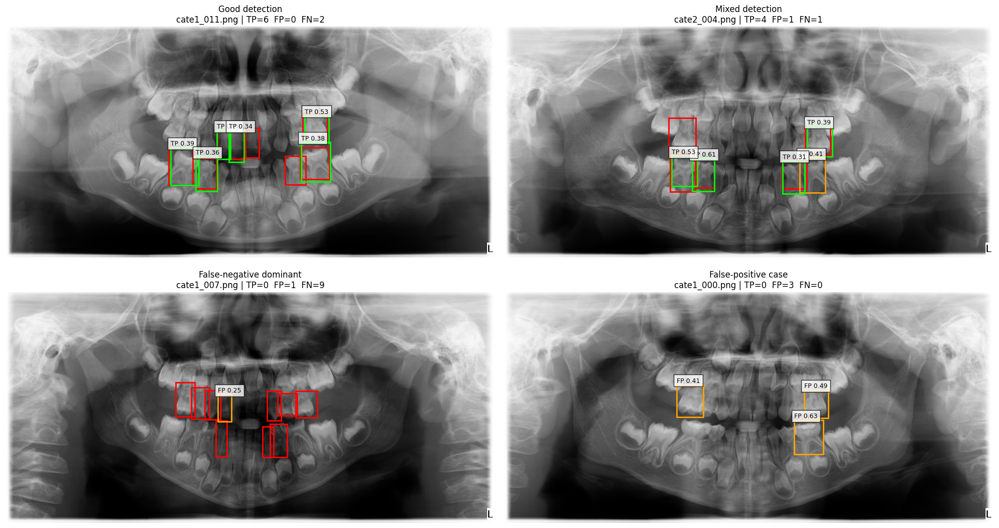

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path


selected_cases = [
    ("cate1_011.png", "Good detection"),
    ("cate2_004.png", "Mixed detection"),
    ("cate1_007.png", "False-negative dominant"),
    ("cate1_000.png", "False-positive case")
]


CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50


fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 11)
)


for ax, (image_name, case_title) in zip(
    axes.flatten(),
    selected_cases
):

    image_path = (
        test_images_dir /
        image_name
    )

    label_path = (
        test_labels_dir /
        f"{Path(image_name).stem}.txt"
    )

    img = Image.open(image_path)

    W, H = img.size

    ax.imshow(
        img,
        cmap="gray"
    )


    # ======================================================
    # GROUND TRUTH
    # ======================================================

    gt_boxes = load_yolo_ground_truth(
        label_path,
        W,
        H
    )


    # ======================================================
    # MODEL PREDICTIONS
    # ======================================================

    prediction = final_detector.predict(
        source=str(image_path),
        imgsz=1024,
        conf=CONF_THRESHOLD,
        iou=0.50,
        device=0,
        verbose=False
    )[0]


    pred_boxes = []

    if prediction.boxes is not None:

        for box in prediction.boxes:

            coords = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            score = float(
                box.conf[0]
                .detach()
                .cpu()
            )

            pred_boxes.append(
                {
                    "box": coords,
                    "score": score
                }
            )


    # ======================================================
    # MATCH PREDICTIONS TO GT
    # ======================================================

    matched_gt = set()

    matched_predictions = []

    for pred in pred_boxes:

        best_iou = 0
        best_gt_index = None

        for gt_index, gt_box in enumerate(
            gt_boxes
        ):

            if gt_index in matched_gt:
                continue

            iou = calculate_iou(
                pred["box"],
                gt_box
            )

            if iou > best_iou:

                best_iou = iou
                best_gt_index = gt_index


        if (
            best_iou >= IOU_THRESHOLD
            and best_gt_index is not None
        ):

            matched_gt.add(
                best_gt_index
            )

            matched_predictions.append(
                (
                    pred,
                    True
                )
            )

        else:

            matched_predictions.append(
                (
                    pred,
                    False
                )
            )


    # ======================================================
    # DRAW GROUND TRUTH = RED
    # ======================================================

    for gt_box in gt_boxes:

        x1, y1, x2, y2 = gt_box

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)


    # ======================================================
    # DRAW PREDICTIONS
    # ======================================================

    for pred, is_tp in matched_predictions:

        x1, y1, x2, y2 = pred["box"]

        if is_tp:

            edge_color = "lime"
            text_label = f"TP {pred['score']:.2f}"

        else:

            edge_color = "orange"
            text_label = f"FP {pred['score']:.2f}"


        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor=edge_color,
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(y1 - 8, 0),
            text_label,
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.8
            )
        )


    # ======================================================
    # IMAGE STATISTICS
    # ======================================================

    row = error_df[
        error_df["image"] == image_name
    ].iloc[0]


    ax.set_title(
        f"{case_title}\n"
        f"{image_name} | "
        f"TP={row['TP']}  "
        f"FP={row['FP']}  "
        f"FN={row['FN']}",
        fontsize=12
    )

    ax.axis("off")


plt.tight_layout()

In [ ]:
FIGURE_DIR = (
    PROJECT_DIR
    / "final_model"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


png_path = (
    FIGURE_DIR /
    "YOLO11s_Error_Analysis_Figure.png"
)

pdf_path = (
    FIGURE_DIR /
    "YOLO11s_Error_Analysis_Figure.pdf"
)


fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()


print("✅ PNG:")
print(png_path)

print("\n✅ PDF:")
print(pdf_path)

✅ PNG:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/YOLO11s_Error_Analysis_Figure.png

✅ PDF:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/YOLO11s_Error_Analysis_Figure.pdf


In [ ]:
error_summary = pd.DataFrame([
    {
        "Confidence_threshold": 0.25,
        "IoU_threshold": 0.50,
        "Ground_truth_lesions": 108,
        "Predicted_boxes": int(total_tp + total_fp),
        "True_positives": int(total_tp),
        "False_positives": int(total_fp),
        "False_negatives": int(total_fn),
        "Precision": precision_025,
        "Recall": recall_025,
        "F1": f1_025
    }
])

ERROR_SUMMARY_PATH = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Error_Analysis_Summary.csv"
)

error_summary.to_csv(
    ERROR_SUMMARY_PATH,
    index=False
)

print(error_summary)

print("\n✅ Saved:")
print(ERROR_SUMMARY_PATH)

   Confidence_threshold  IoU_threshold  Ground_truth_lesions  Predicted_boxes  \
0                  0.25            0.5                   108               68   

   True_positives  False_positives  False_negatives  Precision    Recall  \
0              36               32               72   0.529412  0.333333   

         F1  
0  0.409091  

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Error_Analysis_Summary.csv


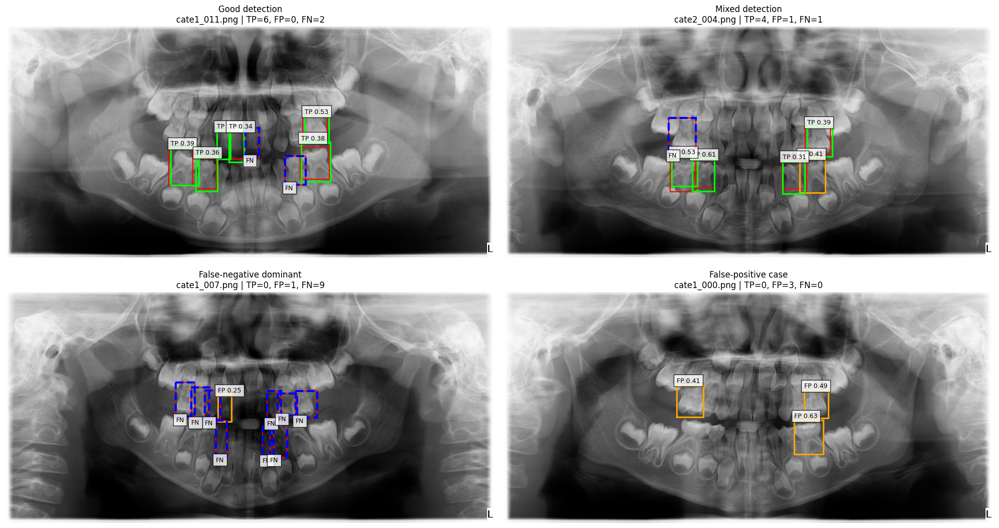

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# ==========================================================
# الحالات المختارة من الـ Final Test
# ==========================================================

selected_cases = [
    ("cate1_011.png", "Good detection"),
    ("cate2_004.png", "Mixed detection"),
    ("cate1_007.png", "False-negative dominant"),
    ("cate1_000.png", "False-positive case")
]

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50


fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 11)
)


for ax, (image_name, case_title) in zip(
    axes.flatten(),
    selected_cases
):

    # ------------------------------------------------------
    # Load image
    # ------------------------------------------------------

    image_path = (
        test_images_dir /
        image_name
    )

    label_path = (
        test_labels_dir /
        f"{Path(image_name).stem}.txt"
    )

    img = Image.open(image_path)

    W, H = img.size

    ax.imshow(
        img,
        cmap="gray"
    )

    # ------------------------------------------------------
    # Ground Truth
    # ------------------------------------------------------

    gt_boxes = load_yolo_ground_truth(
        label_path,
        W,
        H
    )

    # ------------------------------------------------------
    # Predictions
    # ------------------------------------------------------

    prediction = final_detector.predict(
        source=str(image_path),
        imgsz=1024,
        conf=CONF_THRESHOLD,
        iou=0.50,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    if prediction.boxes is not None:

        for box in prediction.boxes:

            coords = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            score = float(
                box.conf[0]
                .detach()
                .cpu()
            )

            pred_boxes.append({
                "box": coords,
                "score": score
            })

    # ------------------------------------------------------
    # Match predictions to GT
    # ------------------------------------------------------

    matched_gt = set()
    evaluated_predictions = []

    for pred in pred_boxes:

        best_iou = 0
        best_gt_index = None

        for gt_index, gt_box in enumerate(
            gt_boxes
        ):

            if gt_index in matched_gt:
                continue

            iou = calculate_iou(
                pred["box"],
                gt_box
            )

            if iou > best_iou:

                best_iou = iou
                best_gt_index = gt_index

        # True Positive
        if (
            best_iou >= IOU_THRESHOLD
            and best_gt_index is not None
        ):

            matched_gt.add(
                best_gt_index
            )

            evaluated_predictions.append({
                "box": pred["box"],
                "score": pred["score"],
                "type": "TP"
            })

        # False Positive
        else:

            evaluated_predictions.append({
                "box": pred["box"],
                "score": pred["score"],
                "type": "FP"
            })

    # ------------------------------------------------------
    # 1. All Ground Truth = RED
    # ------------------------------------------------------

    for gt_box in gt_boxes:

        x1, y1, x2, y2 = gt_box

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1.5,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    # ------------------------------------------------------
    # 2. TP predictions = GREEN
    #    FP predictions = ORANGE
    # ------------------------------------------------------

    for pred in evaluated_predictions:

        x1, y1, x2, y2 = pred["box"]

        if pred["type"] == "TP":

            edge_color = "lime"
            label_text = f"TP {pred['score']:.2f}"

        else:

            edge_color = "orange"
            label_text = f"FP {pred['score']:.2f}"

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2.3,
            edgecolor=edge_color,
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 8),
            label_text,
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.8
            )
        )

    # ------------------------------------------------------
    # 3. Missed Ground Truth = BLUE = FN
    # ------------------------------------------------------

    for gt_index, gt_box in enumerate(
        gt_boxes
    ):

        if gt_index not in matched_gt:

            x1, y1, x2, y2 = gt_box

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=3,
                edgecolor="blue",
                facecolor="none",
                linestyle="--"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                min(H - 10, y2 + 20),
                "FN",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.8
                )
            )

    # ------------------------------------------------------
    # Statistics for image
    # ------------------------------------------------------

    row = error_df[
        error_df["image"] == image_name
    ].iloc[0]

    ax.set_title(
        f"{case_title}\n"
        f"{image_name} | "
        f"TP={int(row['TP'])}, "
        f"FP={int(row['FP'])}, "
        f"FN={int(row['FN'])}",
        fontsize=12
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
from matplotlib.lines import Line2D

legend_elements = [

    Line2D(
        [0], [0],
        color="red",
        lw=2,
        label="Ground Truth"
    ),

    Line2D(
        [0], [0],
        color="lime",
        lw=2.5,
        label="True Positive (TP)"
    ),

    Line2D(
        [0], [0],
        color="orange",
        lw=2.5,
        label="False Positive (FP)"
    ),

    Line2D(
        [0], [0],
        color="blue",
        lw=3,
        linestyle="--",
        label="False Negative (FN)"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    fontsize=11,
    bbox_to_anchor=(0.5, -0.01)
)

plt.show()

In [ ]:
FIGURE_DIR = (
    PROJECT_DIR
    / "final_model"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figure_png = (
    FIGURE_DIR /
    "Figure_Error_Analysis_YOLO11s.png"
)

figure_pdf = (
    FIGURE_DIR /
    "Figure_Error_Analysis_YOLO11s.pdf"
)

fig.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight"
)

print("✅ PNG saved:")
print(figure_png)

print("\n✅ PDF saved:")
print(figure_pdf)

✅ PNG saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure_Error_Analysis_YOLO11s.png

✅ PDF saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure_Error_Analysis_YOLO11s.pdf


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

TABLES_DIR = (
    PROJECT_DIR
    / "final_model"
    / "tables"
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

dataset_table = pd.DataFrame([
    {
        "Dataset": "Development set",
        "Images": 70,
        "Caries-positive images": 49,
        "Caries-negative images": 21,
        "Caries lesions": 206,
        "Purpose": "5-fold cross-validation and final training"
    },
    {
        "Dataset": "Test set",
        "Images": 30,
        "Caries-positive images": 24,
        "Caries-negative images": 6,
        "Caries lesions": 108,
        "Purpose": "Final evaluation"
    },
    {
        "Dataset": "Total",
        "Images": 100,
        "Caries-positive images": 73,
        "Caries-negative images": 27,
        "Caries lesions": 314,
        "Purpose": "Complete annotated detection dataset"
    }
])

print(dataset_table.to_string(index=False))

dataset_table.to_csv(
    TABLES_DIR / "Table1_Dataset_Characteristics.csv",
    index=False
)

        Dataset  Images  Caries-positive images  Caries-negative images  Caries lesions                                    Purpose
Development set      70                      49                      21             206 5-fold cross-validation and final training
       Test set      30                      24                       6             108                           Final evaluation
          Total     100                      73                      27             314       Complete annotated detection dataset


In [ ]:
CV_DIR = (
    PROJECT_DIR
    / "cross_validation"
)

yolo = pd.read_csv(
    CV_DIR / "YOLO11s_results.csv"
)

rt = pd.read_csv(
    CV_DIR / "RTDETR_results.csv"
)

frcnn = pd.read_csv(
    CV_DIR / "FasterRCNN_results.csv"
)

retina = pd.read_csv(
    CV_DIR / "RetinaNet_results.csv"
)

In [ ]:
model_tables = {
    "YOLO11s": yolo,
    "RT-DETR": rt,
    "Faster R-CNN": frcnn,
    "RetinaNet": retina
}

comparison_rows = []

for model_name, df in model_tables.items():

    comparison_rows.append({

        "Model": model_name,

        "Precision Mean": df["precision"].mean(),
        "Precision SD": df["precision"].std(ddof=1),

        "Recall Mean": df["recall"].mean(),
        "Recall SD": df["recall"].std(ddof=1),

        "mAP50 Mean": df["mAP50"].mean(),
        "mAP50 SD": df["mAP50"].std(ddof=1),

        "mAP50-95 Mean": df["mAP50_95"].mean(),
        "mAP50-95 SD": df["mAP50_95"].std(ddof=1)
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print(
    comparison_df.round(4).to_string(
        index=False
    )
)

comparison_df.to_csv(
    TABLES_DIR / "Table2_Model_CrossValidation_Comparison.csv",
    index=False
)

       Model  Precision Mean  Precision SD  Recall Mean  Recall SD  mAP50 Mean  mAP50 SD  mAP50-95 Mean  mAP50-95 SD
     YOLO11s          0.3714        0.0898       0.4499     0.1390      0.3540    0.1399         0.1877       0.0683
     RT-DETR          0.2444        0.0870       0.5031     0.0662      0.2809    0.0960         0.1509       0.0506
Faster R-CNN          0.1599        0.0431       0.9095     0.0861      0.2599    0.0170         0.1371       0.0046
   RetinaNet          0.2308        0.0977       0.3198     0.1771      0.1352    0.0462         0.0677       0.0285


In [ ]:
friedman_table = pd.DataFrame([
    {
        "Metric": "mAP@0.50",
        "Friedman statistic": 10.68,
        "p-value": 0.0136,
        "Interpretation": "Significant overall difference"
    },
    {
        "Metric": "mAP@0.50:0.95",
        "Friedman statistic": 10.20,
        "p-value": 0.0169,
        "Interpretation": "Significant overall difference"
    }
])

print(friedman_table.to_string(index=False))

friedman_table.to_csv(
    TABLES_DIR / "Table3_Friedman_Test.csv",
    index=False
)

       Metric  Friedman statistic  p-value                 Interpretation
     mAP@0.50               10.68   0.0136 Significant overall difference
mAP@0.50:0.95               10.20   0.0169 Significant overall difference


In [ ]:
pairwise_df.to_csv(
    TABLES_DIR / "Table3B_Wilcoxon_Holm_Pairwise.csv",
    index=False
)

print(pairwise_df.to_string(index=False))

  Metric      Model A      Model B  Statistic  p_raw  p_holm  Significant
   mAP50      YOLO11s      RT-DETR        1.0 0.1250   0.375        False
   mAP50      YOLO11s Faster R-CNN        2.0 0.1875   0.375        False
   mAP50      YOLO11s    RetinaNet        0.0 0.0625   0.375        False
   mAP50      RT-DETR Faster R-CNN        5.0 0.6250   0.625        False
   mAP50      RT-DETR    RetinaNet        0.0 0.0625   0.375        False
   mAP50 Faster R-CNN    RetinaNet        0.0 0.0625   0.375        False
mAP50_95      YOLO11s      RT-DETR        0.0 0.0625   0.375        False
mAP50_95      YOLO11s Faster R-CNN        2.0 0.1875   0.375        False
mAP50_95      YOLO11s    RetinaNet        0.0 0.0625   0.375        False
mAP50_95      RT-DETR Faster R-CNN        6.0 0.8125  0.8125        False
mAP50_95      RT-DETR    RetinaNet        1.0 0.1250   0.375        False
mAP50_95 Faster R-CNN    RetinaNet        0.0 0.0625   0.375        False


In [ ]:
rank_map50 = calculate_mean_ranks(
    "mAP50"
)

rank_map95 = calculate_mean_ranks(
    "mAP50_95"
)

rank_map50["Metric"] = "mAP50"
rank_map95["Metric"] = "mAP50-95"

mean_ranks_table = pd.concat(
    [rank_map50, rank_map95],
    ignore_index=True
)

print(mean_ranks_table)

mean_ranks_table.to_csv(
    TABLES_DIR / "Table3C_Model_Mean_Ranks.csv",
    index=False
)

          Model  Mean Rank    Metric
0       YOLO11s        1.4     mAP50
1       RT-DETR        2.2     mAP50
2  Faster R-CNN        2.4     mAP50
3     RetinaNet        4.0     mAP50
4       YOLO11s        1.2  mAP50-95
5  Faster R-CNN        2.4  mAP50-95
6       RT-DETR        2.6  mAP50-95
7     RetinaNet        3.8  mAP50-95


In [ ]:
FINAL_TEST_RESULTS = (
    PROJECT_DIR
    / "final_model"
    / "YOLO11s_Final_Test_Results.csv"
)

final_test_df = pd.read_csv(
    FINAL_TEST_RESULTS
)

print(final_test_df.to_string(index=False))

  Model  Development_images  Test_images  Test_positive_images  Test_negative_images  Test_caries_boxes  Final_epochs  Precision   Recall       F1    mAP50  mAP50_95
YOLO11s                  70           30                    24                     6                108            60   0.427713 0.601852 0.500056 0.459214  0.247294


In [ ]:
final_performance_table = pd.DataFrame([
    {
        "Model": "YOLO11s",
        "Test images": 30,
        "Caries lesions": 108,
        "Precision": 0.4277,
        "Recall": 0.6019,
        "F1-score": 0.5001,
        "mAP@0.50": 0.4592,
        "mAP@0.50:0.95": 0.2473
    }
])

print(
    final_performance_table.to_string(
        index=False
    )
)

final_performance_table.to_csv(
    TABLES_DIR / "Table4_Final_YOLO11s_Test_Performance.csv",
    index=False
)

  Model  Test images  Caries lesions  Precision  Recall  F1-score  mAP@0.50  mAP@0.50:0.95
YOLO11s           30             108     0.4277  0.6019    0.5001    0.4592         0.2473


In [ ]:
error_table = pd.DataFrame([
    {
        "Confidence threshold": 0.25,
        "IoU threshold": 0.50,
        "Ground-truth lesions": 108,
        "Predictions": 68,
        "True positives": 36,
        "False positives": 32,
        "False negatives": 72,
        "Precision": 0.5294,
        "Recall": 0.3333,
        "F1-score": 0.4091
    }
])

print(error_table.to_string(index=False))

error_table.to_csv(
    TABLES_DIR / "Table5_Error_Analysis.csv",
    index=False
)

 Confidence threshold  IoU threshold  Ground-truth lesions  Predictions  True positives  False positives  False negatives  Precision  Recall  F1-score
                 0.25            0.5                   108           68              36               32               72     0.5294  0.3333    0.4091


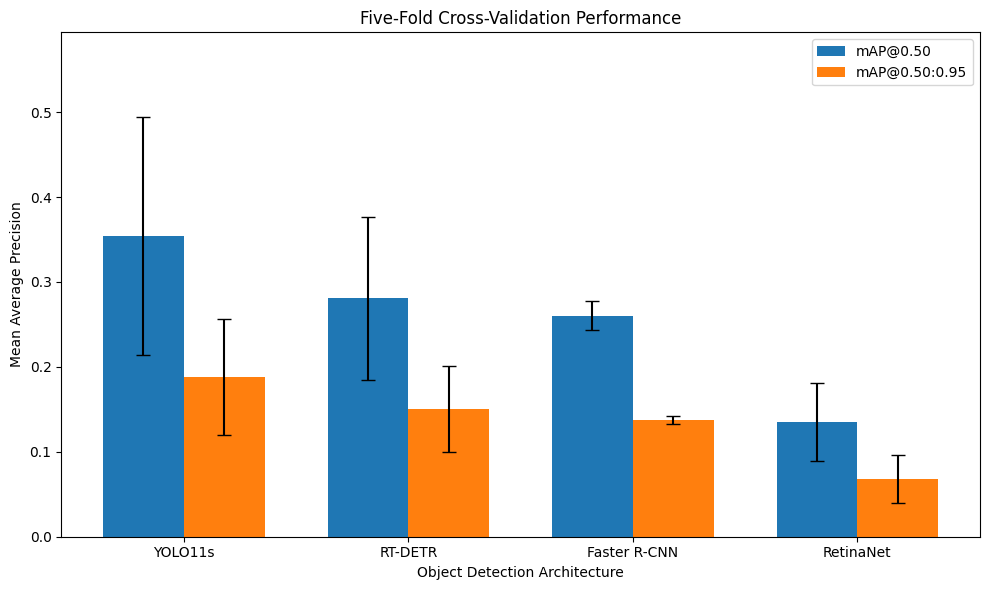

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

FIGURE_DIR = (
    PROJECT_DIR /
    "final_model" /
    "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CV_DIR = (
    PROJECT_DIR /
    "cross_validation"
)

yolo = pd.read_csv(CV_DIR / "YOLO11s_results.csv")
rt = pd.read_csv(CV_DIR / "RTDETR_results.csv")
frcnn = pd.read_csv(CV_DIR / "FasterRCNN_results.csv")
retina = pd.read_csv(CV_DIR / "RetinaNet_results.csv")

model_tables = {
    "YOLO11s": yolo,
    "RT-DETR": rt,
    "Faster R-CNN": frcnn,
    "RetinaNet": retina
}

models = list(model_tables.keys())

map50_mean = [
    model_tables[m]["mAP50"].mean()
    for m in models
]

map50_sd = [
    model_tables[m]["mAP50"].std(ddof=1)
    for m in models
]

map95_mean = [
    model_tables[m]["mAP50_95"].mean()
    for m in models
]

map95_sd = [
    model_tables[m]["mAP50_95"].std(ddof=1)
    for m in models
]

x = np.arange(len(models))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    map50_mean,
    width,
    yerr=map50_sd,
    capsize=5,
    label="mAP@0.50"
)

ax.bar(
    x + width/2,
    map95_mean,
    width,
    yerr=map95_sd,
    capsize=5,
    label="mAP@0.50:0.95"
)

ax.set_ylabel("Mean Average Precision")
ax.set_xlabel("Object Detection Architecture")

ax.set_title(
    "Five-Fold Cross-Validation Performance"
)

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.legend()

ax.set_ylim(
    0,
    max(
        np.array(map50_mean) +
        np.array(map50_sd)
    ) + 0.10
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure1_Model_mAP_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    FIGURE_DIR /
    "Figure1_Model_mAP_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

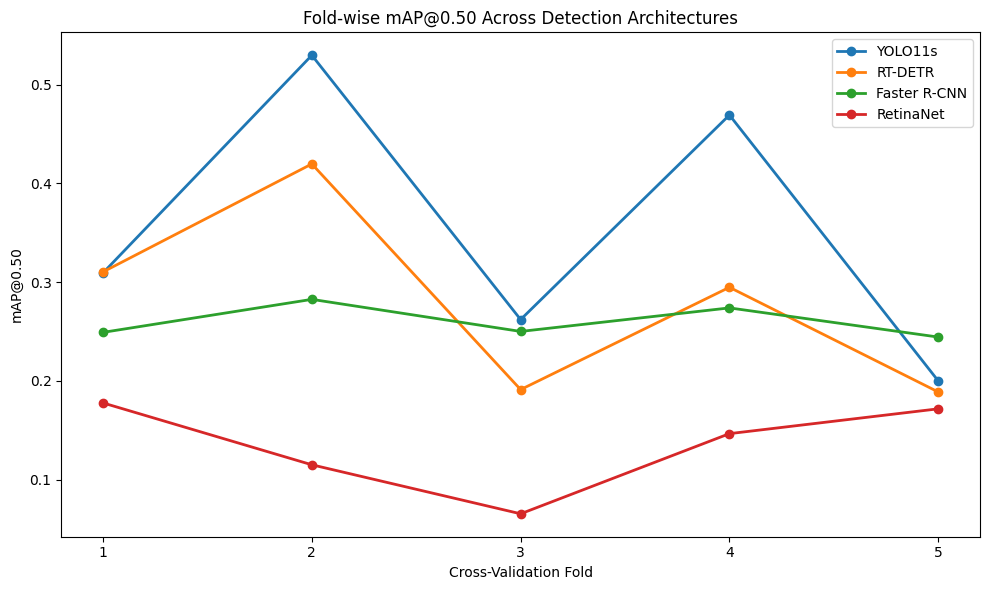

In [ ]:
plt.figure(figsize=(10, 6))

for model_name, df in model_tables.items():

    df = df.sort_values("fold")

    plt.plot(
        df["fold"],
        df["mAP50"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Cross-Validation Fold")
plt.ylabel("mAP@0.50")

plt.title(
    "Fold-wise mAP@0.50 Across Detection Architectures"
)

plt.xticks(
    [1, 2, 3, 4, 5]
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure2_Foldwise_mAP50.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    FIGURE_DIR /
    "Figure2_Foldwise_mAP50.pdf",
    bbox_inches="tight"
)

plt.show()

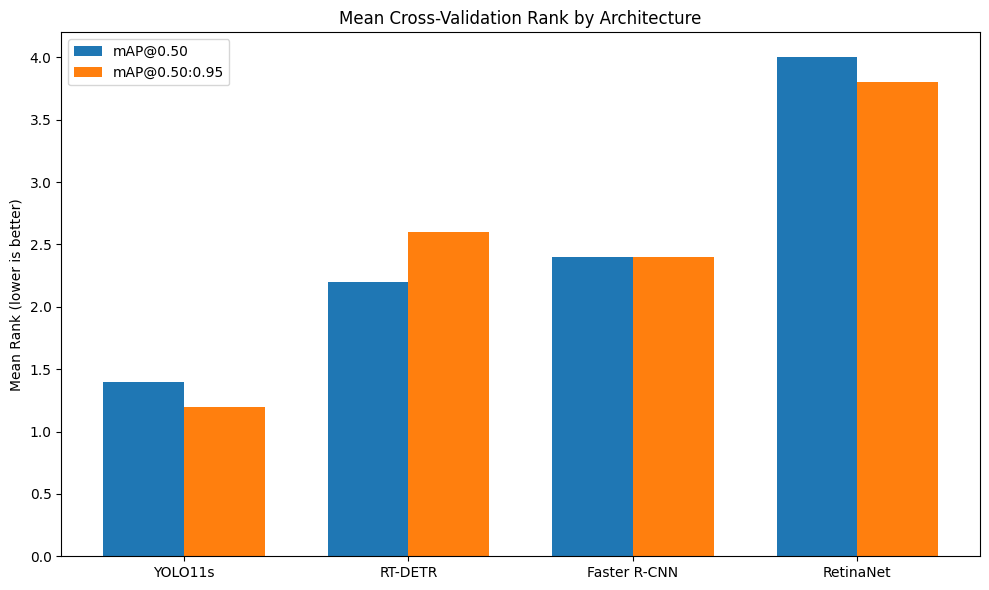

In [ ]:
rank_data = pd.DataFrame({
    "Model": [
        "YOLO11s",
        "RT-DETR",
        "Faster R-CNN",
        "RetinaNet"
    ],
    "mAP50 Mean Rank": [
        1.4,
        2.2,
        2.4,
        4.0
    ],
    "mAP50-95 Mean Rank": [
        1.2,
        2.6,
        2.4,
        3.8
    ]
})

x = np.arange(
    len(rank_data)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x - width/2,
    rank_data["mAP50 Mean Rank"],
    width,
    label="mAP@0.50"
)

ax.bar(
    x + width/2,
    rank_data["mAP50-95 Mean Rank"],
    width,
    label="mAP@0.50:0.95"
)

ax.set_xticks(x)

ax.set_xticklabels(
    rank_data["Model"]
)

ax.set_ylabel(
    "Mean Rank (lower is better)"
)

ax.set_title(
    "Mean Cross-Validation Rank by Architecture"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure3_Model_Mean_Ranks.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


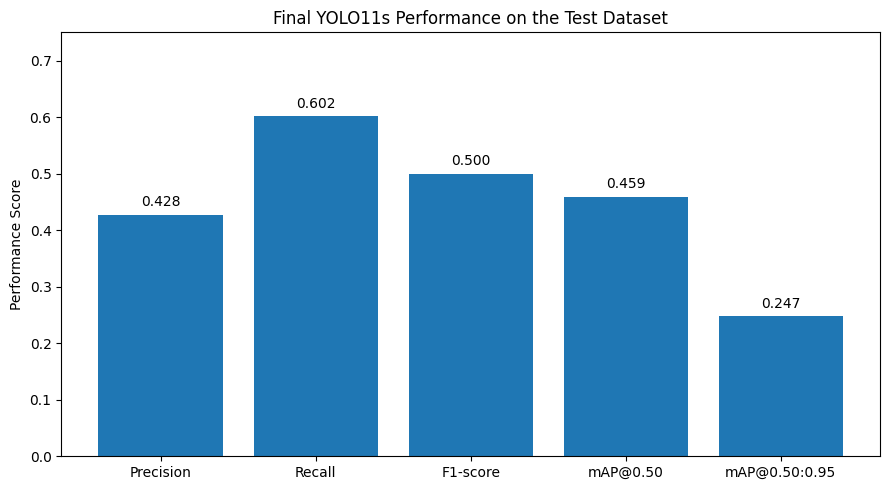

In [ ]:
metrics = [
    "Precision",
    "Recall",
    "F1-score",
    "mAP@0.50",
    "mAP@0.50:0.95"
]

values = [
    0.4277,
    0.6019,
    0.5001,
    0.4592,
    0.2473
]

plt.figure(
    figsize=(9, 5)
)

bars = plt.bar(
    metrics,
    values
)

plt.ylabel(
    "Performance Score"
)

plt.ylim(
    0,
    0.75
)

plt.title(
    "Final YOLO11s Performance on the Test Dataset"
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x() +
        bar.get_width()/2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure4_Final_YOLO11s_Performance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

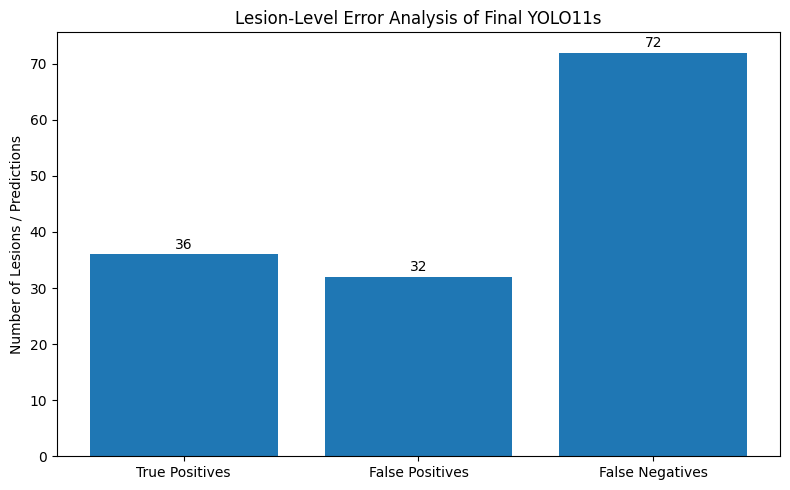

In [ ]:
categories = [
    "True Positives",
    "False Positives",
    "False Negatives"
]

counts = [
    36,
    32,
    72
]

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    categories,
    counts
)

plt.ylabel(
    "Number of Lesions / Predictions"
)

plt.title(
    "Lesion-Level Error Analysis of Final YOLO11s"
)

for bar, value in zip(
    bars,
    counts
):

    plt.text(
        bar.get_x() +
        bar.get_width()/2,
        bar.get_height() + 1,
        str(value),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Figure5_Error_Analysis_Counts.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

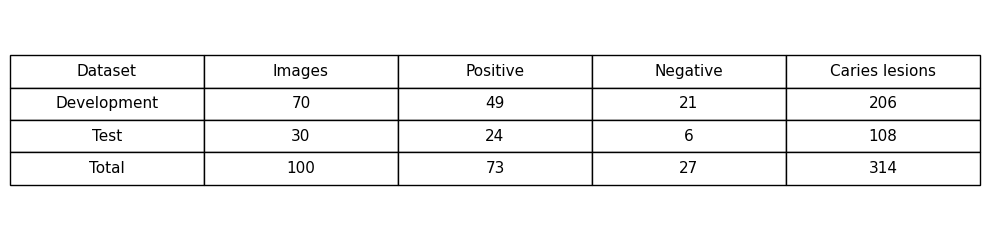

In [ ]:
import matplotlib.pyplot as plt

dataset_table = pd.DataFrame([
    [
        "Development",
        70,
        49,
        21,
        206
    ],
    [
        "Test",
        30,
        24,
        6,
        108
    ],
    [
        "Total",
        100,
        73,
        27,
        314
    ]
],
columns=[
    "Dataset",
    "Images",
    "Positive",
    "Negative",
    "Caries lesions"
])

fig, ax = plt.subplots(
    figsize=(10, 2.5)
)

ax.axis("off")

table = ax.table(
    cellText=dataset_table.values,
    colLabels=dataset_table.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.7)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Table1_Dataset_Characteristics.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

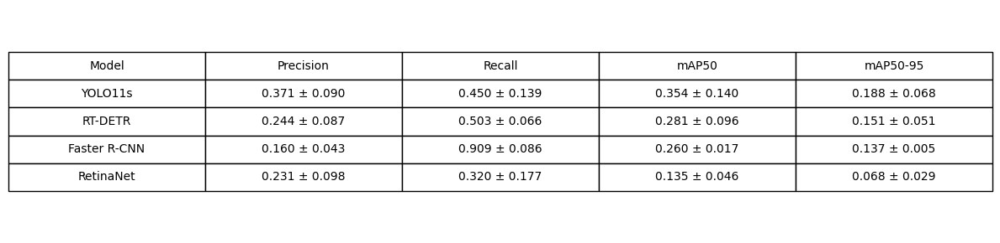

In [ ]:
comparison_publication = pd.DataFrame({
    "Model": [
        "YOLO11s",
        "RT-DETR",
        "Faster R-CNN",
        "RetinaNet"
    ],

    "Precision": [
        "0.371 ± 0.090",
        "0.244 ± 0.087",
        "0.160 ± 0.043",
        "0.231 ± 0.098"
    ],

    "Recall": [
        "0.450 ± 0.139",
        "0.503 ± 0.066",
        "0.909 ± 0.086",
        "0.320 ± 0.177"
    ],

    "mAP50": [
        "0.354 ± 0.140",
        "0.281 ± 0.096",
        "0.260 ± 0.017",
        "0.135 ± 0.046"
    ],

    "mAP50-95": [
        "0.188 ± 0.068",
        "0.151 ± 0.051",
        "0.137 ± 0.005",
        "0.068 ± 0.029"
    ]
})

fig, ax = plt.subplots(
    figsize=(12, 3)
)

ax.axis("off")

table = ax.table(
    cellText=(
        comparison_publication
        .values
    ),
    colLabels=(
        comparison_publication
        .columns
    ),
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Table2_Model_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

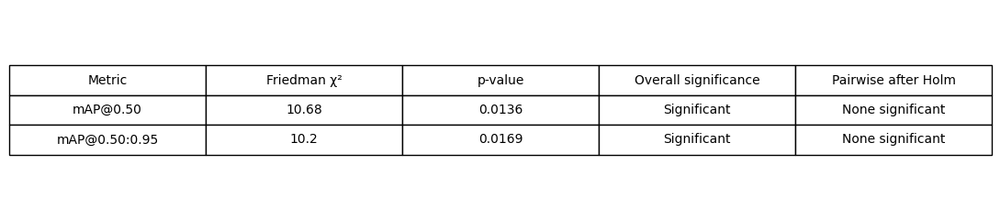

In [ ]:
stats_table = pd.DataFrame({
    "Metric": [
        "mAP@0.50",
        "mAP@0.50:0.95"
    ],

    "Friedman χ²": [
        10.68,
        10.20
    ],

    "p-value": [
        0.0136,
        0.0169
    ],

    "Overall significance": [
        "Significant",
        "Significant"
    ],

    "Pairwise after Holm": [
        "None significant",
        "None significant"
    ]
})

fig, ax = plt.subplots(
    figsize=(11, 2.5)
)

ax.axis("off")

table = ax.table(
    cellText=stats_table.values,
    colLabels=stats_table.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Table3_Statistical_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

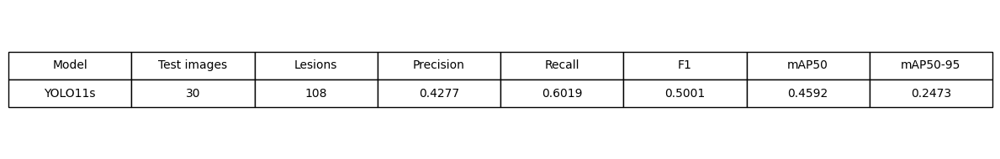

In [ ]:
final_table = pd.DataFrame({
    "Model": ["YOLO11s"],
    "Test images": [30],
    "Lesions": [108],
    "Precision": [0.4277],
    "Recall": [0.6019],
    "F1": [0.5001],
    "mAP50": [0.4592],
    "mAP50-95": [0.2473]
})

fig, ax = plt.subplots(
    figsize=(12, 2)
)

ax.axis("off")

table = ax.table(
    cellText=final_table.values,
    colLabels=final_table.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "Table4_Final_Test_Performance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

CV_DIR = (
    PROJECT_DIR /
    "cross_validation"
)

FIGURE_DIR = (
    PROJECT_DIR /
    "final_model" /
    "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# LOAD CROSS-VALIDATION RESULTS
# ============================================================

yolo = pd.read_csv(
    CV_DIR / "YOLO11s_results.csv"
)

rt = pd.read_csv(
    CV_DIR / "RTDETR_results.csv"
)

frcnn = pd.read_csv(
    CV_DIR / "FasterRCNN_results.csv"
)

retina = pd.read_csv(
    CV_DIR / "RetinaNet_results.csv"
)

model_tables = {
    "YOLO11s": yolo,
    "RT-DETR": rt,
    "Faster R-CNN": frcnn,
    "RetinaNet": retina
}

print("✅ Results loaded successfully")

for name, df in model_tables.items():
    print(name, ":", len(df), "folds")

✅ Results loaded successfully
YOLO11s : 5 folds
RT-DETR : 5 folds
Faster R-CNN : 5 folds
RetinaNet : 5 folds


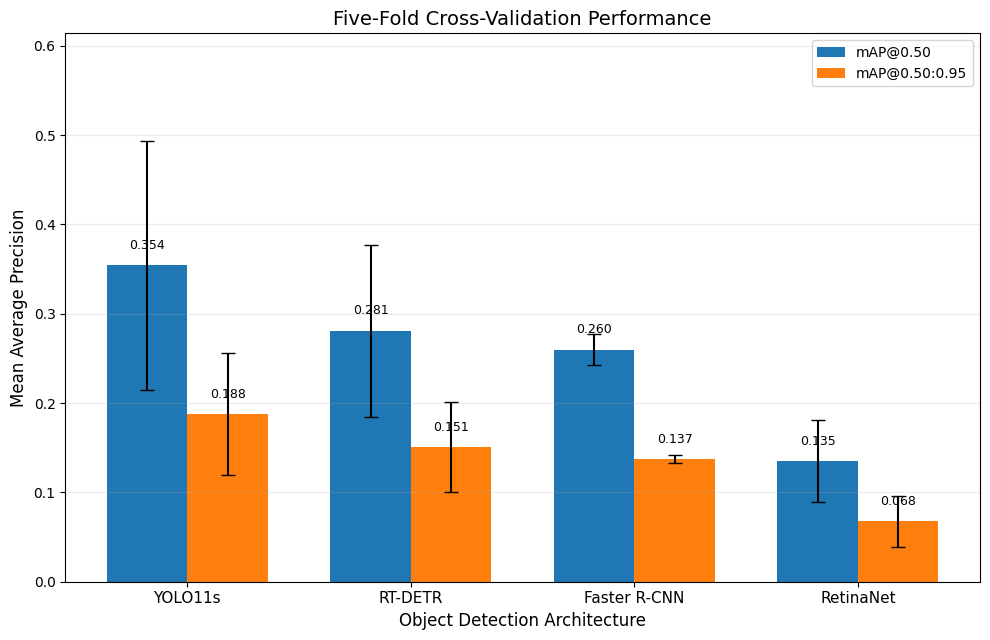

✅ Figure 1 PNG:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure1_CrossValidation_mAP_Comparison.png

✅ Figure 1 PDF:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure1_CrossValidation_mAP_Comparison.pdf


In [ ]:
# ============================================================
# FIGURE 1
# Comparative five-fold cross-validation performance
# ============================================================

models = list(
    model_tables.keys()
)

map50_means = []
map50_sds = []

map95_means = []
map95_sds = []

for model_name in models:

    df = model_tables[
        model_name
    ]

    map50_means.append(
        df["mAP50"].mean()
    )

    map50_sds.append(
        df["mAP50"].std(ddof=1)
    )

    map95_means.append(
        df["mAP50_95"].mean()
    )

    map95_sds.append(
        df["mAP50_95"].std(ddof=1)
    )


x = np.arange(
    len(models)
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(10, 6.5)
)


bars1 = ax.bar(
    x - width/2,
    map50_means,
    width,
    yerr=map50_sds,
    capsize=5,
    label="mAP@0.50"
)


bars2 = ax.bar(
    x + width/2,
    map95_means,
    width,
    yerr=map95_sds,
    capsize=5,
    label="mAP@0.50:0.95"
)


# ============================================================
# Numerical values above bars
# ============================================================

for bar, mean_value in zip(
    bars1,
    map50_means
):

    ax.text(
        bar.get_x() +
        bar.get_width()/2,

        bar.get_height() + 0.015,

        f"{mean_value:.3f}",

        ha="center",
        va="bottom",
        fontsize=9
    )


for bar, mean_value in zip(
    bars2,
    map95_means
):

    ax.text(
        bar.get_x() +
        bar.get_width()/2,

        bar.get_height() + 0.015,

        f"{mean_value:.3f}",

        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# Formatting
# ============================================================

ax.set_xlabel(
    "Object Detection Architecture",
    fontsize=12
)

ax.set_ylabel(
    "Mean Average Precision",
    fontsize=12
)

ax.set_title(
    "Five-Fold Cross-Validation Performance",
    fontsize=14
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    models,
    fontsize=11
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.legend(
    fontsize=10
)

ax.grid(
    axis="y",
    alpha=0.25
)


upper_limit = max(
    np.array(map50_means)
    +
    np.array(map50_sds)
) + 0.12

ax.set_ylim(
    0,
    upper_limit
)


plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

figure1_png = (
    FIGURE_DIR /
    "Figure1_CrossValidation_mAP_Comparison.png"
)

figure1_pdf = (
    FIGURE_DIR /
    "Figure1_CrossValidation_mAP_Comparison.pdf"
)

fig.savefig(
    figure1_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure1_pdf,
    bbox_inches="tight"
)

plt.show()


print("✅ Figure 1 PNG:")
print(figure1_png)

print("\n✅ Figure 1 PDF:")
print(figure1_pdf)

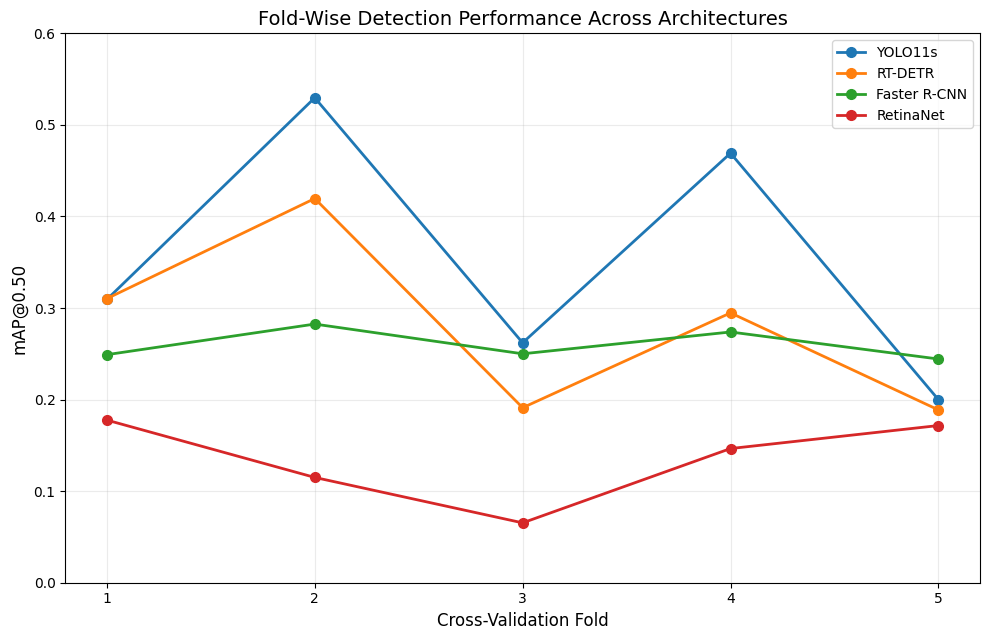

✅ Figure 2 PNG:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure2_Foldwise_mAP50.png

✅ Figure 2 PDF:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure2_Foldwise_mAP50.pdf


In [ ]:
# ============================================================
# FIGURE 2
# Fold-wise mAP@0.50
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6.5)
)


for model_name, df in model_tables.items():

    temp = (
        df
        .sort_values("fold")
        .copy()
    )

    ax.plot(
        temp["fold"],
        temp["mAP50"],
        marker="o",
        markersize=7,
        linewidth=2,
        label=model_name
    )


# ============================================================
# Formatting
# ============================================================

ax.set_xlabel(
    "Cross-Validation Fold",
    fontsize=12
)

ax.set_ylabel(
    "mAP@0.50",
    fontsize=12
)

ax.set_title(
    "Fold-Wise Detection Performance Across Architectures",
    fontsize=14
)

ax.set_xticks(
    [1, 2, 3, 4, 5]
)

ax.set_xlim(
    0.8,
    5.2
)

ax.set_ylim(
    0,
    0.60
)

ax.tick_params(
    labelsize=10
)

ax.grid(
    alpha=0.25
)

ax.legend(
    fontsize=10
)


plt.tight_layout()


# ============================================================
# SAVE
# ============================================================

figure2_png = (
    FIGURE_DIR /
    "Figure2_Foldwise_mAP50.png"
)

figure2_pdf = (
    FIGURE_DIR /
    "Figure2_Foldwise_mAP50.pdf"
)

fig.savefig(
    figure2_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure2_pdf,
    bbox_inches="tight"
)

plt.show()


print("✅ Figure 2 PNG:")
print(figure2_png)

print("\n✅ Figure 2 PDF:")
print(figure2_pdf)

In [ ]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from matplotlib.lines import Line2D
from PIL import Image
from pathlib import Path
from ultralytics import YOLO


PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

FIGURE_DIR = (
    PROJECT_DIR /
    "final_model" /
    "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# FINAL MODEL
# ============================================================

FINAL_MODEL_PATH = (
    PROJECT_DIR /
    "final_model" /
    "YOLO11s_Final" /
    "final_60epochs.pt"
)

print(
    "Final model exists:",
    FINAL_MODEL_PATH.exists()
)

final_detector = YOLO(
    str(FINAL_MODEL_PATH)
)


# ============================================================
# TEST DATASET
# ============================================================

TEST_DATASET_DIR = (
    PROJECT_DIR /
    "processed_data" /
    "yolo_caries_baseline"
)

test_images_dir = (
    TEST_DATASET_DIR /
    "images" /
    "test"
)

test_labels_dir = (
    TEST_DATASET_DIR /
    "labels" /
    "test"
)


print(
    "Test images directory exists:",
    test_images_dir.exists()
)

print(
    "Test labels directory exists:",
    test_labels_dir.exists()
)

Final model exists: True
Test images directory exists: True
Test labels directory exists: True


In [ ]:
def load_yolo_ground_truth(
    label_path,
    image_width,
    image_height
):

    boxes = []

    if not label_path.exists():
        return boxes

    text = (
        label_path
        .read_text()
        .strip()
    )

    if not text:
        return boxes


    for line in text.splitlines():

        values = line.split()

        cls = int(
            float(values[0])
        )

        xc = float(values[1])
        yc = float(values[2])
        bw = float(values[3])
        bh = float(values[4])


        # Convert normalized YOLO coordinates to pixels

        xc *= image_width
        yc *= image_height

        bw *= image_width
        bh *= image_height


        x1 = xc - bw / 2
        y1 = yc - bh / 2

        x2 = xc + bw / 2
        y2 = yc + bh / 2


        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    return boxes

In [ ]:
def calculate_iou(
    box1,
    box2
):

    x1 = max(
        box1[0],
        box2[0]
    )

    y1 = max(
        box1[1],
        box2[1]
    )

    x2 = min(
        box1[2],
        box2[2]
    )

    y2 = min(
        box1[3],
        box2[3]
    )


    intersection = (
        max(0, x2 - x1)
        *
        max(0, y2 - y1)
    )


    area1 = (
        max(0, box1[2] - box1[0])
        *
        max(0, box1[3] - box1[1])
    )


    area2 = (
        max(0, box2[2] - box2[0])
        *
        max(0, box2[3] - box2[1])
    )


    union = (
        area1 +
        area2 -
        intersection
    )


    if union <= 0:
        return 0.0


    return (
        intersection /
        union
    )

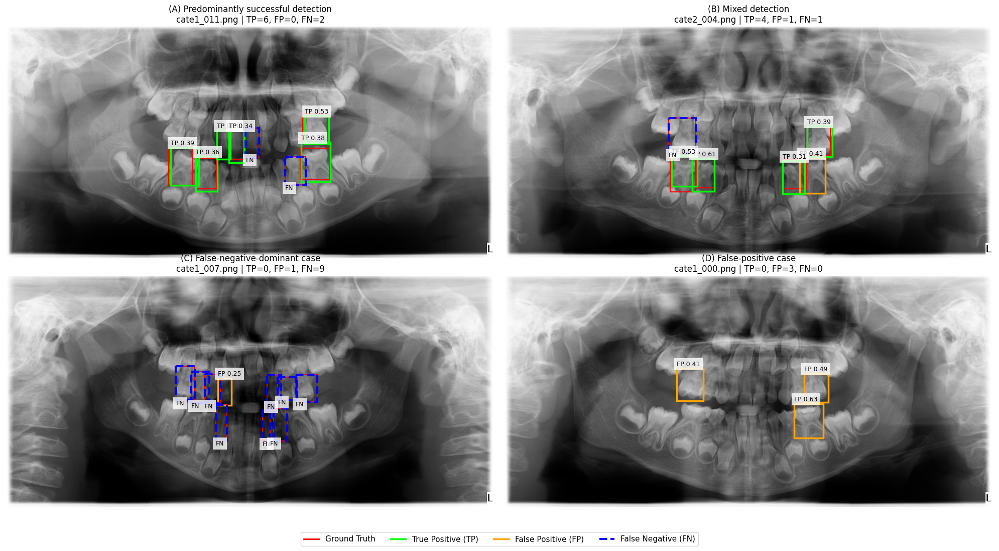

✅ Figure 3 PNG:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure3_Qualitative_YOLO11s_Detection.png

✅ Figure 3 PDF:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/figures/Figure3_Qualitative_YOLO11s_Detection.pdf


In [ ]:
# ============================================================
# SELECTED CASES
# ============================================================

selected_cases = [

    (
        "cate1_011.png",
        "A",
        "Predominantly successful detection"
    ),

    (
        "cate2_004.png",
        "B",
        "Mixed detection"
    ),

    (
        "cate1_007.png",
        "C",
        "False-negative-dominant case"
    ),

    (
        "cate1_000.png",
        "D",
        "False-positive case"
    )
]


CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50


fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 11)
)


# ============================================================
# LOOP THROUGH FOUR PANELS
# ============================================================

for ax, (
    image_name,
    panel_letter,
    case_title
) in zip(
    axes.flatten(),
    selected_cases
):


    # --------------------------------------------------------
    # IMAGE
    # --------------------------------------------------------

    image_path = (
        test_images_dir /
        image_name
    )

    label_path = (
        test_labels_dir /
        f"{Path(image_name).stem}.txt"
    )


    img = Image.open(
        image_path
    ).convert("RGB")


    W, H = img.size


    ax.imshow(
        img
    )


    # --------------------------------------------------------
    # GROUND TRUTH
    # --------------------------------------------------------

    gt_boxes = load_yolo_ground_truth(
        label_path,
        W,
        H
    )


    # --------------------------------------------------------
    # MODEL PREDICTION
    # --------------------------------------------------------

    result = final_detector.predict(

        source=str(
            image_path
        ),

        imgsz=1024,

        conf=CONF_THRESHOLD,

        iou=0.50,

        device=0,

        verbose=False

    )[0]


    pred_boxes = []


    if result.boxes is not None:

        for box in result.boxes:

            coords = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            confidence = float(
                box.conf[0]
                .detach()
                .cpu()
            )


            pred_boxes.append({
                "box": coords,
                "score": confidence
            })


    # --------------------------------------------------------
    # MATCH PREDICTIONS WITH GT
    # --------------------------------------------------------

    matched_gt = set()

    evaluated_predictions = []


    for pred in pred_boxes:

        best_iou = 0
        best_gt_index = None


        for gt_index, gt_box in enumerate(
            gt_boxes
        ):

            if gt_index in matched_gt:
                continue


            current_iou = calculate_iou(
                pred["box"],
                gt_box
            )


            if current_iou > best_iou:

                best_iou = current_iou

                best_gt_index = gt_index


        # TRUE POSITIVE
        if (
            best_iou >= IOU_THRESHOLD
            and
            best_gt_index is not None
        ):

            matched_gt.add(
                best_gt_index
            )

            evaluated_predictions.append({
                "box": pred["box"],
                "score": pred["score"],
                "type": "TP"
            })


        # FALSE POSITIVE
        else:

            evaluated_predictions.append({
                "box": pred["box"],
                "score": pred["score"],
                "type": "FP"
            })


    # ========================================================
    # DRAW ALL GROUND TRUTH BOXES — RED
    # ========================================================

    for gt_box in gt_boxes:

        x1, y1, x2, y2 = gt_box


        rect = patches.Rectangle(

            (x1, y1),

            x2 - x1,
            y2 - y1,

            linewidth=1.5,

            edgecolor="red",

            facecolor="none"

        )


        ax.add_patch(
            rect
        )


    # ========================================================
    # DRAW TP / FP
    # ========================================================

    TP = 0
    FP = 0


    for pred in evaluated_predictions:

        x1, y1, x2, y2 = (
            pred["box"]
        )


        if pred["type"] == "TP":

            TP += 1

            edge_color = "lime"

            text_label = (
                f"TP {pred['score']:.2f}"
            )


        else:

            FP += 1

            edge_color = "orange"

            text_label = (
                f"FP {pred['score']:.2f}"
            )


        rect = patches.Rectangle(

            (x1, y1),

            x2 - x1,
            y2 - y1,

            linewidth=2.5,

            edgecolor=edge_color,

            facecolor="none"

        )


        ax.add_patch(
            rect
        )


        ax.text(

            x1,

            max(
                0,
                y1 - 10
            ),

            text_label,

            fontsize=9,

            bbox=dict(
                facecolor="white",
                alpha=0.80,
                edgecolor="none"
            )
        )


    # ========================================================
    # FALSE NEGATIVES — BLUE DASHED BOXES
    # ========================================================

    FN = 0


    for gt_index, gt_box in enumerate(
        gt_boxes
    ):


        if gt_index not in matched_gt:

            FN += 1


            x1, y1, x2, y2 = gt_box


            fn_rect = patches.Rectangle(

                (x1, y1),

                x2 - x1,
                y2 - y1,

                linewidth=3,

                edgecolor="blue",

                facecolor="none",

                linestyle="--"

            )


            ax.add_patch(
                fn_rect
            )


            ax.text(

                x1,

                min(
                    H - 5,
                    y2 + 18
                ),

                "FN",

                fontsize=9,

                bbox=dict(
                    facecolor="white",
                    alpha=0.80,
                    edgecolor="none"
                )
            )


    # ========================================================
    # PANEL TITLE
    # ========================================================

    ax.set_title(

        f"({panel_letter}) {case_title}\n"
        f"{image_name} | "
        f"TP={TP}, FP={FP}, FN={FN}",

        fontsize=12

    )


    ax.axis(
        "off"
    )


# ============================================================
# COMMON LEGEND
# ============================================================

legend_elements = [

    Line2D(
        [0],
        [0],
        color="red",
        lw=2,
        label="Ground Truth"
    ),

    Line2D(
        [0],
        [0],
        color="lime",
        lw=2.5,
        label="True Positive (TP)"
    ),

    Line2D(
        [0],
        [0],
        color="orange",
        lw=2.5,
        label="False Positive (FP)"
    ),

    Line2D(
        [0],
        [0],
        color="blue",
        lw=3,
        linestyle="--",
        label="False Negative (FN)"
    )
]


fig.legend(

    handles=legend_elements,

    loc="lower center",

    ncol=4,

    fontsize=11,

    bbox_to_anchor=(
        0.5,
        0.01
    )

)


plt.tight_layout(
    rect=[
        0,
        0.06,
        1,
        1
    ]
)


# ============================================================
# SAVE
# ============================================================

figure3_png = (
    FIGURE_DIR /
    "Figure3_Qualitative_YOLO11s_Detection.png"
)

figure3_pdf = (
    FIGURE_DIR /
    "Figure3_Qualitative_YOLO11s_Detection.pdf"
)


fig.savefig(

    figure3_png,

    dpi=600,

    bbox_inches="tight"

)


fig.savefig(

    figure3_pdf,

    bbox_inches="tight"

)


plt.show()


print("✅ Figure 3 PNG:")
print(figure3_png)

print("\n✅ Figure 3 PDF:")
print(figure3_pdf)

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

ERROR_PATH = (
    PROJECT_DIR /
    "final_model" /
    "YOLO11s_Final_Error_Analysis.csv"
)

df = pd.read_csv(ERROR_PATH)

print(df.columns.tolist())
print(df.head())

['image', 'GT', 'Predictions', 'TP', 'FP', 'FN']
           image  GT  Predictions  TP  FP  FN
0  cate1_000.png   0            3   0   3   0
1  cate1_001.png   3            0   0   0   3
2  cate1_002.png   7            5   4   1   3
3  cate1_003.png   0            2   0   2   0
4  cate1_004.png   8            1   1   0   7


In [ ]:
# ============================================================
# IMAGE-LEVEL BOOTSTRAP
# Fixed-threshold Precision / Recall / F1
# ============================================================

B = 2000
SEED = 42

rng = np.random.default_rng(SEED)

n_images = len(df)

bootstrap_results = []

for b in range(B):

    # Sample 30 radiographs WITH replacement
    sampled_indices = rng.integers(
        0,
        n_images,
        size=n_images
    )

    sample = df.iloc[
        sampled_indices
    ]

    TP = sample["TP"].sum()
    FP = sample["FP"].sum()
    FN = sample["FN"].sum()

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else np.nan
    )

    recall = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if (
            precision + recall > 0
        )
        else np.nan
    )

    bootstrap_results.append(
        [
            precision,
            recall,
            f1
        ]
    )


bootstrap_results = np.array(
    bootstrap_results
)

metrics = [
    "Precision",
    "Recall",
    "F1"
]

point_estimates = [
    0.5294,
    0.3333,
    0.4091
]

summary_rows = []

for i, metric in enumerate(metrics):

    values = bootstrap_results[:, i]

    lower = np.nanpercentile(
        values,
        2.5
    )

    upper = np.nanpercentile(
        values,
        97.5
    )

    summary_rows.append({
        "Metric": metric,
        "Point_Estimate": point_estimates[i],
        "CI_2.5": lower,
        "CI_97.5": upper
    })


bootstrap_summary = pd.DataFrame(
    summary_rows
)

print(
    bootstrap_summary.round(4)
)


SAVE_PATH = (
    PROJECT_DIR /
    "final_model" /
    "YOLO11s_FixedThreshold_Bootstrap_CI.csv"
)

bootstrap_summary.to_csv(
    SAVE_PATH,
    index=False
)

print("\n✅ Saved:")
print(SAVE_PATH)

      Metric  Point_Estimate  CI_2.5  CI_97.5
0  Precision          0.5294  0.3704   0.6667
1     Recall          0.3333  0.2136   0.4444
2         F1          0.4091  0.2781   0.5174

✅ Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_FixedThreshold_Bootstrap_CI.csv


In [ ]:
import torch
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

MODEL_PATH = (
    PROJECT_DIR /
    "final_model" /
    "YOLO11s_Final" /
    "final_60epochs.pt"
)

DATA_DIR = (
    PROJECT_DIR /
    "processed_data" /
    "yolo_caries_baseline"
)

TEST_IMAGES = (
    DATA_DIR /
    "images" /
    "test"
)

TEST_LABELS = (
    DATA_DIR /
    "labels" /
    "test"
)

print("Model exists:", MODEL_PATH.exists())
print("Images exist:", TEST_IMAGES.exists())
print("Labels exist:", TEST_LABELS.exists())


# ============================================================
# LOAD MODEL
# ============================================================

model = YOLO(
    str(MODEL_PATH)
)


# ============================================================
# GROUND-TRUTH LOADER
# ============================================================

def load_target(
    label_path,
    width,
    height
):

    boxes = []

    if label_path.exists():

        text = label_path.read_text().strip()

        if text:

            for line in text.splitlines():

                values = line.split()

                xc = float(values[1]) * width
                yc = float(values[2]) * height
                bw = float(values[3]) * width
                bh = float(values[4]) * height

                x1 = xc - bw / 2
                y1 = yc - bh / 2
                x2 = xc + bw / 2
                y2 = yc + bh / 2

                boxes.append(
                    [x1, y1, x2, y2]
                )

    if len(boxes) > 0:

        boxes = torch.tensor(
            boxes,
            dtype=torch.float32
        )

    else:

        boxes = torch.empty(
            (0, 4),
            dtype=torch.float32
        )

    labels = torch.zeros(
        len(boxes),
        dtype=torch.int64
    )

    return {
        "boxes": boxes,
        "labels": labels
    }


# ============================================================
# GET TEST IMAGES
# ============================================================

image_paths = sorted(
    list(TEST_IMAGES.glob("*.png")) +
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.jpeg"))
)

print("\nTest images found:", len(image_paths))


# ============================================================
# CACHE PREDICTIONS AND TARGETS
# ============================================================

prediction_cache = []
target_cache = []


for i, image_path in enumerate(image_paths, start=1):

    img = Image.open(
        image_path
    )

    W, H = img.size

    target = load_target(
        TEST_LABELS /
        f"{image_path.stem}.txt",
        W,
        H
    )

    result = model.predict(
        source=str(image_path),

        imgsz=1024,

        # Important for AP calculation
        conf=0.001,

        # NMS IoU setting
        iou=0.70,

        max_det=300,

        device=0,

        verbose=False
    )[0]


    if (
        result.boxes is not None
        and len(result.boxes) > 0
    ):

        pred = {

            "boxes":
                result.boxes.xyxy
                .detach()
                .cpu()
                .float(),

            "scores":
                result.boxes.conf
                .detach()
                .cpu()
                .float(),

            "labels":
                result.boxes.cls
                .detach()
                .cpu()
                .long()
        }

    else:

        pred = {

            "boxes":
                torch.empty(
                    (0, 4),
                    dtype=torch.float32
                ),

            "scores":
                torch.empty(
                    (0,),
                    dtype=torch.float32
                ),

            "labels":
                torch.empty(
                    (0,),
                    dtype=torch.int64
                )
        }


    prediction_cache.append(
        pred
    )

    target_cache.append(
        target
    )

    print(
        f"{i:02d}/{len(image_paths)}",
        image_path.name,
        "| GT:",
        len(target["boxes"]),
        "| Pred:",
        len(pred["boxes"])
    )


print("\n✅ prediction_cache created:", len(prediction_cache))
print("✅ target_cache created:", len(target_cache))


# ============================================================
# QUALITY CHECK
# ============================================================

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    max_detection_thresholds=[
        1,
        10,
        300
    ]
)

metric.update(
    prediction_cache,
    target_cache
)

base_result = metric.compute()

custom_map50 = float(
    base_result["map_50"]
)

custom_map5095 = float(
    base_result["map"]
)


OFFICIAL_MAP50 = 0.459214
OFFICIAL_MAP5095 = 0.247294


print("\n===================================")
print("QUALITY CHECK")
print("===================================")

print(
    "Custom mAP@0.50       :",
    round(custom_map50, 6)
)

print(
    "Official mAP@0.50     :",
    OFFICIAL_MAP50
)

print(
    "Difference            :",
    round(
        custom_map50 -
        OFFICIAL_MAP50,
        6
    )
)

print()

print(
    "Custom mAP@0.50:0.95  :",
    round(custom_map5095, 6)
)

print(
    "Official mAP@0.50:0.95:",
    OFFICIAL_MAP5095
)

print(
    "Difference            :",
    round(
        custom_map5095 -
        OFFICIAL_MAP5095,
        6
    )
)

Model exists: True
Images exist: True
Labels exist: True

Test images found: 30
01/30 cate1_000.png | GT: 0 | Pred: 25
02/30 cate1_001.png | GT: 3 | Pred: 19
03/30 cate1_002.png | GT: 7 | Pred: 34
04/30 cate1_003.png | GT: 0 | Pred: 29
05/30 cate1_004.png | GT: 8 | Pred: 19
06/30 cate1_005.png | GT: 2 | Pred: 17
07/30 cate1_006.png | GT: 4 | Pred: 27
08/30 cate1_007.png | GT: 9 | Pred: 26
09/30 cate1_008.png | GT: 4 | Pred: 29
10/30 cate1_009.png | GT: 0 | Pred: 24
11/30 cate1_010.png | GT: 0 | Pred: 25
12/30 cate1_011.png | GT: 8 | Pred: 26
13/30 cate1_012.png | GT: 1 | Pred: 26
14/30 cate1_013.png | GT: 7 | Pred: 33
15/30 cate1_014.png | GT: 2 | Pred: 25
16/30 cate2_000.png | GT: 2 | Pred: 28
17/30 cate2_001.png | GT: 2 | Pred: 18
18/30 cate2_002.png | GT: 5 | Pred: 27
19/30 cate2_003.png | GT: 5 | Pred: 29
20/30 cate2_004.png | GT: 5 | Pred: 30
21/30 cate2_005.png | GT: 2 | Pred: 36
22/30 cate2_006.png | GT: 9 | Pred: 27
23/30 cate2_007.png | GT: 1 | Pred: 24
24/30 cate2_008.png | G

In [ ]:
from pathlib import Path
from ultralytics.utils.metrics import DetMetrics

# ============================================================
# PATCH: ADD IMAGE NAME REQUIRED BY CURRENT ULTRALYTICS VERSION
# ============================================================

assert len(per_image_stats_ultra) == len(image_paths) == 30

for i, stat in enumerate(per_image_stats_ultra):

    stat["im_name"] = Path(
        image_paths[i]
    ).name


print(
    "✅ im_name added to",
    len(per_image_stats_ultra),
    "image statistics"
)


# ============================================================
# AGGREGATE ALL 30 TEST IMAGES
# ============================================================

metrics = DetMetrics(
    names={
        0: "caries"
    }
)


for stat in per_image_stats_ultra:

    metrics.update_stats(
        stat
    )


# Current Ultralytics API
metrics.process(
    save_dir=Path("/content"),
    plot=False,
    on_plot=None
)


# ============================================================
# RESULTS
# ============================================================

mean_results = metrics.mean_results()

custom_precision = float(
    mean_results[0]
)

custom_recall = float(
    mean_results[1]
)

custom_map50 = float(
    mean_results[2]
)

custom_map5095 = float(
    mean_results[3]
)


OFFICIAL_PRECISION = 0.427713
OFFICIAL_RECALL = 0.601852
OFFICIAL_MAP50 = 0.459214
OFFICIAL_MAP5095 = 0.247294


print()
print("==========================================")
print("ULTRALYTICS QUALITY CHECK")
print("==========================================")

print(
    "Reconstructed Precision      :",
    round(custom_precision, 6)
)

print(
    "Official Precision           :",
    OFFICIAL_PRECISION
)

print(
    "Difference                   :",
    round(
        custom_precision -
        OFFICIAL_PRECISION,
        6
    )
)


print()

print(
    "Reconstructed Recall         :",
    round(custom_recall, 6)
)

print(
    "Official Recall              :",
    OFFICIAL_RECALL
)

print(
    "Difference                   :",
    round(
        custom_recall -
        OFFICIAL_RECALL,
        6
    )
)


print()

print(
    "Reconstructed mAP@0.50       :",
    round(custom_map50, 6)
)

print(
    "Official mAP@0.50            :",
    OFFICIAL_MAP50
)

print(
    "Difference                   :",
    round(
        custom_map50 -
        OFFICIAL_MAP50,
        6
    )
)


print()

print(
    "Reconstructed mAP@0.50:0.95  :",
    round(custom_map5095, 6)
)

print(
    "Official mAP@0.50:0.95       :",
    OFFICIAL_MAP5095
)

print(
    "Difference                   :",
    round(
        custom_map5095 -
        OFFICIAL_MAP5095,
        6
    )
)

✅ im_name added to 30 image statistics

ULTRALYTICS QUALITY CHECK
Reconstructed Precision      : 0.446551
Official Precision           : 0.427713
Difference                   : 0.018838

Reconstructed Recall         : 0.582729
Official Recall              : 0.601852
Difference                   : -0.019123

Reconstructed mAP@0.50       : 0.474046
Official mAP@0.50            : 0.459214
Difference                   : 0.014832

Reconstructed mAP@0.50:0.95  : 0.252153
Official mAP@0.50:0.95       : 0.247294
Difference                   : 0.004859


In [ ]:
import copy
from pathlib import Path
from ultralytics import YOLO
from ultralytics.models.yolo.detect.val import DetectionValidator

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

MODEL_PATH = (
    PROJECT_DIR /
    "final_model" /
    "YOLO11s_Final" /
    "final_60epochs.pt"
)

DATA_DIR = (
    PROJECT_DIR /
    "processed_data" /
    "yolo_caries_baseline"
)

# ============================================================
# FIND DATA YAML
# ============================================================

yaml_candidates = list(
    DATA_DIR.rglob("*.yaml")
) + list(
    DATA_DIR.rglob("*.yml")
)

print("YAML candidates:")

for y in yaml_candidates:
    print(" -", y)

if len(yaml_candidates) == 0:
    raise FileNotFoundError(
        "No YAML file found inside the YOLO dataset directory."
    )

# Prefer YAML containing a test split
DATA_YAML = None

for y in yaml_candidates:

    try:
        txt = y.read_text(
            encoding="utf-8"
        )

        if "test:" in txt:
            DATA_YAML = y
            break

    except:
        pass

if DATA_YAML is None:
    DATA_YAML = yaml_candidates[0]

print("\n✅ Using YAML:")
print(DATA_YAML)


# ============================================================
# STORAGE FOR EXACT VALIDATOR STATS
# ============================================================

captured = {}

original_get_stats = DetectionValidator.get_stats


def patched_get_stats(self):

    # --------------------------------------------------------
    # Capture stats BEFORE Ultralytics processes / clears them
    # --------------------------------------------------------

    captured["stats"] = {
        key: [
            copy.deepcopy(item)
            for item in value
        ]
        for key, value
        in self.metrics.stats.items()
    }

    captured["names"] = copy.deepcopy(
        self.metrics.names
    )

    # Continue normal official validation
    return original_get_stats(self)


# ============================================================
# TEMPORARILY PATCH VALIDATOR
# ============================================================

DetectionValidator.get_stats = patched_get_stats

try:

    exact_model = YOLO(
        str(MODEL_PATH)
    )

    official_result = exact_model.val(

        data=str(DATA_YAML),

        split="test",

        imgsz=1024,

        # Ultralytics AP evaluation normally uses
        # a very low confidence threshold
        conf=0.001,

        iou=0.70,

        max_det=300,

        device=0,

        plots=False,

        save=False,

        verbose=False
    )

finally:

    # ALWAYS restore original function
    DetectionValidator.get_stats = (
        original_get_stats
    )


# ============================================================
# OFFICIAL RESULTS FROM THIS RUN
# ============================================================

print()
print("==========================================")
print("OFFICIAL VALIDATOR RESULT")
print("==========================================")

print(
    "Precision        :",
    round(
        float(official_result.box.mp),
        6
    )
)

print(
    "Recall           :",
    round(
        float(official_result.box.mr),
        6
    )
)

print(
    "mAP@0.50         :",
    round(
        float(official_result.box.map50),
        6
    )
)

print(
    "mAP@0.50:0.95    :",
    round(
        float(official_result.box.map),
        6
    )
)


# ============================================================
# CHECK CAPTURED PER-IMAGE DATA
# ============================================================

print()
print("==========================================")
print("CAPTURED STATS")
print("==========================================")

if "stats" not in captured:
    raise RuntimeError(
        "Validator statistics were not captured."
    )

for key, value in captured["stats"].items():
    print(
        key,
        ":",
        len(value)
    )

YAML candidates:
 - /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/data.yaml

✅ Using YAML:
/content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/data.yaml
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 278.9±49.2 MB/s, size: 987.9 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/labels/test.cache... 30 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 7.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.6s
                   all         30        108      0.428      0.602      0.459      0.247
Speed: 1.9ms preprocess, 13.0ms inference, 0.0ms loss, 2.1ms postprocess per image

OFFICIAL VALIDATOR RESULT
Precision        : 0.42

In [ ]:
import copy
import time
import numpy as np
import pandas as pd

from pathlib import Path
from ultralytics.utils.metrics import DetMetrics


# ============================================================
# SETTINGS
# ============================================================

B = 2000
SEED = 42

rng = np.random.default_rng(SEED)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI"
)

OUTPUT_DIR = (
    PROJECT_DIR /
    "final_model"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# RECONSTRUCT THE 30 OFFICIAL PER-IMAGE STAT DICTIONARIES
# ============================================================

captured_stats = captured["stats"]

stat_keys = list(
    captured_stats.keys()
)

n_images = len(
    captured_stats["tp"]
)

assert n_images == 30


official_per_image_stats = []

for i in range(n_images):

    stat = {}

    for key in stat_keys:

        stat[key] = copy.deepcopy(
            captured_stats[key][i]
        )

    official_per_image_stats.append(
        stat
    )


print(
    "✅ Official per-image stats reconstructed:",
    len(official_per_image_stats)
)


# ============================================================
# FUNCTION:
# EVALUATE ANY RESAMPLED SET USING ULTRALYTICS DetMetrics
# ============================================================

def evaluate_bootstrap_indices(indices):

    metrics = DetMetrics(
        names={
            0: "caries"
        }
    )

    # --------------------------------------------------------
    # Populate metrics.stats directly from the
    # official captured validator statistics
    # --------------------------------------------------------

    new_stats = {}

    for key in stat_keys:

        new_stats[key] = [
            copy.deepcopy(
                official_per_image_stats[idx][key]
            )
            for idx in indices
        ]

    metrics.stats = new_stats


    # --------------------------------------------------------
    # Official Ultralytics AP processing
    # --------------------------------------------------------

    metrics.process(
        save_dir=Path("/content"),
        plot=False,
        on_plot=None
    )


    mean_results = metrics.mean_results()

    precision = float(
        mean_results[0]
    )

    recall = float(
        mean_results[1]
    )

    map50 = float(
        mean_results[2]
    )

    map5095 = float(
        mean_results[3]
    )


    if (
        precision + recall
    ) > 0:

        f1 = (
            2 *
            precision *
            recall /
            (
                precision +
                recall
            )
        )

    else:

        f1 = np.nan


    return (
        precision,
        recall,
        f1,
        map50,
        map5095
    )


# ============================================================
# QUALITY CHECK BEFORE BOOTSTRAP
# Evaluate original 30 images ONCE
# ============================================================

baseline = evaluate_bootstrap_indices(
    np.arange(n_images)
)

baseline_precision = baseline[0]
baseline_recall = baseline[1]
baseline_f1 = baseline[2]
baseline_map50 = baseline[3]
baseline_map5095 = baseline[4]


# Use exact official validator values if object
# from previous cell still exists
try:

    official_precision = float(
        official_result.box.mp
    )

    official_recall = float(
        official_result.box.mr
    )

    official_map50 = float(
        official_result.box.map50
    )

    official_map5095 = float(
        official_result.box.map
    )

except:

    official_precision = 0.427713
    official_recall = 0.601852
    official_map50 = 0.459214
    official_map5095 = 0.247294


official_f1 = (
    2 *
    official_precision *
    official_recall /
    (
        official_precision +
        official_recall
    )
)


print()
print("==============================================")
print("FINAL BASELINE CHECK")
print("==============================================")

print(
    "Precision      :",
    round(baseline_precision, 6),
    "| Official:",
    round(official_precision, 6)
)

print(
    "Recall         :",
    round(baseline_recall, 6),
    "| Official:",
    round(official_recall, 6)
)

print(
    "F1             :",
    round(baseline_f1, 6),
    "| Official:",
    round(official_f1, 6)
)

print(
    "mAP@0.50       :",
    round(baseline_map50, 6),
    "| Official:",
    round(official_map50, 6)
)

print(
    "mAP@0.50:0.95  :",
    round(baseline_map5095, 6),
    "| Official:",
    round(official_map5095, 6)
)


# ============================================================
# SAFETY CHECK
# ============================================================

map50_difference = abs(
    baseline_map50 -
    official_map50
)

map5095_difference = abs(
    baseline_map5095 -
    official_map5095
)


if (
    map50_difference > 0.0001
    or
    map5095_difference > 0.0001
):

    raise RuntimeError(
        "Baseline reconstruction does not match "
        "the official Ultralytics result closely enough. "
        "Bootstrap stopped."
    )


print()
print("✅ Baseline matched. Starting 2,000 bootstrap replicates...")


# ============================================================
# 2,000 IMAGE-LEVEL BOOTSTRAP REPLICATES
# ============================================================

bootstrap_rows = []

start_time = time.time()


for b in range(B):

    # --------------------------------------------------------
    # Resample 30 RADIOGRAPHS with replacement
    # --------------------------------------------------------

    sampled_indices = rng.integers(
        low=0,
        high=n_images,
        size=n_images
    )


    (
        precision,
        recall,
        f1,
        map50,
        map5095
    ) = evaluate_bootstrap_indices(
        sampled_indices
    )


    bootstrap_rows.append({
        "replicate": b + 1,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": map50,
        "mAP50_95": map5095
    })


    if (
        (b + 1) % 200 == 0
    ):

        elapsed = (
            time.time() -
            start_time
        )

        print(
            f"✅ {b + 1}/{B} completed "
            f"| elapsed: {elapsed:.1f} s"
        )


# ============================================================
# CREATE RAW BOOTSTRAP DATAFRAME
# ============================================================

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)


# ============================================================
# SAVE ALL 2,000 REPLICATES
# ============================================================

RAW_PATH = (
    OUTPUT_DIR /
    "YOLO11s_PrincipalMetrics_Bootstrap_2000.csv"
)

bootstrap_df.to_csv(
    RAW_PATH,
    index=False
)


# ============================================================
# CALCULATE 95% PERCENTILE CONFIDENCE INTERVALS
# ============================================================

point_estimates = {

    "Precision":
        official_precision,

    "Recall":
        official_recall,

    "F1":
        official_f1,

    "mAP50":
        official_map50,

    "mAP50_95":
        official_map5095
}


summary_rows = []


for metric_name in [

    "Precision",
    "Recall",
    "F1",
    "mAP50",
    "mAP50_95"

]:

    values = (
        bootstrap_df[
            metric_name
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
        .values
    )


    ci_lower = np.percentile(
        values,
        2.5
    )

    ci_upper = np.percentile(
        values,
        97.5
    )


    bootstrap_mean = np.mean(
        values
    )


    bootstrap_median = np.median(
        values
    )


    summary_rows.append({

        "Metric":
            metric_name,

        "Point_Estimate":
            point_estimates[
                metric_name
            ],

        "Bootstrap_Mean":
            bootstrap_mean,

        "Bootstrap_Median":
            bootstrap_median,

        "CI_2.5":
            ci_lower,

        "CI_97.5":
            ci_upper,

        "Replicates":
            len(values)
    })


bootstrap_summary = pd.DataFrame(
    summary_rows
)


# ============================================================
# SAVE SUMMARY
# ============================================================

SUMMARY_PATH = (
    OUTPUT_DIR /
    "YOLO11s_PrincipalMetrics_Bootstrap_CI.csv"
)

bootstrap_summary.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# DISPLAY FINAL RESULTS
# ============================================================

print()
print()
print("========================================================")
print("FINAL 95% IMAGE-LEVEL BOOTSTRAP CONFIDENCE INTERVALS")
print("========================================================")

for _, row in bootstrap_summary.iterrows():

    print(
        f"{row['Metric']:12s} "
        f"= {row['Point_Estimate']:.4f} "
        f"(95% CI {row['CI_2.5']:.4f}–"
        f"{row['CI_97.5']:.4f})"
    )


print()
print("✅ Raw bootstrap replicates saved:")
print(RAW_PATH)

print()
print("✅ Bootstrap summary saved:")
print(SUMMARY_PATH)

✅ Official per-image stats reconstructed: 30

FINAL BASELINE CHECK
Precision      : 0.427713 | Official: 0.427713
Recall         : 0.601852 | Official: 0.601852
F1             : 0.500056 | Official: 0.500056
mAP@0.50       : 0.459214 | Official: 0.459214
mAP@0.50:0.95  : 0.247294 | Official: 0.247294

✅ Baseline matched. Starting 2,000 bootstrap replicates...
✅ 200/2000 completed | elapsed: 0.7 s
✅ 400/2000 completed | elapsed: 1.3 s
✅ 600/2000 completed | elapsed: 1.9 s
✅ 800/2000 completed | elapsed: 2.4 s
✅ 1000/2000 completed | elapsed: 3.0 s
✅ 1200/2000 completed | elapsed: 3.6 s
✅ 1400/2000 completed | elapsed: 4.1 s
✅ 1600/2000 completed | elapsed: 4.7 s
✅ 1800/2000 completed | elapsed: 5.2 s
✅ 2000/2000 completed | elapsed: 5.8 s


FINAL 95% IMAGE-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
Precision    = 0.4277 (95% CI 0.3095–0.5672)
Recall       = 0.6019 (95% CI 0.4681–0.6816)
F1           = 0.5001 (95% CI 0.3946–0.5884)
mAP50        = 0.4592 (95% CI 0.3315–0.5810)
mAP50_95     = 0.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

labels_dir = Path(
    "/content/drive/MyDrive/MOPG-7/01_raw_selected/original_labels"
)

In [ ]:
print(labels_dir.exists())
print(len(list(labels_dir.glob("*.txt"))))

False
0


In [ ]:
positive = 0
negative = 0
caries_boxes = 0

for f in labels_dir.glob("*.txt"):
    count = 0

    for line in f.read_text().splitlines():
        if line.strip().startswith("3 "):
            count += 1

    caries_boxes += count

    if count > 0:
        positive += 1
    else:
        negative += 1

print("Positive images:", positive)
print("Negative images:", negative)
print("Total caries boxes:", caries_boxes)
print("Total images:", positive + negative)

Positive images: 0
Negative images: 0
Total caries boxes: 0
Total images: 0


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

for p in base.rglob("original_labels"):
    print(p)

/content/drive/MyDrive/MyDrive/MOPG-7/01_raw_selected/original_labels


In [ ]:
labels_dir = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/MOPG-7/01_raw_selected/original_labels"
)

print(labels_dir.exists())
print(len(list(labels_dir.glob("*.txt"))))

False
0


In [ ]:
for p in base.rglob("*MOPG*"):
    print(p)

/content/drive/MyDrive/MyDrive/MOPG-7


In [ ]:
from pathlib import Path

labels_dir = Path(
    "/content/drive/MyDrive/MyDrive/MOPG-7/01_raw_selected/original_labels"
)

print(labels_dir.exists())
print(len(list(labels_dir.glob("*.txt"))))

True
66


In [ ]:
positive = 0
negative = 0
caries_boxes = 0

for f in labels_dir.glob("*.txt"):
    count = 0

    for line in f.read_text().splitlines():
        if line.strip().startswith("3 "):
            count += 1

    caries_boxes += count

    if count > 0:
        positive += 1
    else:
        negative += 1

print("Positive images:", positive)
print("Negative images:", negative)
print("Total caries boxes:", caries_boxes)
print("Total images:", positive + negative)

Positive images: 0
Negative images: 66
Total caries boxes: 0
Total images: 66


In [ ]:
from collections import Counter

class_counts = Counter()
files_with_class = Counter()

for f in labels_dir.glob("*.txt"):
    classes_in_file = set()

    for line in f.read_text().splitlines():
        parts = line.strip().split()

        if parts:
            cls = parts[0]
            class_counts[cls] += 1
            classes_in_file.add(cls)

    for cls in classes_in_file:
        files_with_class[cls] += 1

print("Bounding boxes by class:")
print(class_counts)

print("\nImages containing each class:")
print(files_with_class)

Bounding boxes by class:
Counter({'0': 55})

Images containing each class:
Counter({'0': 39})


In [ ]:
positive = 0
negative = 0
caries_boxes = 0

for f in labels_dir.glob("*.txt"):
    count = 0

    for line in f.read_text().splitlines():
        if line.strip().startswith("0 "):
            count += 1

    caries_boxes += count

    if count > 0:
        positive += 1
    else:
        negative += 1

print("Positive images:", positive)
print("Negative images:", negative)
print("Total caries boxes:", caries_boxes)
print("Total images:", positive + negative)

Positive images: 39
Negative images: 27
Total caries boxes: 55
Total images: 66


In [ ]:
from pathlib import Path
import shutil

# -----------------------------------------
# SOURCE
# -----------------------------------------
SOURCE_ROOT = Path(
    "/content/drive/MyDrive/MyDrive/MOPG-7/01_raw_selected"
)

LABELS_DIR = SOURCE_ROOT / "original_labels"

# -----------------------------------------
# DESTINATION
# -----------------------------------------
EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

IMG_OUT = EXTERNAL_DIR / "images" / "test"
LBL_OUT = EXTERNAL_DIR / "labels" / "test"

IMG_OUT.mkdir(parents=True, exist_ok=True)
LBL_OUT.mkdir(parents=True, exist_ok=True)


# -----------------------------------------
# FIND IMAGES RECURSIVELY
# -----------------------------------------
image_exts = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

all_images = {}

for ext in image_exts:
    for img in SOURCE_ROOT.rglob(f"*{ext}"):
        all_images[img.stem] = img


# -----------------------------------------
# COPY ONLY IMAGES MATCHING OUR 66 LABELS
# -----------------------------------------
copied = 0
missing = []

for label_file in LABELS_DIR.glob("*.txt"):

    stem = label_file.stem

    if stem not in all_images:
        missing.append(stem)
        continue

    img_file = all_images[stem]

    shutil.copy2(
        img_file,
        IMG_OUT / img_file.name
    )

    shutil.copy2(
        label_file,
        LBL_OUT / label_file.name
    )

    copied += 1


print("Copied:", copied)
print("Missing:", len(missing))

if missing:
    print("Missing names:")
    print(missing[:20])

Copied: 0
Missing: 66
Missing names:
['00001209', '00001373', '00001480', '0000727', '00001266', '0000538', 'nir105', '0000121', 'ibn480', '00001477', '00001529', '0000623', 'ibn51', 'ibn115', 'ibn342', '0000459', 'ibn59', 'ibn326', 'ibn520', '0000689']


In [ ]:
from collections import Counter

labels = list(LBL_OUT.glob("*.txt"))
images = []

for ext in image_exts:
    images.extend(IMG_OUT.glob(f"*{ext}"))

positive = 0
negative = 0
boxes = 0
classes = Counter()

for f in labels:

    lines = [
        x.strip()
        for x in f.read_text().splitlines()
        if x.strip()
    ]

    if len(lines) > 0:
        positive += 1
    else:
        negative += 1

    for line in lines:
        cls = line.split()[0]
        classes[cls] += 1
        boxes += 1


print("Images:", len(images))
print("Labels:", len(labels))
print("Positive:", positive)
print("Negative:", negative)
print("Caries boxes:", boxes)
print("Classes:", classes)

Images: 0
Labels: 0
Positive: 0
Negative: 0
Caries boxes: 0
Classes: Counter()


In [ ]:
from pathlib import Path
import shutil

SOURCE_ROOT = Path(
    "/content/drive/MyDrive/MyDrive/MOPG-7/01_raw_selected"
)

IMAGES_DIR = SOURCE_ROOT / "images"
LABELS_DIR = SOURCE_ROOT / "original_labels"

EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

IMG_OUT = EXTERNAL_DIR / "images" / "test"
LBL_OUT = EXTERNAL_DIR / "labels" / "test"

IMG_OUT.mkdir(parents=True, exist_ok=True)
LBL_OUT.mkdir(parents=True, exist_ok=True)

# كل الصور مهما كان الامتداد كبير أو صغير
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_images = {
    p.stem: p
    for p in IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_exts
}

copied = 0
missing = []

for label in LABELS_DIR.glob("*.txt"):

    stem = label.stem

    if stem not in all_images:
        missing.append(stem)
        continue

    img = all_images[stem]

    shutil.copy2(img, IMG_OUT / img.name)
    shutil.copy2(label, LBL_OUT / label.name)

    copied += 1

print("Images found in source:", len(all_images))
print("Labels found:", len(list(LABELS_DIR.glob('*.txt'))))
print("Copied:", copied)
print("Missing:", len(missing))

if missing:
    print("Missing names:", missing[:20])

Images found in source: 66
Labels found: 66
Copied: 66
Missing: 0


In [ ]:
from pathlib import Path
from collections import Counter

images_dir = EXTERNAL_DIR / "images" / "test"
labels_dir = EXTERNAL_DIR / "labels" / "test"

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

images = [
    p for p in images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_exts
]

labels = list(labels_dir.glob("*.txt"))

positive = 0
negative = 0
caries_boxes = 0
classes = Counter()

for f in labels:

    lines = [
        line.strip()
        for line in f.read_text().splitlines()
        if line.strip()
    ]

    if lines:
        positive += 1
    else:
        negative += 1

    for line in lines:
        cls = line.split()[0]
        classes[cls] += 1
        caries_boxes += 1


print("Images:", len(images))
print("Labels:", len(labels))
print("Positive images:", positive)
print("Negative images:", negative)
print("Caries boxes:", caries_boxes)
print("Classes:", classes)

Images: 66
Labels: 66
Positive images: 39
Negative images: 27
Caries boxes: 55
Classes: Counter({'0': 55})


In [ ]:
from pathlib import Path

EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

yaml_path = EXTERNAL_DIR / "data.yaml"

yaml_text = f"""
path: {EXTERNAL_DIR}

test: images/test

names:
  0: caries
"""

yaml_path.write_text(
    yaml_text.strip(),
    encoding="utf-8"
)

print(yaml_path.read_text())

path: /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66

test: images/test

names:
  0: caries


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 7.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
print("Ultralytics installed successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics installed successfully


In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt"
)

print("Model exists:", MODEL_PATH.exists())
print(MODEL_PATH)

Model exists: True
/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt


In [ ]:
from pathlib import Path

EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

yaml_path = EXTERNAL_DIR / "data.yaml"

yaml_text = f"""
path: {EXTERNAL_DIR}

train: images/test
val: images/test
test: images/test

names:
  0: caries
"""

yaml_path.write_text(yaml_text.strip(), encoding="utf-8")

print(yaml_path.read_text())

path: /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66

train: images/test
val: images/test
test: images/test

names:
  0: caries


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt"
)

external_results = model.val(
    data=str(yaml_path),
    split="test",
    imgsz=1024,
    conf=0.001,
    iou=0.70,
    max_det=300,
    device=0,
    plots=True,
    save=False,
    project=str(EXTERNAL_DIR / "results"),
    name="YOLO11s_MOPG7_External",
    verbose=True
)

Ultralytics 8.4.139 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.9±0.7 ms, read: 235.8±95.7 MB/s, size: 760.3 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/labels/test... 66 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 66/66 136.5it/s 0.5s
val: New cache created: /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.0it/s 4.9s
                   all         66         55          0          0          0          0
Speed: 17.3ms preprocess, 19.8ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/results/YOLO11s_MOPG7_External-2


In [ ]:
P = float(external_results.box.mp)
R = float(external_results.box.mr)
MAP50 = float(external_results.box.map50)
MAP5095 = float(external_results.box.map)

F1 = (
    2 * P * R / (P + R)
    if (P + R) > 0
    else 0
)

print()
print("========================================")
print("EXTERNAL VALIDATION — MOPG-7")
print("========================================")

print("Images          :", 66)
print("Positive images :", 39)
print("Negative images :", 27)
print("Reference boxes :", 55)

print()
print("Precision       :", round(P, 6))
print("Recall          :", round(R, 6))
print("F1-score        :", round(F1, 6))
print("mAP@0.50        :", round(MAP50, 6))
print("mAP@0.50:0.95   :", round(MAP5095, 6))


EXTERNAL VALIDATION — MOPG-7
Images          : 66
Positive images : 39
Negative images : 27
Reference boxes : 55

Precision       : 0.0
Recall          : 0.0
F1-score        : 0
mAP@0.50        : 0.0
mAP@0.50:0.95   : 0.0


In [ ]:
from pathlib import Path

images_dir = EXTERNAL_DIR / "images" / "test"

image_files = sorted([
    p for p in images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

preds = model.predict(
    source=[str(p) for p in image_files],
    imgsz=1024,
    conf=0.001,
    iou=0.70,
    max_det=300,
    verbose=False
)

total_predictions = sum(len(r.boxes) for r in preds)
images_with_predictions = sum(len(r.boxes) > 0 for r in preds)

all_conf = []

for r in preds:
    if len(r.boxes) > 0:
        all_conf.extend(r.boxes.conf.cpu().numpy().tolist())

print("Total images:", len(preds))
print("Images with predictions:", images_with_predictions)
print("Total predictions:", total_predictions)

if all_conf:
    print("Maximum confidence:", max(all_conf))
    print("Mean confidence:", sum(all_conf) / len(all_conf))
else:
    print("No predictions at all.")

Total images: 66
Images with predictions: 66
Total predictions: 1466
Maximum confidence: 0.8294610381126404
Mean confidence: 0.06419241412929964


In [ ]:
import torch
from pathlib import Path
from torchvision.ops import box_iou

labels_dir = EXTERNAL_DIR / "labels" / "test"

total_gt = 0
iou_01 = 0
iou_025 = 0
iou_05 = 0
all_max_ious = []

for r in preds:

    img_h, img_w = r.orig_shape

    label_path = labels_dir / (Path(r.path).stem + ".txt")

    gt_boxes = []

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, w, h = map(float, parts)

            # External dataset: class 0 = caries
            if int(cls) != 0:
                continue

            xc *= img_w
            yc *= img_h
            w *= img_w
            h *= img_h

            x1 = xc - w / 2
            y1 = yc - h / 2
            x2 = xc + w / 2
            y2 = yc + h / 2

            gt_boxes.append([x1, y1, x2, y2])

    if not gt_boxes:
        continue

    gt_boxes = torch.tensor(gt_boxes, dtype=torch.float32)

    pred_boxes = r.boxes.xyxy.cpu().float()

    total_gt += len(gt_boxes)

    if len(pred_boxes) == 0:
        all_max_ious.extend([0] * len(gt_boxes))
        continue

    ious = box_iou(gt_boxes, pred_boxes)

    max_ious = ious.max(dim=1).values

    all_max_ious.extend(max_ious.tolist())

    iou_01 += int((max_ious >= 0.10).sum())
    iou_025 += int((max_ious >= 0.25).sum())
    iou_05 += int((max_ious >= 0.50).sum())


print("====================================")
print("GT–PREDICTION OVERLAP CHECK")
print("====================================")

print("Total reference lesions :", total_gt)
print("GT with IoU >= 0.10     :", iou_01)
print("GT with IoU >= 0.25     :", iou_025)
print("GT with IoU >= 0.50     :", iou_05)

if all_max_ious:
    print("Maximum IoU overall     :", round(max(all_max_ious), 4))
    print(
        "Mean best IoU          :",
        round(sum(all_max_ious) / len(all_max_ious), 4)
    )

GT–PREDICTION OVERLAP CHECK
Total reference lesions : 55
GT with IoU >= 0.10     : 34
GT with IoU >= 0.25     : 14
GT with IoU >= 0.50     : 0
Maximum IoU overall     : 0.452
Mean best IoU          : 0.1456


In [ ]:
import copy
from pathlib import Path
from ultralytics import YOLO
from ultralytics.models.yolo.detect.val import DetectionValidator

EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

MODEL_PATH = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt"
)

yaml_path = EXTERNAL_DIR / "data.yaml"

captured_external = {}

original_get_stats = DetectionValidator.get_stats

def patched_get_stats(self):

    captured_external["stats"] = {
        key: [copy.deepcopy(x) for x in value]
        for key, value in self.metrics.stats.items()
    }

    captured_external["names"] = copy.deepcopy(
        self.metrics.names
    )

    return original_get_stats(self)

DetectionValidator.get_stats = patched_get_stats

try:

    model = YOLO(str(MODEL_PATH))

    ext_result = model.val(
        data=str(yaml_path),
        split="test",
        imgsz=1024,
        conf=0.001,
        iou=0.70,
        max_det=300,
        device=0,
        plots=False,
        save=False,
        verbose=False
    )

finally:

    DetectionValidator.get_stats = original_get_stats


print("====================================")
print("OFFICIAL EXTERNAL VALIDATION")
print("====================================")

print("Precision      :", float(ext_result.box.mp))
print("Recall         :", float(ext_result.box.mr))
print("mAP50          :", float(ext_result.box.map50))
print("mAP50-95       :", float(ext_result.box.map))

print()
print("Captured images:")

for k, v in captured_external["stats"].items():
    print(k, ":", len(v))

Ultralytics 8.4.139 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 1.8±1.5 ms, read: 73.8±33.7 MB/s, size: 888.8 KB)
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/labels/test.cache... 66 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 66/66 15.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.1s/it 5.3s
                   all         66         55          0          0          0          0
Speed: 5.7ms preprocess, 14.2ms inference, 0.0ms loss, 3.3ms postprocess per image
OFFICIAL EXTERNAL VALIDATION
Precision      : 0.0
Recall         : 0.0
mAP50          : 0.0
mAP50-95       : 0.0

Captured images:
tp : 66
conf : 66
pred_cls : 66
target_cls : 66
target_img : 66


In [ ]:
import copy
import numpy as np
import pandas as pd

from pathlib import Path
from ultralytics.utils.metrics import DetMetrics

B = 2000
SEED = 42

rng = np.random.default_rng(SEED)

stats = captured_external["stats"]
keys = list(stats.keys())

n_images = len(stats["tp"])

per_image = []

for i in range(n_images):

    d = {}

    for key in keys:
        d[key] = copy.deepcopy(
            stats[key][i]
        )

    per_image.append(d)


def evaluate_indices(indices):

    m = DetMetrics(
        names={0: "caries"}
    )

    new_stats = {}

    for key in keys:

        new_stats[key] = [
            copy.deepcopy(
                per_image[i][key]
            )
            for i in indices
        ]

    m.stats = new_stats

    m.process(
        save_dir=Path("/content"),
        plot=False,
        on_plot=None
    )

    p, r, map50, map5095 = m.mean_results()

    p = float(p)
    r = float(r)
    map50 = float(map50)
    map5095 = float(map5095)

    f1 = (
        2 * p * r / (p + r)
        if (p + r) > 0
        else 0.0
    )

    return p, r, f1, map50, map5095


# Baseline reconstruction
baseline = evaluate_indices(
    np.arange(n_images)
)

print("Baseline:", baseline)


rows = []

for b in range(B):

    idx = rng.integers(
        0,
        n_images,
        size=n_images
    )

    p, r, f1, m50, m95 = evaluate_indices(idx)

    rows.append({
        "replicate": b + 1,
        "Precision": p,
        "Recall": r,
        "F1": f1,
        "mAP50": m50,
        "mAP50_95": m95
    })


df = pd.DataFrame(rows)

output_raw = (
    EXTERNAL_DIR /
    "external_bootstrap_2000.csv"
)

df.to_csv(
    output_raw,
    index=False
)


for metric in [
    "Precision",
    "Recall",
    "F1",
    "mAP50",
    "mAP50_95"
]:

    values = df[metric].values

    low = np.percentile(values, 2.5)
    high = np.percentile(values, 97.5)

    print(
        metric,
        ":",
        round(low, 4),
        "–",
        round(high, 4)
    )

Baseline: (0.0, 0.0, 0.0, 0.0, 0.0)
Precision : 0.0 – 0.0
Recall : 0.0 – 0.0
F1 : 0.0 – 0.0
mAP50 : 0.0 – 0.0
mAP50_95 : 0.0 – 0.0


In [ ]:
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torchvision.ops import box_iou


CONF_THR = 0.25
IOU_THR = 0.50

images_dir = EXTERNAL_DIR / "images" / "test"
labels_dir = EXTERNAL_DIR / "labels" / "test"

image_files = sorted([
    p for p in images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])


# ------------------------------------------------------------
# Get predictions once at low confidence
# ------------------------------------------------------------

preds_ext = model.predict(
    source=[str(p) for p in image_files],
    imgsz=1024,
    conf=0.001,
    iou=0.70,
    max_det=300,
    verbose=False
)


total_TP = 0
total_FP = 0
total_FN = 0

img_TP = 0
img_FP = 0
img_TN = 0
img_FN = 0

rows = []


for r in preds_ext:

    stem = Path(r.path).stem
    img_h, img_w = r.orig_shape

    # ========================================================
    # REFERENCE BOXES
    # ========================================================

    label_path = labels_dir / f"{stem}.txt"

    gt_boxes = []

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, w, h = map(float, parts)

            if int(cls) != 0:
                continue

            xc *= img_w
            yc *= img_h
            w *= img_w
            h *= img_h

            gt_boxes.append([
                xc - w / 2,
                yc - h / 2,
                xc + w / 2,
                yc + h / 2
            ])


    gt_boxes = torch.tensor(
        gt_boxes,
        dtype=torch.float32
    ).reshape(-1, 4)


    # ========================================================
    # PREDICTIONS AT CONF >= 0.25
    # ========================================================

    if len(r.boxes) > 0:

        keep = (
            r.boxes.conf.cpu() >= CONF_THR
        )

        pred_boxes = (
            r.boxes.xyxy.cpu()[keep].float()
        )

    else:

        pred_boxes = torch.empty(
            (0, 4),
            dtype=torch.float32
        )


    n_gt = len(gt_boxes)
    n_pred = len(pred_boxes)


    # ========================================================
    # GREEDY ONE-TO-ONE MATCHING
    # ========================================================

    tp = 0

    if n_gt > 0 and n_pred > 0:

        ious = box_iou(
            gt_boxes,
            pred_boxes
        )

        candidates = []

        for g in range(n_gt):
            for p in range(n_pred):

                iou = float(ious[g, p])

                if iou >= IOU_THR:

                    candidates.append(
                        (iou, g, p)
                    )


        candidates.sort(
            reverse=True,
            key=lambda x: x[0]
        )

        used_gt = set()
        used_pred = set()

        for iou, g, p in candidates:

            if (
                g not in used_gt
                and
                p not in used_pred
            ):

                tp += 1

                used_gt.add(g)
                used_pred.add(p)


    fp = n_pred - tp
    fn = n_gt - tp


    total_TP += tp
    total_FP += fp
    total_FN += fn


    # ========================================================
    # IMAGE-LEVEL POSITIVE / NEGATIVE
    # ========================================================

    gt_positive = n_gt > 0
    pred_positive = n_pred > 0


    if gt_positive and pred_positive:
        img_TP += 1

    elif not gt_positive and pred_positive:
        img_FP += 1

    elif not gt_positive and not pred_positive:
        img_TN += 1

    elif gt_positive and not pred_positive:
        img_FN += 1


    rows.append({
        "image": stem,
        "GT_lesions": n_gt,
        "Predictions_conf025": n_pred,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "GT_image_positive": gt_positive,
        "Pred_image_positive": pred_positive
    })


# ============================================================
# LESION-LEVEL METRICS
# ============================================================

lesion_precision = (
    total_TP /
    (total_TP + total_FP)
    if (total_TP + total_FP) > 0
    else 0
)

lesion_recall = (
    total_TP /
    (total_TP + total_FN)
    if (total_TP + total_FN) > 0
    else 0
)

lesion_f1 = (
    2 * lesion_precision * lesion_recall /
    (lesion_precision + lesion_recall)
    if (lesion_precision + lesion_recall) > 0
    else 0
)


# ============================================================
# IMAGE-LEVEL METRICS
# ============================================================

sensitivity = (
    img_TP /
    (img_TP + img_FN)
    if (img_TP + img_FN) > 0
    else 0
)

specificity = (
    img_TN /
    (img_TN + img_FP)
    if (img_TN + img_FP) > 0
    else 0
)

image_precision = (
    img_TP /
    (img_TP + img_FP)
    if (img_TP + img_FP) > 0
    else 0
)

accuracy = (
    (img_TP + img_TN) /
    66
)

image_f1 = (
    2 * image_precision * sensitivity /
    (image_precision + sensitivity)
    if (image_precision + sensitivity) > 0
    else 0
)


# ============================================================
# SAVE
# ============================================================

df = pd.DataFrame(rows)

save_path = (
    EXTERNAL_DIR /
    "MOPG7_External_FixedThreshold_ErrorAnalysis.csv"
)

df.to_csv(
    save_path,
    index=False
)


# ============================================================
# PRINT
# ============================================================

print("========================================")
print("LESION-LEVEL EXTERNAL ANALYSIS")
print("conf = 0.25 | IoU = 0.50")
print("========================================")

print("TP:", total_TP)
print("FP:", total_FP)
print("FN:", total_FN)

print("Precision:", round(lesion_precision, 4))
print("Recall:", round(lesion_recall, 4))
print("F1:", round(lesion_f1, 4))


print()
print("========================================")
print("IMAGE-LEVEL EXTERNAL ANALYSIS")
print("========================================")

print("TP:", img_TP)
print("FP:", img_FP)
print("TN:", img_TN)
print("FN:", img_FN)

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))
print("Precision:", round(image_precision, 4))
print("Accuracy:", round(accuracy, 4))
print("F1:", round(image_f1, 4))

print()
print("Saved:", save_path)

LESION-LEVEL EXTERNAL ANALYSIS
conf = 0.25 | IoU = 0.50
TP: 0
FP: 133
FN: 55
Precision: 0.0
Recall: 0.0
F1: 0

IMAGE-LEVEL EXTERNAL ANALYSIS
TP: 28
FP: 23
TN: 4
FN: 11
Sensitivity: 0.7179
Specificity: 0.1481
Precision: 0.549
Accuracy: 0.4848
F1: 0.6222

Saved: /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/MOPG7_External_FixedThreshold_ErrorAnalysis.csv


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

EXTERNAL_DIR = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"
)

csv_path = (
    EXTERNAL_DIR /
    "MOPG7_External_FixedThreshold_ErrorAnalysis.csv"
)

df = pd.read_csv(csv_path)

B = 2000
rng = np.random.default_rng(42)

results = []

for b in range(B):

    sample = df.sample(
        n=len(df),
        replace=True,
        random_state=int(rng.integers(0, 1_000_000_000))
    )

    gt = sample["GT_image_positive"].astype(bool)
    pred = sample["Pred_image_positive"].astype(bool)

    TP = int((gt & pred).sum())
    FP = int((~gt & pred).sum())
    TN = int((~gt & ~pred).sum())
    FN = int((gt & ~pred).sum())

    sensitivity = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else np.nan
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP) > 0
        else np.nan
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else np.nan
    )

    accuracy = (
        (TP + TN) /
        (TP + FP + TN + FN)
    )

    f1 = (
        2 * precision * sensitivity /
        (precision + sensitivity)
        if (
            not np.isnan(precision)
            and not np.isnan(sensitivity)
            and (precision + sensitivity) > 0
        )
        else np.nan
    )

    results.append([
        sensitivity,
        specificity,
        precision,
        accuracy,
        f1
    ])


boot = pd.DataFrame(
    results,
    columns=[
        "Sensitivity",
        "Specificity",
        "Precision",
        "Accuracy",
        "F1"
    ]
)


point_estimates = {
    "Sensitivity": 0.7179,
    "Specificity": 0.1481,
    "Precision": 0.5490,
    "Accuracy": 0.4848,
    "F1": 0.6222
}


print("========================================")
print("IMAGE-LEVEL BOOTSTRAP 95% CI")
print("========================================")

for metric in boot.columns:

    values = boot[metric].dropna()

    low = np.percentile(values, 2.5)
    high = np.percentile(values, 97.5)

    print(
        f"{metric:12s}: "
        f"{point_estimates[metric]:.4f} "
        f"(95% CI {low:.4f}–{high:.4f})"
    )


boot.to_csv(
    EXTERNAL_DIR /
    "MOPG7_ImageLevel_Bootstrap_2000.csv",
    index=False
)

IMAGE-LEVEL BOOTSTRAP 95% CI
Sensitivity : 0.7179 (95% CI 0.5666–0.8500)
Specificity : 0.1481 (95% CI 0.0333–0.3000)
Precision   : 0.5490 (95% CI 0.4043–0.6842)
Accuracy    : 0.4848 (95% CI 0.3636–0.6061)
F1          : 0.6222 (95% CI 0.4878–0.7273)


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

print("Searching for final model...\n")

models = list(ROOT.rglob("final_60epochs.pt"))

for i, p in enumerate(models):
    print(i, p)

print("\nSearching for Pediatric_Caries_AI folders...\n")

projects = [
    p for p in ROOT.rglob("Pediatric_Caries_AI")
    if p.is_dir()
]

for i, p in enumerate(projects):
    print(i, p)

print("\nSearching for MOPG7_66 folders...\n")

external_folders = [
    p for p in ROOT.rglob("MOPG7_66")
    if p.is_dir()
]

for i, p in enumerate(external_folders):
    print(i, p)

print("\nSearching for yolo_caries_baseline folders...\n")

internal_folders = [
    p for p in ROOT.rglob("yolo_caries_baseline")
    if p.is_dir()
]

for i, p in enumerate(internal_folders):
    print(i, p)

Searching for final model...


Searching for Pediatric_Caries_AI folders...

0 /content/drive/MyDrive/Pediatric_Caries_AI

Searching for MOPG7_66 folders...


Searching for yolo_caries_baseline folders...



In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

print("PROJECT EXISTS:", PROJECT.exists())
print("\n========== TOP LEVEL ==========")

for p in sorted(PROJECT.iterdir()):
    print("[DIR]" if p.is_dir() else "[FILE]", p.name)

print("\n========== ALL MODEL FILES ==========")

model_exts = {".pt", ".pth", ".ckpt"}

models = [
    p for p in PROJECT.rglob("*")
    if p.is_file() and p.suffix.lower() in model_exts
]

for i, p in enumerate(models):
    print(i, p)

print("\n========== FOLDERS CONTAINING 'external' ==========")

for p in PROJECT.rglob("*"):
    if p.is_dir() and "external" in p.name.lower():
        print(p)

print("\n========== FOLDERS CONTAINING 'mopg' ==========")

for p in PROJECT.rglob("*"):
    if p.is_dir() and "mopg" in p.name.lower():
        print(p)

print("\n========== FOLDERS CONTAINING 'test' ==========")

for p in PROJECT.rglob("*"):
    if p.is_dir() and "test" in p.name.lower():
        print(p)

print("\n========== FOLDERS CONTAINING 'yolo' ==========")

for p in PROJECT.rglob("*"):
    if p.is_dir() and "yolo" in p.name.lower():
        print(p)

PROJECT EXISTS: True

========== TOP LEVEL ==========
[DIR] manuscript_final_figures

========== ALL MODEL FILES ==========

========== FOLDERS CONTAINING 'external' ==========

========== FOLDERS CONTAINING 'mopg' ==========

========== FOLDERS CONTAINING 'test' ==========

========== FOLDERS CONTAINING 'yolo' ==========


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from ultralytics import YOLO

# =========================================================
# PROJECT PATHS
# =========================================================

PROJECT = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

MODEL_PATH = PROJECT / "final_model/YOLO11s_Final/final_60epochs.pt"

# Internal test data
INTERNAL_IMAGES = PROJECT / "processed_data/yolo_caries_baseline/images/test"
INTERNAL_LABELS = PROJECT / "processed_data/yolo_caries_baseline/labels/test"

# External MOPG-7
EXTERNAL_ROOT = PROJECT / "external_validation/MOPG7_66"
EXTERNAL_IMAGES = EXTERNAL_ROOT / "images/test"
EXTERNAL_LABELS = EXTERNAL_ROOT / "labels/test"

# Final figures
FIG_DIR = PROJECT / "manuscript_final_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Model:", MODEL_PATH.exists())
print("Internal images:", INTERNAL_IMAGES.exists())
print("Internal labels:", INTERNAL_LABELS.exists())
print("External images:", EXTERNAL_IMAGES.exists())
print("External labels:", EXTERNAL_LABELS.exists())
print("Output:", FIG_DIR)

model = YOLO(str(MODEL_PATH))

Model: False
Internal images: False
Internal labels: False
External images: False
External labels: False
Output: /content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt'

In [ ]:
from pathlib import Path

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

keywords = [
    "final_60epochs.pt",
    "MOPG7_66",
    "yolo_caries_baseline",
    "processed_data",
    "external_validation",
    "01_raw_selected",
    "YOLO11s_Final"
]

for root in roots:
    print("\n" + "="*80)
    print("SEARCH ROOT:", root)
    print("="*80)

    for kw in keywords:
        print(f"\n--- Searching for: {kw} ---")

        found = []

        try:
            for p in root.rglob("*"):
                if kw.lower() in p.name.lower():
                    found.append(p)
        except Exception as e:
            print("Search error:", e)

        if found:
            for i, p in enumerate(found[:50]):
                print(i, p)
        else:
            print("NOT FOUND")


SEARCH ROOT: /content

--- Searching for: final_60epochs.pt ---
NOT FOUND

--- Searching for: MOPG7_66 ---
NOT FOUND

--- Searching for: yolo_caries_baseline ---
NOT FOUND

--- Searching for: processed_data ---
NOT FOUND

--- Searching for: external_validation ---
NOT FOUND

--- Searching for: 01_raw_selected ---
NOT FOUND

--- Searching for: YOLO11s_Final ---
NOT FOUND

SEARCH ROOT: /content/drive/MyDrive

--- Searching for: final_60epochs.pt ---
NOT FOUND

--- Searching for: MOPG7_66 ---
NOT FOUND

--- Searching for: yolo_caries_baseline ---
NOT FOUND

--- Searching for: processed_data ---
NOT FOUND

--- Searching for: external_validation ---
NOT FOUND

--- Searching for: 01_raw_selected ---
NOT FOUND

--- Searching for: YOLO11s_Final ---
NOT FOUND


In [ ]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

extensions = {".pt", ".pth", ".ckpt"}

for root in search_roots:
    print("\nSEARCHING MODELS IN:", root)

    models = []

    try:
        models = [
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in extensions
        ]
    except Exception as e:
        print(e)

    if models:
        for i, p in enumerate(models[:100]):
            print(i, p)
    else:
        print("NO MODEL FILES FOUND")


SEARCHING MODELS IN: /content
NO MODEL FILES FOUND

SEARCHING MODELS IN: /content/drive/MyDrive
NO MODEL FILES FOUND


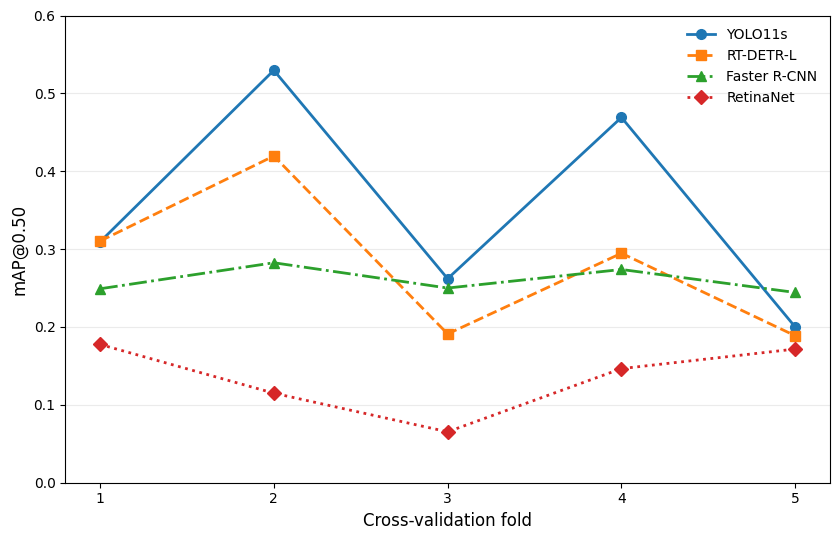

Saved:
/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure1_Foldwise_mAP50.png
/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure1_Foldwise_mAP50.pdf


In [ ]:


import numpy as np
import matplotlib.pyplot as plt

folds = np.arange(1, 6)

results = {
    "YOLO11s": [
        0.309315,
        0.529625,
        0.262025,
        0.469117,
        0.199936
    ],

    "RT-DETR-L": [
        0.310286,
        0.419592,
        0.191120,
        0.294693,
        0.188727
    ],

    "Faster R-CNN": [
        0.249069,
        0.282479,
        0.250011,
        0.273838,
        0.244315
    ],

    "RetinaNet": [
        0.177610,
        0.115001,
        0.065381,
        0.146535,
        0.171662
    ],
}

fig, ax = plt.subplots(figsize=(8.5, 5.5))

markers = ["o", "s", "^", "D"]
linestyles = ["-", "--", "-.", ":"]

for (model_name, values), marker, ls in zip(
    results.items(), markers, linestyles
):
    ax.plot(
        folds,
        values,
        marker=marker,
        linestyle=ls,
        linewidth=2,
        markersize=7,
        label=model_name
    )

ax.set_xlabel("Cross-validation fold", fontsize=12)
ax.set_ylabel("mAP@0.50", fontsize=12)

ax.set_xticks(folds)
ax.set_ylim(0, 0.60)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=10)

plt.tight_layout()

png_path = FIG_DIR / "Figure1_Foldwise_mAP50.png"
pdf_path = FIG_DIR / "Figure1_Foldwise_mAP50.pdf"

plt.savefig(png_path, dpi=600, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")

plt.show()

print("Saved:")
print(png_path)
print(pdf_path)

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image


def find_image_by_stem(folder, stem):
    exts = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

    for ext in exts:
        p = folder / f"{stem}{ext}"
        if p.exists():
            return p

    matches = list(folder.glob(stem + ".*"))

    if len(matches):
        return matches[0]

    raise FileNotFoundError(f"Image not found: {stem}")


def load_yolo_gt(label_path, width, height):
    """
    YOLO:
    class x_center y_center width height
    normalized
    """

    boxes = []

    if not label_path.exists():
        return np.empty((0, 4))

    text = label_path.read_text().strip()

    if not text:
        return np.empty((0, 4))

    for line in text.splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts[:5])

        xc *= width
        yc *= height
        bw *= width
        bh *= height

        x1 = xc - bw / 2
        y1 = yc - bh / 2
        x2 = xc + bw / 2
        y2 = yc + bh / 2

        boxes.append([x1, y1, x2, y2])

    return np.asarray(boxes, dtype=float)


def box_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    union = area_a + area_b - inter

    if union <= 0:
        return 0.0

    return inter / union


def greedy_match(gt_boxes, pred_boxes, iou_thr=0.50):

    candidates = []

    for gi, g in enumerate(gt_boxes):
        for pi, p in enumerate(pred_boxes):
            iou = box_iou(g, p)

            if iou >= iou_thr:
                candidates.append((iou, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()
    pairs = []

    for iou, gi, pi in candidates:

        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)

        pairs.append((gi, pi, iou))

    unmatched_gt = [
        i for i in range(len(gt_boxes))
        if i not in matched_gt
    ]

    unmatched_pred = [
        i for i in range(len(pred_boxes))
        if i not in matched_pred
    ]

    return pairs, unmatched_gt, unmatched_pred


def run_prediction(image_path, confidence=0.25):

    r = model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=confidence,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    if r.boxes is None or len(r.boxes) == 0:
        return (
            np.empty((0, 4)),
            np.empty((0,))
        )

    boxes = r.boxes.xyxy.cpu().numpy()
    confs = r.boxes.conf.cpu().numpy()

    return boxes, confs


def analyze_image(image_path, label_dir, confidence=0.25):

    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    label_path = label_dir / f"{image_path.stem}.txt"

    gt = load_yolo_gt(
        label_path,
        width,
        height
    )

    pred, confs = run_prediction(
        image_path,
        confidence=confidence
    )

    pairs, unmatched_gt, unmatched_pred = greedy_match(
        gt,
        pred,
        iou_thr=0.50
    )

    best_iou = 0.0

    if len(gt) and len(pred):

        for g in gt:
            for p in pred:
                best_iou = max(
                    best_iou,
                    box_iou(g, p)
                )

    return {
        "image_path": image_path,
        "image": np.asarray(image),
        "gt": gt,
        "pred": pred,
        "confs": confs,
        "pairs": pairs,
        "unmatched_gt": unmatched_gt,
        "unmatched_pred": unmatched_pred,
        "best_iou": best_iou,
        "tp": len(pairs),
        "fp": len(unmatched_pred),
        "fn": len(unmatched_gt),
    }


def draw_panel(ax, record, panel_letter, subtitle):

    image = record["image"]

    ax.imshow(image)

    gt = record["gt"]
    pred = record["pred"]
    confs = record["confs"]

    matched_gt = {x[0] for x in record["pairs"]}
    matched_pred = {x[1] for x in record["pairs"]}

    # Matched reference annotation: RED
    for gi in matched_gt:

        x1, y1, x2, y2 = gt[gi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="red",
                linewidth=1.8
            )
        )

    # True-positive prediction: GREEN
    for pi in matched_pred:

        x1, y1, x2, y2 = pred[pi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="lime",
                linewidth=1.8
            )
        )

        ax.text(
            x1,
            max(0, y1 - 8),
            f"{confs[pi]:.2f}",
            fontsize=7,
            color="lime",
            bbox=dict(
                facecolor="black",
                alpha=0.55,
                pad=1
            )
        )

    # False negatives: BLUE dashed
    for gi in record["unmatched_gt"]:

        x1, y1, x2, y2 = gt[gi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="deepskyblue",
                linewidth=2,
                linestyle="--"
            )
        )

    # False positives: ORANGE
    for pi in record["unmatched_pred"]:

        x1, y1, x2, y2 = pred[pi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="orange",
                linewidth=1.7
            )
        )

        ax.text(
            x1,
            max(0, y1 - 8),
            f"{confs[pi]:.2f}",
            fontsize=7,
            color="orange",
            bbox=dict(
                facecolor="black",
                alpha=0.55,
                pad=1
            )
        )

    ax.set_title(
        f"({panel_letter}) {subtitle}\n"
        f"TP={record['tp']}, FP={record['fp']}, FN={record['fn']}",
        fontsize=10
    )

    ax.axis("off")

In [ ]:
internal_cases = [
    ("cate1_011", "Predominantly successful"),
    ("cate2_004", "Mixed detection"),
    ("cate1_007", "False-negative dominant"),
    ("cate1_000", "False-positive case"),
]

records = []

for stem, subtitle in internal_cases:

    image_path = find_image_by_stem(
        INTERNAL_IMAGES,
        stem
    )

    record = analyze_image(
        image_path,
        INTERNAL_LABELS,
        confidence=0.25
    )

    records.append(
        (record, subtitle)
    )

    print(
        stem,
        "TP =", record["tp"],
        "FP =", record["fp"],
        "FN =", record["fn"]
    )


fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 7.5)
)

letters = ["a", "b", "c", "d"]

for ax, (record, subtitle), letter in zip(
    axes.ravel(),
    records,
    letters
):

    draw_panel(
        ax,
        record,
        letter,
        subtitle
    )


fig.text(
    0.5,
    0.015,
    "Red: matched reference annotation   |   "
    "Green: matched prediction   |   "
    "Orange: false-positive prediction   |   "
    "Blue dashed: missed reference lesion",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

png_path = FIG_DIR / "Figure2_Internal_Qualitative.png"
pdf_path = FIG_DIR / "Figure2_Internal_Qualitative.pdf"

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print(png_path)
print(pdf_path)

FileNotFoundError: Image not found: cate1_011

In [ ]:
external_records = []

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

image_files = sorted([
    p for p in EXTERNAL_IMAGES.iterdir()
    if p.suffix.lower() in image_extensions
])

print("External images:", len(image_files))


for i, image_path in enumerate(image_files, 1):

    record = analyze_image(
        image_path,
        EXTERNAL_LABELS,
        confidence=0.25
    )

    record["stem"] = image_path.stem

    external_records.append(record)

    if i % 10 == 0:
        print(i, "/", len(image_files))


positive = [
    r for r in external_records
    if len(r["gt"]) > 0
]

negative = [
    r for r in external_records
    if len(r["gt"]) == 0
]

# ---------------------------------------------------------
# A. Best external near-localization
# ---------------------------------------------------------
near_case = max(
    positive,
    key=lambda x: x["best_iou"]
)

# ---------------------------------------------------------
# B. Positive image with no prediction at conf >= 0.25
# ---------------------------------------------------------
positive_no_prediction = [
    r for r in positive
    if len(r["pred"]) == 0
]

if positive_no_prediction:
    missed_case = max(
        positive_no_prediction,
        key=lambda x: len(x["gt"])
    )
else:
    missed_case = max(
        positive,
        key=lambda x: x["fn"]
    )

# ---------------------------------------------------------
# C. Negative image with most false-positive predictions
# ---------------------------------------------------------
negative_fp_case = max(
    negative,
    key=lambda x: x["fp"]
)

# ---------------------------------------------------------
# D. Positive image with high FP burden
# ---------------------------------------------------------
remaining_positive = [
    r for r in positive
    if r["stem"] not in {
        near_case["stem"],
        missed_case["stem"]
    }
]

positive_fp_case = max(
    remaining_positive,
    key=lambda x: (
        x["fp"],
        x["fn"]
    )
)

selected = [
    (
        near_case,
        f"Near-localization; max IoU={near_case['best_iou']:.3f}"
    ),
    (
        missed_case,
        "Positive image with missed lesion(s)"
    ),
    (
        negative_fp_case,
        "Caries-negative image with false positives"
    ),
    (
        positive_fp_case,
        "Positive image with localization errors"
    )
]


print("\nSelected external examples:")

rows = []

for record, subtitle in selected:

    print(
        record["stem"],
        subtitle,
        "| GT =", len(record["gt"]),
        "| Pred =", len(record["pred"]),
        "| TP =", record["tp"],
        "| FP =", record["fp"],
        "| FN =", record["fn"],
        "| Best IoU =", round(record["best_iou"], 4)
    )

    rows.append({
        "image": record["stem"],
        "category": subtitle,
        "GT": len(record["gt"]),
        "Predictions": len(record["pred"]),
        "TP": record["tp"],
        "FP": record["fp"],
        "FN": record["fn"],
        "Best_IoU": record["best_iou"]
    })


selection_df = pd.DataFrame(rows)

selection_csv = (
    FIG_DIR /
    "Figure3_External_Selected_Cases.csv"
)

selection_df.to_csv(
    selection_csv,
    index=False
)

print("\nSaved selection record:")
print(selection_csv)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/images/test'

NameError: name 'selected' is not defined

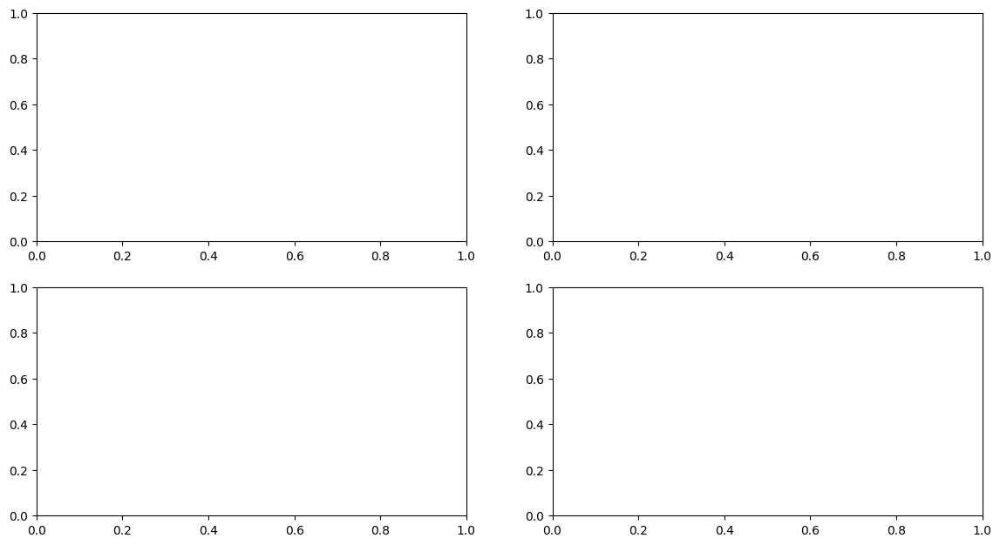

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 7.5)
)

letters = ["a", "b", "c", "d"]

for ax, (record, subtitle), letter in zip(
    axes.ravel(),
    selected,
    letters
):

    draw_panel(
        ax,
        record,
        letter,
        subtitle
    )


fig.text(
    0.5,
    0.015,
    "Red: matched reference annotation   |   "
    "Green: matched prediction   |   "
    "Orange: false-positive prediction   |   "
    "Blue dashed: missed reference lesion",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

png_path = (
    FIG_DIR /
    "Figure3_External_Validation.png"
)

pdf_path = (
    FIG_DIR /
    "Figure3_External_Validation.pdf"
)

plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print(png_path)
print(pdf_path)

In [ ]:
from pathlib import Path
from ultralytics import YOLO

# =========================
# PATHS
# =========================

MODEL_PATH = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/"
    "models/YOLO11s_Caries_Baseline/weights/final_60epochs.pt"
)

DATA_YAML = Path(
    "/content/drive/MyDrive/Pediatric_Caries_AI/"
    "external_validation/MOPG7_66/data.yaml"
)

print("Model exists:", MODEL_PATH.exists())
print("Data YAML exists:", DATA_YAML.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"data.yaml not found: {DATA_YAML}")

# =========================
# LOAD MODEL
# =========================

model = YOLO(str(MODEL_PATH))

# =========================
# EXTERNAL EVALUATION
# =========================

results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=1024,
    conf=0.001,
    iou=0.70,
    max_det=300,
    device=0,
    plots=True,
    verbose=True
)

print("\n===== EXTERNAL RESULTS =====")

print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP@0.50:", results.box.map50)
print("mAP@0.50:0.95:", results.box.map)

Model exists: False
Data YAML exists: False


FileNotFoundError: Model not found: /content/drive/MyDrive/Pediatric_Caries_AI/models/YOLO11s_Caries_Baseline/weights/final_60epochs.pt

In [ ]:
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Pediatric_Caries_AI/models/YOLO11s_Caries_Baseline/weights/final_60epochs.pt"),
    Path("/content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline"),
    Path("/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66"),
]

for p in paths:
    print(p)
    print("EXISTS =", p.exists())
    print()

/content/drive/MyDrive/Pediatric_Caries_AI/models/YOLO11s_Caries_Baseline/weights/final_60epochs.pt
EXISTS = False

/content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline
EXISTS = False

/content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66
EXISTS = False



In [ ]:
from pathlib import Path

ROOT = Path("/content")

patterns = [
    "*caries*",
    "*yolo*",
    "*mopg*",
    "*weight*",
    "*best.pt",
    "*last.pt",
    "*.pt",
    "*data.yaml",
]

for pattern in patterns:
    print("\n" + "="*70)
    print("PATTERN:", pattern)
    print("="*70)

    found = list(ROOT.rglob(pattern))

    if not found:
        print("NOT FOUND")
        continue

    for i, p in enumerate(found[:200]):
        print(i, p)


PATTERN: *caries*
NOT FOUND

PATTERN: *yolo*
NOT FOUND

PATTERN: *mopg*
NOT FOUND

PATTERN: *weight*
NOT FOUND

PATTERN: *best.pt
NOT FOUND

PATTERN: *last.pt
NOT FOUND

PATTERN: *.pt
NOT FOUND

PATTERN: *data.yaml
NOT FOUND


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

print("===== TOP LEVEL =====")

for p in sorted(ROOT.iterdir()):
    print("[DIR]" if p.is_dir() else "[FILE]", p)

print("\n===== SECOND LEVEL =====")

for p in sorted(ROOT.iterdir()):
    if p.is_dir():
        try:
            for q in sorted(p.iterdir()):
                print("[DIR]" if q.is_dir() else "[FILE]", q)
        except:
            pass

===== TOP LEVEL =====
[DIR] /content/drive/MyDrive/Pediatric_Caries_AI

===== SECOND LEVEL =====
[DIR] /content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures


In [ ]:
from google.colab import drive

drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.


ValueError: Mountpoint must not already contain files

In [ ]:
import os
import shutil
from google.colab import drive

MOUNT = "/content/drive"

print("Is mounted:", os.path.ismount(MOUNT))

# إذا لم يكن Drive مربوطًا فعليًا، احذف فقط مجلد الربط المحلي القديم
if not os.path.ismount(MOUNT):
    if os.path.exists(MOUNT):
        print("Removing stale local mount directory...")
        shutil.rmtree(MOUNT)

    os.makedirs(MOUNT, exist_ok=True)

print("Mount directory prepared.")

drive.mount(MOUNT, force_remount=True)

Is mounted: False
Removing stale local mount directory...
Mount directory prepared.
Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

print("MyDrive exists:", ROOT.exists())

print("\nTop-level folders:")
for p in sorted(ROOT.iterdir()):
    print(p.name)

MyDrive exists: True

Top-level folders:
BeyondRound.gsheet
Classic Resume #12851.gslides
Classroom
Colab Notebooks
Copy of ⁨الـ 105 نموذج الإصدار الثاني - كمي - .pdf⁩.pdf
Email.gsheet
File conversion to slides.gslides
File.pdf
Google AI Studio
Graph Solution
JAVASCRIPT OOP CONCEPT CLEARLY EXPLAINED -1.pdf
MyDrive
MyDrive.gprj
Opal
Pediatric_Caries_AI
Python Web Fundamentals
Qassim Dates Phase 1 Redesigned.gslides
Screenshot 2024-11-11 211251.png
Untitled document.gdoc
class02-materials.zip
تطوير تطبيقات Full-Stack في Google AI Studio (1).gslides
تطوير تطبيقات Full-Stack في Google AI Studio.gslides
عرس الصبري


In [ ]:
models = list(ROOT.rglob("*.pt"))

print("\nPT models found:", len(models))

for i, p in enumerate(models):
    print(i, p)


PT models found: 66
0 /content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt
1 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/checkpoints/RTDETR/fold_3/last.pt
2 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/checkpoints/RTDETR/fold_3/best.pt
3 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_1/best.pt
4 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_2/best.pt
5 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_3/best.pt
6 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_4/best.pt
7 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/RetinaNet/fold_5/best.pt
8 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/FasterRCNN/fold_1/best.pt
9 /content/drive/MyDrive/Pediatric_Caries_AI/cross_validation/models/FasterRCNN/fold_2/best.pt
10 /content/drive/MyDrive/Pediatric_Ca

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

print("Searching for MOPG-7...")

for p in ROOT.rglob("MOPG-7"):
    if p.is_dir():
        print("FOUND:", p)

print("\nSearching for 01_raw_selected...")

for p in ROOT.rglob("01_raw_selected"):
    if p.is_dir():
        print("FOUND:", p)

Searching for MOPG-7...
FOUND: /content/drive/MyDrive/MyDrive/MOPG-7

Searching for 01_raw_selected...
FOUND: /content/drive/MyDrive/MyDrive/MOPG-7/01_raw_selected


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

MODEL_PATH = PROJECT_DIR / "final_model" / "YOLO11s_Final" / "final_60epochs.pt"
BASELINE_YAML = PROJECT_DIR / "processed_data" / "yolo_caries_baseline" / "data.yaml"
EXTERNAL_YAML = PROJECT_DIR / "external_validation" / "MOPG7_66" / "data.yaml"
FIG_DIR = PROJECT_DIR / "manuscript_final_figures"

FIG_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("MODEL_PATH exists:", MODEL_PATH.exists(), MODEL_PATH)
print("BASELINE_YAML exists:", BASELINE_YAML.exists(), BASELINE_YAML)
print("EXTERNAL_YAML exists:", EXTERNAL_YAML.exists(), EXTERNAL_YAML)
print("FIG_DIR:", FIG_DIR)

PROJECT_DIR: /content/drive/MyDrive/Pediatric_Caries_AI
MODEL_PATH exists: True /content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt
BASELINE_YAML exists: True /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/data.yaml
EXTERNAL_YAML exists: True /content/drive/MyDrive/Pediatric_Caries_AI/external_validation/MOPG7_66/data.yaml
FIG_DIR: /content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures


In [ ]:
!pip -q install ultralytics

from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))
print("✅ Model loaded successfully")

✅ Model loaded successfully


In [ ]:
internal_results = model.val(
    data=str(BASELINE_YAML),
    split="test",
    imgsz=1024,
    device=0
)

print("\nINTERNAL TEST RESULTS")
print("Precision   :", internal_results.box.mp)
print("Recall      :", internal_results.box.mr)
print("mAP@0.50    :", internal_results.box.map50)
print("mAP@0.50:95 :", internal_results.box.map)

Ultralytics 8.4.140 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.6±1.3 ms, read: 1.6±0.5 MB/s, size: 990.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Pediatric_Caries_AI/processed_data/yolo_caries_baseline/labels/test.cache... 30 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 4.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 9.4s/it 18.9s
                   all         30        108      0.428      0.602      0.459      0.247
Speed: 9.4ms preprocess, 23.0ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val

INTERNAL TEST RESULTS
Precision   : 0.42771291562946634
Recall     

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from ultralytics import YOLO

PROJECT = Path("/content/drive/MyDrive/Pediatric_Caries_AI")

MODEL_PATH = PROJECT / "final_model" / "YOLO11s_Final" / "final_60epochs.pt"

INTERNAL_ROOT = PROJECT / "processed_data" / "yolo_caries_baseline"
INTERNAL_IMAGES = INTERNAL_ROOT / "images" / "test"
INTERNAL_LABELS = INTERNAL_ROOT / "labels" / "test"

EXTERNAL_ROOT = PROJECT / "external_validation" / "MOPG7_66"
EXTERNAL_IMAGES = EXTERNAL_ROOT / "images" / "test"
EXTERNAL_LABELS = EXTERNAL_ROOT / "labels" / "test"

FIG_DIR = PROJECT / "manuscript_final_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("MODEL:", MODEL_PATH.exists(), MODEL_PATH)
print("INTERNAL_IMAGES:", INTERNAL_IMAGES.exists())
print("INTERNAL_LABELS:", INTERNAL_LABELS.exists())
print("EXTERNAL_IMAGES:", EXTERNAL_IMAGES.exists())
print("EXTERNAL_LABELS:", EXTERNAL_LABELS.exists())
print("FIG_DIR:", FIG_DIR)

model = YOLO(str(MODEL_PATH))
print("✅ Model loaded")

MODEL: True /content/drive/MyDrive/Pediatric_Caries_AI/final_model/YOLO11s_Final/final_60epochs.pt
INTERNAL_IMAGES: True
INTERNAL_LABELS: True
EXTERNAL_IMAGES: True
EXTERNAL_LABELS: True
FIG_DIR: /content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures
✅ Model loaded


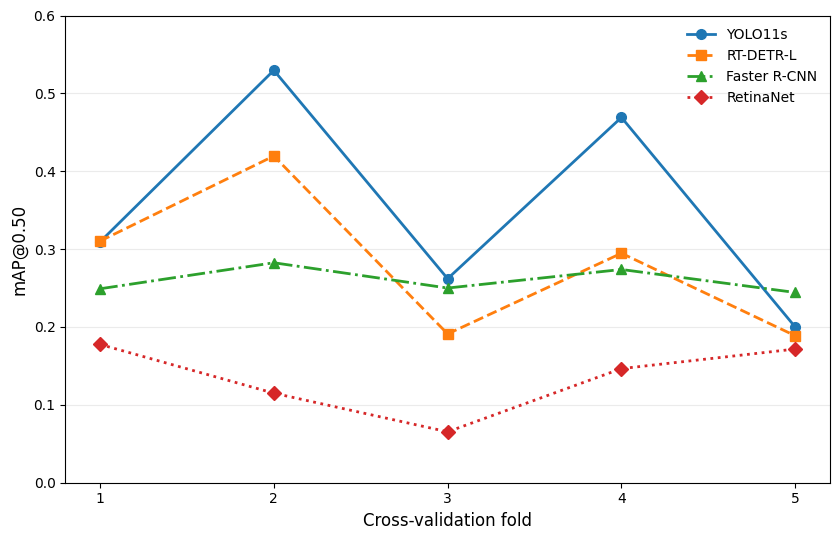

/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure1_Foldwise_mAP50.png
/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure1_Foldwise_mAP50.pdf


In [ ]:
folds = np.arange(1, 6)

results = {
    "YOLO11s": [
        0.309315,
        0.529625,
        0.262025,
        0.469117,
        0.199936
    ],
    "RT-DETR-L": [
        0.310286,
        0.419592,
        0.191120,
        0.294693,
        0.188727
    ],
    "Faster R-CNN": [
        0.249069,
        0.282479,
        0.250011,
        0.273838,
        0.244315
    ],
    "RetinaNet": [
        0.177610,
        0.115001,
        0.065381,
        0.146535,
        0.171662
    ],
}

fig, ax = plt.subplots(figsize=(8.5, 5.5))

markers = ["o", "s", "^", "D"]
linestyles = ["-", "--", "-.", ":"]

for (name, vals), marker, ls in zip(results.items(), markers, linestyles):
    ax.plot(
        folds,
        vals,
        marker=marker,
        linestyle=ls,
        linewidth=2,
        markersize=7,
        label=name
    )

ax.set_xlabel("Cross-validation fold", fontsize=12)
ax.set_ylabel("mAP@0.50", fontsize=12)
ax.set_xticks(folds)
ax.set_ylim(0, 0.60)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()

png_path = FIG_DIR / "Figure1_Foldwise_mAP50.png"
pdf_path = FIG_DIR / "Figure1_Foldwise_mAP50.pdf"

plt.savefig(png_path, dpi=600, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

print(png_path)
print(pdf_path)

In [ ]:
def find_image_by_stem(folder, stem):
    extensions = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

    for ext in extensions:
        p = folder / f"{stem}{ext}"
        if p.exists():
            return p

    matches = list(folder.glob(stem + ".*"))
    if matches:
        return matches[0]

    raise FileNotFoundError(stem)


def load_yolo_gt(label_path, img_w, img_h):
    boxes = []

    if not label_path.exists():
        return np.empty((0, 4))

    text = label_path.read_text().strip()

    if not text:
        return np.empty((0, 4))

    for line in text.splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts[:5])

        xc *= img_w
        yc *= img_h
        bw *= img_w
        bh *= img_h

        x1 = xc - bw / 2
        y1 = yc - bh / 2
        x2 = xc + bw / 2
        y2 = yc + bh / 2

        boxes.append([x1, y1, x2, y2])

    return np.asarray(boxes, dtype=float)


def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter

    return 0 if union <= 0 else inter / union


def greedy_match(gt_boxes, pred_boxes, iou_thr=0.50):
    candidates = []

    for gi, gt in enumerate(gt_boxes):
        for pi, pred in enumerate(pred_boxes):
            score = iou(gt, pred)

            if score >= iou_thr:
                candidates.append((score, gi, pi))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()
    pairs = []

    for score, gi, pi in candidates:
        if gi in matched_gt or pi in matched_pred:
            continue

        matched_gt.add(gi)
        matched_pred.add(pi)
        pairs.append((gi, pi, score))

    unmatched_gt = [
        i for i in range(len(gt_boxes))
        if i not in matched_gt
    ]

    unmatched_pred = [
        i for i in range(len(pred_boxes))
        if i not in matched_pred
    ]

    return pairs, unmatched_gt, unmatched_pred


def predict_image(image_path, conf=0.25):
    result = model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=conf,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        return np.empty((0, 4)), np.empty((0,))

    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy()

    return boxes, confs


def analyze_image(image_path, label_dir, conf=0.25):
    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    gt_path = label_dir / f"{image_path.stem}.txt"
    gt_boxes = load_yolo_gt(gt_path, w, h)

    pred_boxes, confs = predict_image(image_path, conf=conf)

    pairs, unmatched_gt, unmatched_pred = greedy_match(
        gt_boxes,
        pred_boxes,
        iou_thr=0.50
    )

    best_iou = 0.0

    for gt in gt_boxes:
        for pred in pred_boxes:
            best_iou = max(best_iou, iou(gt, pred))

    return {
        "image_path": image_path,
        "image": np.asarray(image),
        "gt": gt_boxes,
        "pred": pred_boxes,
        "confs": confs,
        "pairs": pairs,
        "unmatched_gt": unmatched_gt,
        "unmatched_pred": unmatched_pred,
        "best_iou": best_iou,
        "tp": len(pairs),
        "fp": len(unmatched_pred),
        "fn": len(unmatched_gt)
    }


def draw_panel(ax, record, letter, subtitle):
    ax.imshow(record["image"])

    gt = record["gt"]
    pred = record["pred"]
    confs = record["confs"]

    matched_gt = {x[0] for x in record["pairs"]}
    matched_pred = {x[1] for x in record["pairs"]}

    # matched reference: red
    for gi in matched_gt:
        x1, y1, x2, y2 = gt[gi]
        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="red",
                linewidth=1.8
            )
        )

    # matched prediction: green
    for pi in matched_pred:
        x1, y1, x2, y2 = pred[pi]
        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="lime",
                linewidth=1.8
            )
        )

        ax.text(
            x1,
            max(0, y1-8),
            f"{confs[pi]:.2f}",
            fontsize=7,
            color="lime",
            bbox=dict(facecolor="black", alpha=0.5, pad=1)
        )

    # false negatives: blue dashed
    for gi in record["unmatched_gt"]:
        x1, y1, x2, y2 = gt[gi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="deepskyblue",
                linewidth=2,
                linestyle="--"
            )
        )

    # false positives: orange
    for pi in record["unmatched_pred"]:
        x1, y1, x2, y2 = pred[pi]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="orange",
                linewidth=1.7
            )
        )

        ax.text(
            x1,
            max(0, y1-8),
            f"{confs[pi]:.2f}",
            fontsize=7,
            color="orange",
            bbox=dict(facecolor="black", alpha=0.5, pad=1)
        )

    ax.set_title(
        f"({letter}) {subtitle}\n"
        f"TP={record['tp']}, FP={record['fp']}, FN={record['fn']}",
        fontsize=10
    )

    ax.axis("off")

cate1_011 TP= 6 FP= 0 FN= 2
cate2_004 TP= 4 FP= 1 FN= 1
cate1_007 TP= 0 FP= 1 FN= 9
cate1_000 TP= 0 FP= 3 FN= 0


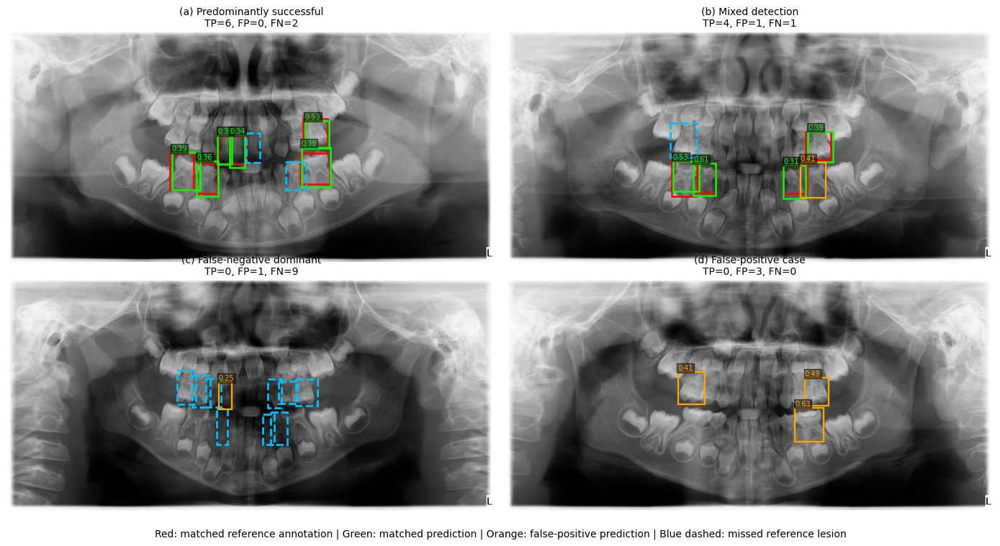

/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure2_Internal_Qualitative.png
/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure2_Internal_Qualitative.pdf


In [ ]:
internal_cases = [
    ("cate1_011", "Predominantly successful"),
    ("cate2_004", "Mixed detection"),
    ("cate1_007", "False-negative dominant"),
    ("cate1_000", "False-positive case")
]

records = []

for stem, subtitle in internal_cases:
    image_path = find_image_by_stem(
        INTERNAL_IMAGES,
        stem
    )

    rec = analyze_image(
        image_path,
        INTERNAL_LABELS,
        conf=0.25
    )

    records.append((rec, subtitle))

    print(
        stem,
        "TP=", rec["tp"],
        "FP=", rec["fp"],
        "FN=", rec["fn"]
    )


fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))

letters = ["a", "b", "c", "d"]

for ax, (rec, subtitle), letter in zip(
    axes.ravel(),
    records,
    letters
):
    draw_panel(
        ax,
        rec,
        letter,
        subtitle
    )

fig.text(
    0.5,
    0.015,
    "Red: matched reference annotation | "
    "Green: matched prediction | "
    "Orange: false-positive prediction | "
    "Blue dashed: missed reference lesion",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

png_path = FIG_DIR / "Figure2_Internal_Qualitative.png"
pdf_path = FIG_DIR / "Figure2_Internal_Qualitative.pdf"

plt.savefig(png_path, dpi=600, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

print(png_path)
print(pdf_path)

In [ ]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

external_files = sorted([
    p for p in EXTERNAL_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
])

print("External images:", len(external_files))

external_records = []

for i, image_path in enumerate(external_files, 1):

    rec = analyze_image(
        image_path,
        EXTERNAL_LABELS,
        conf=0.25
    )

    rec["stem"] = image_path.stem

    external_records.append(rec)

    if i % 10 == 0:
        print(i, "/", len(external_files))

External images: 66
10 / 66
20 / 66
30 / 66
40 / 66
50 / 66
60 / 66


In [ ]:
positive = [
    r for r in external_records
    if len(r["gt"]) > 0
]

negative = [
    r for r in external_records
    if len(r["gt"]) == 0
]

# A: best near-localization
near_case = max(
    positive,
    key=lambda r: r["best_iou"]
)

# B: strongest missed positive case
positive_no_pred = [
    r for r in positive
    if len(r["pred"]) == 0
]

if positive_no_pred:
    missed_case = max(
        positive_no_pred,
        key=lambda r: len(r["gt"])
    )
else:
    missed_case = max(
        positive,
        key=lambda r: r["fn"]
    )

# C: negative image with most false positives
negative_fp_case = max(
    negative,
    key=lambda r: r["fp"]
)

# D: positive image with many false positives
remaining = [
    r for r in positive
    if r["stem"] not in {
        near_case["stem"],
        missed_case["stem"]
    }
]

positive_fp_case = max(
    remaining,
    key=lambda r: (r["fp"], r["fn"])
)

selected = [
    (
        near_case,
        f"Near-localization; max IoU={near_case['best_iou']:.3f}"
    ),
    (
        missed_case,
        "Caries-positive image with missed lesion(s)"
    ),
    (
        negative_fp_case,
        "Caries-negative image with false positives"
    ),
    (
        positive_fp_case,
        "Positive image with localization errors"
    )
]

print("\nSelected cases:")

for rec, title in selected:
    print(
        rec["stem"],
        "|", title,
        "| GT=", len(rec["gt"]),
        "| Pred=", len(rec["pred"]),
        "| TP=", rec["tp"],
        "| FP=", rec["fp"],
        "| FN=", rec["fn"],
        "| Best IoU=", round(rec["best_iou"], 4)
    )


Selected cases:
0000837 | Near-localization; max IoU=0.183 | GT= 1 | Pred= 1 | TP= 0 | FP= 1 | FN= 1 | Best IoU= 0.1834
0000287 | Caries-positive image with missed lesion(s) | GT= 4 | Pred= 0 | TP= 0 | FP= 0 | FN= 4 | Best IoU= 0.0
00001209 | Caries-negative image with false positives | GT= 0 | Pred= 8 | TP= 0 | FP= 8 | FN= 0 | Best IoU= 0.0
0000121 | Positive image with localization errors | GT= 1 | Pred= 4 | TP= 0 | FP= 4 | FN= 1 | Best IoU= 0.0


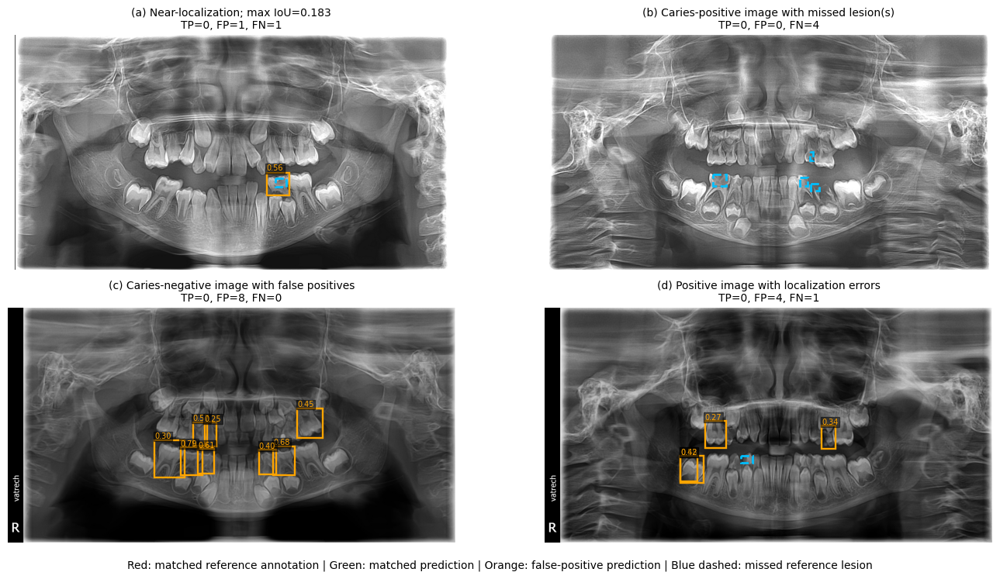

/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure3_External_Validation.png
/content/drive/MyDrive/Pediatric_Caries_AI/manuscript_final_figures/Figure3_External_Validation.pdf


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))

letters = ["a", "b", "c", "d"]

for ax, (rec, subtitle), letter in zip(
    axes.ravel(),
    selected,
    letters
):
    draw_panel(
        ax,
        rec,
        letter,
        subtitle
    )

fig.text(
    0.5,
    0.015,
    "Red: matched reference annotation | "
    "Green: matched prediction | "
    "Orange: false-positive prediction | "
    "Blue dashed: missed reference lesion",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

png_path = FIG_DIR / "Figure3_External_Validation.png"
pdf_path = FIG_DIR / "Figure3_External_Validation.pdf"

plt.savefig(png_path, dpi=600, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

print(png_path)
print(pdf_path)